# Ноутбук 1. Математический и вычислительный инструментарий асимметричной криптографии

## Интенсивная актуализация предварительных знаний для магистерского курса

Этот ноутбук **не является вводным курсом элементарной теории чисел**. Предполагается, что студент уже изучал делимость, сравнения, НОД и алгоритм Евклида в бакалавриате, а также владеет базовыми методами математического доказательства. 

Здесь мы собираем именно тот математический и вычислительный инструментарий, который далее будет без повторного объяснения использоваться в RSA, Диффи—Хеллмане, Эль-Гамале, конечных полях и криптографии на эллиптических кривых.

К концу ноутбука должны быть доступны операции

$$
a^{-1}\pmod n,\qquad a^e\pmod n,\qquad \operatorname{CRT}(\ldots),
$$

а также проверенные реализации `gcd`, `extended_gcd`, `solve_linear_diophantine`, `mod_inverse`, `solve_linear`, `mod_pow`, `crt`, `garner_crt`.

Для ключевых результатов используем сквозную схему:

$$
\boxed{
\text{математический результат}
\to
\text{конструкция}
\to
\text{алгоритм}
\to
\text{корректность}
\to
\text{сложность}
\to
\text{криптографическое применение}.
}
$$

В вычислительных блоках отдельно различаем **доказательство корректности**, **тестирование реализации** и **эксперимент**: доказательство устанавливает свойство для всех допустимых входов; тесты помогают обнаруживать ошибки конкретного кода; эксперимент позволяет увидеть закономерность и сформулировать гипотезу. Даже большое число успешных тестов не заменяет доказательство корректности.


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #7653a6;">

### 🧩 Цель актуализации предварительных знаний

Собрать компактный арифметический инструментарий:

```text
crypto_math/
└── number_theory.py
    ├── divides()
    ├── gcd()
    ├── extended_gcd()
    ├── solve_linear_diophantine()
    ├── mod_inverse()
    ├── solve_linear()
    ├── mod_pow()
    ├── crt()
    └── garner_crt()
```

Для каждой основной операции нас интересуют:

- **контракт**: допустимые входы и математическое постусловие;
- **инвариант или конструктивная теорема**, обеспечивающие корректность;
- **стоимость вычисления**, измеряемая относительно размера входа;
- **проверка свойств** на случайных данных;
- место операции в последующих криптографических конструкциях.

</div>


### Терминологическое соглашение

Основной язык курса — русский. Для понятий, имеющих устойчивый русский академический эквивалент, используется русский термин. При **первом содержательном упоминании** рядом в скобках приводится распространённый английский термин — это облегчает поиск англоязычных учебников, статей, стандартов и документации.

Например:

- **сравнение по модулю** (*congruence modulo*);
- **наибольший общий делитель, НОД** (*greatest common divisor, GCD*);
- **расширенный алгоритм Евклида** (*extended Euclidean algorithm*);
- **обратный элемент по модулю** (*modular multiplicative inverse*);
- **быстрое модульное возведение в степень** (*fast modular exponentiation*);
- **китайская теорема об остатках, КТО** (*Chinese Remainder Theorem, CRT*);
- **инвариант цикла** (*loop invariant*);
- **битовая длина** (*bit length*);
- **сложность по битовым операциям** (*bit complexity*).

Имена функций Python (`gcd`, `extended_gcd`, `mod_inverse`, `mod_pow`, `crt`) не переводятся: это элементы программного интерфейса, а не терминология математического текста.


## 1.1. Криптографическая карта вычислений

В следующих разделах курса нам понадобятся:

- Диффи—Хеллман и Эль-Гамаль: $g^x\bmod p$;
- RSA: $m^e\bmod n$, обратимые элементы и реконструкция по КТО;
- конечные поля: деление как умножение на обратный элемент;
- криптография на эллиптических кривых: аналогичная идея быстрого умножения скаляра, но уже в группе точек.

Поэтому основной вопрос здесь не «что такое остаток?», а:

> какие арифметические операции должны быть математически корректны и вычислительно пригодны для чисел длиной 256–4096 бит?

Эта постановка требует различать числовую величину входа и **размер его представления**. Для целых чисел размер входа естественно измеряется битовой длиной.


## 1.2. Сравнения и арифметика классов вычетов — краткое повторение

Фиксируем обозначения, которые далее используются без пояснений.

### Определение 1.1. Делимость

Пусть $a,b\in\mathbb Z$. Говорят, что $a$ **делит** $b$ (пишут $a\mid b$), если существует $k\in\mathbb Z$ такое, что $b=ak$; иначе пишут $a\nmid b$. Число $a$ называется **делителем** (*divisor*) числа $b$, а $b$ — **кратным** (*multiple*) числа $a$.

Отметим крайний случай, важный для программного контракта: $0\mid b$ тогда и только тогда, когда $b=0$.

### Определение 1.2. Сравнение по модулю

Пусть $n\ge 2$ и $a,b\in\mathbb Z$. Числа $a$ и $b$ **сравнимы по модулю $n$** (*congruent modulo $n$*), если $n\mid(a-b)$:

$$
a\equiv b\pmod n.
\tag{1.1}
$$

Эквивалентно, существует $q\in\mathbb Z$ такое, что

$$
a=b+qn,
\tag{1.2}
$$

то есть $a$ и $b$ дают одинаковый остаток при делении на $n$. Сравнимость по модулю $n$ — отношение эквивалентности на $\mathbb Z$.

### Определение 1.3. Класс вычетов

**Классом вычетов числа $a$ по модулю $n$** (*residue class modulo $n$*) называется множество

$$
[a]_n=\{\,b\in\mathbb Z:\ b\equiv a\pmod n\,\}
\tag{1.3}
$$

$$
=a+n\mathbb Z=\{\,a+kn:\ k\in\mathbb Z\,\}.
\tag{1.4}
$$

Например, $[2]_5=\{\ldots,-8,-3,2,7,12,\ldots\}$, поэтому

$$
[2]_5=[7]_5=[-3]_5.
\tag{1.5}
$$

Вообще,

$$
[a]_n=[b]_n\iff a\equiv b\pmod n.
\tag{1.6}
$$

Множество классов вычетов обозначается

$$
\mathbb Z/n\mathbb Z
\tag{1.7}
$$

и состоит ровно из $n$ классов:

$$
\mathbb Z/n\mathbb Z=\{[0]_n,[1]_n,\ldots,[n-1]_n\}.
\tag{1.8}
$$

Число из $\{0,1,\ldots,n-1\}$, лежащее в классе, называется **наименьшим неотрицательным представителем** (*least nonnegative representative*); в Python при $n>0$ его даёт выражение `a % n`.

Полезно различать три уровня: целое число $a\in\mathbb Z$, класс $[a]_n\in\mathbb Z/n\mathbb Z$ и выбранный представитель класса (например, `a % n`). В коде эти уровни обычно отождествляют, в доказательствах — нет.

### Арифметика классов вычетов

Операции определяются через представителей:

$$
[a]_n+[b]_n=[a+b]_n,
\tag{1.9}
$$

$$
[a]_n[b]_n=[ab]_n.
\tag{1.10}
$$

Определение корректно (*well-defined*), то есть не зависит от выбора представителей: если $a\equiv a'$ и $b\equiv b'\pmod n$, то

$$
a+b\equiv a'+b'\pmod n,
\tag{1.11}
$$

$$
ab\equiv a'b'\pmod n.
\tag{1.12}
$$

Именно свойства (1.11)–(1.12) позволяют заменять большие целые их представителями по модулю $n$ **до** выполнения дальнейших сложений и умножений.


In [1]:
def divides(a: int, b: int) -> bool:
    """Контракт: возвращает True тогда и только тогда, когда a | b (Определение 1.1).

    Крайний случай: 0 | b  <=>  b == 0.
    """
    if a == 0:
        return b == 0
    return b % a == 0


assert divides(3, 12) and divides(-3, 12) and divides(3, -12)
assert not divides(5, 12)
assert divides(7, 0)                        # любое число делит 0
assert divides(0, 0) and not divides(0, 5)  # 0 делит только 0
# Связь с Определением 1.2: a ≡ b (mod n)  <=>  n | (a - b)
assert divides(12, 17 - 5)


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #3a8f5c;">

### Пример 1.1. Редукция во время вычисления

Чтобы вычислить

$$
123456789^{10^6}\pmod{1009},
$$

не нужно строить само число $123456789^{10^6}$: в нём около 8 миллионов десятичных цифр. Благодаря совместимости сравнения с умножением, формула (1.12), редукцию можно выполнять после **каждого** умножения, и все промежуточные значения остаются меньше $1009$. Сначала можно заменить и само основание его представителем: $123456789\equiv 594\pmod{1009}$. Итог: $123456789^{10^6}\equiv 628\pmod{1009}$.

Эта идея — фундамент всех дальнейших вычислений: в §1.6 она вместе с двоичной записью показателя даст быстрое модульное возведение в степень.

</div>

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #3a8f5c;">

### Пример 1.2. Как получить целое число ровно из 512 бит

Для криптографических экспериментов важно контролировать не только верхнюю границу числа, но и его **битовую длину**.

Для положительного целого $n$ битовая длина равна

$$
\ell(n)=\lfloor\log_2 n\rfloor+1.
$$

Эквивалентно,

$$
2^{\ell(n)-1}\le n<2^{\ell(n)}.
$$

В Python значение $\ell(n)$ возвращает метод `n.bit_length()`.

Для генерации случайных значений используем модуль `secrets`:

```python
import secrets

n = secrets.randbits(512)

# Гарантируем, что число действительно 512-битное:
n |= (1 << 511)

print(n.bit_length())
```

Последняя строка гарантированно выведет

```text
512
```

Одного вызова `secrets.randbits(512)` недостаточно: он возвращает случайное целое в диапазоне

$$
0\le n<2^{512},
$$

поэтому старшие биты случайно могут оказаться нулевыми.

Операция

```python
n |= (1 << 511)
```

устанавливает старший бит в `1`, поэтому

$$
2^{511}\le n<2^{512}.
$$

#### Размер входа и сложность

В криптографии сложность алгоритма оценивают относительно **размера представления входа**, а не только относительно числовой величины входного числа. Обозначим через $L=\ell(n)$ битовую длину числа $n$ (см. формулу выше). Тогда $2^{L-1}\le n<2^L$, то есть $n$ имеет порядок $2^L$. Поэтому алгоритм, выполняющий $O(n)$ шагов, требует порядка

$$
O(2^L)
$$

шагов относительно битовой длины входа.

В этом ноутбуке будем различать два уровня оценки:

- **арифметическая сложность** — число делений, умножений или других операций над целыми числами;
- **сложность по битовым операциям** — учитывает, что одна операция над длинными числами сама имеет ненулевую стоимость.

Например, если $M(L)$ обозначает стоимость умножения двух $L$-битных чисел, то фраза «$O(L)$ умножений» ещё не означает $O(L)$ битовых операций.

На этом этапе нам достаточно уметь чётко различать эти два уровня. Более точные оценки появятся там, где они влияют на выбор криптографических параметров.

</div>


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Практика. Не вычисляйте больше, чем нужно

1. Предскажите, совпадут ли два результата ниже.
2. Сгенерируйте несколько пар **ровно 512-битных** целых `a, b`, используя приём из примера 1.2, и проверьте предсказание.
3. Объясните совпадение через формулы (1.11)–(1.12), а не через особенности Python.
4. Сформулируйте, почему ранняя редукция критична при вычислении больших степеней.

</div>

In [1]:
import secrets

def random_exact_bits(bits: int) -> int:
    """Возвращает положительное целое ровно заданной битовой длины."""
    if bits < 1:
        raise ValueError("bits должно быть положительным")

    n = secrets.randbits(bits)
    n |= 1 << (bits - 1)
    return n


# Пример: две случайные величины ровно по 512 бит.
a = random_exact_bits(512)
b = random_exact_bits(512)

assert a.bit_length() == 512
assert b.bit_length() == 512

print("a.bit_length() =", a.bit_length())
print("b.bit_length() =", b.bit_length())

# Выберите модуль n > 0 и сравните:
# ((a % n) * (b % n)) % n
# (a * b) % n

# Выполните задания здесь

# Генерируем два огромных 512-битных числа
a = random_exact_bits(512)
b = random_exact_bits(512)

# Задаем модуль (любое положительное число, например, 1009)
n = 1009

res1 = ((a % n) * (b % n)) % n
res2 = (a * b) % n

print(f"Результат 1: {res1}")
print(f"Результат 2: {res2}")
print(f"Совпадают ли: {res1 == res2}")

a.bit_length() = 512
b.bit_length() = 512
Результат 1: 958
Результат 2: 958
Совпадают ли: True


### Определение 1.4. Полная система вычетов

Набор из $n$ целых чисел $r_0,r_1,\ldots,r_{n-1}$ называется **полной системой вычетов по модулю $n$** (*complete residue system modulo $n$*), если каждое целое число сравнимо по модулю $n$ ровно с одним из этих чисел.

Эквивалентно, классы $[r_0]_n,\ldots,[r_{n-1}]_n$ попарно различны и исчерпывают $\mathbb Z/n\mathbb Z$.

Стандартный пример — $0,1,\ldots,n-1$, но представители могут быть любыми, в том числе отрицательными.

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.1. Полная система вычетов

Образуют ли числа
$$-16,\ 17,\ -6,\ 27,\ -20,\ 13,\ -2,\ 23$$
полную систему вычетов по модулю $8$?

Проверьте ответ вручную, приведя числа к наименьшим неотрицательным представителям, а затем программно с помощью `%`.

</div>

In [ ]:
# Ваше решение:
numbers = [-16, 17, -6, 27, -20, 13, -2, 23]
n = 8
remainders = []

for x in numbers:
    r = (x % n + n) % n 
    remainders.append(r)

print(f"Остатки: {remainders}")

# Проверяем, что остатки не повторяются и их количество равно n
if len(set(remainders)) == n:
    print("Да, это полная система вычетов!")
else:
    print("Нет, есть повторяющиеся остатки.")

Остатки: [0, 1, 2, 3, 4, 5, 6, 7]
Да, это полная система вычетов!


## 1.3. НОД и алгоритм Евклида — повторение через инвариант

### Определение 1.5. Наибольший общий делитель

Пусть $a,b\in\mathbb Z$, причём $a$ и $b$ не равны нулю одновременно. **Наибольшим общим делителем** (*greatest common divisor, GCD*) чисел $a,b$ называется положительное целое число $d=\gcd(a,b)$, такое что
$$d\mid a,\qquad d\mid b,$$
и любой общий делитель $c$ чисел $a,b$ делит $d$:
$$c\mid a,\ c\mid b\Longrightarrow c\mid d.$$

Используем соглашения $\gcd(a,b)\ge0$ и $\gcd(a,0)=|a|$.

### Определение 1.6. Взаимно простые числа

Числа $a,b$ называются **взаимно простыми** (*coprime, relatively prime*), если
$$\gcd(a,b)=1.$$

Ключевой инвариант алгоритма Евклида:
$$\gcd(a,b)=\gcd(b,a\bmod b),\qquad b\ne0. \tag{1.13}$$

```python
def gcd(a: int, b: int) -> int:
    if a == 0 and b == 0:
        raise ValueError("gcd(0, 0) is undefined by the course convention")
    a, b = abs(a), abs(b)
    while b != 0:
        a, b = b, a % b
    return a
```

### Паспорт алгоритма `gcd`

**Контракт.** Вход: $a,b\in\mathbb Z$, не равные нулю одновременно. Выход: положительное число $d$, для которого

$$
d=\gcd(a,b).
$$

**Корректность.** На каждом шаге сохраняется НОД пары благодаря (1.13). Когда второй компонент становится равным нулю, первый компонент равен НОД исходной пары.

**Стоимость.** Число итераций алгоритма Евклида растёт как $O(\log\min(|a|,|b|))$ в арифметической модели. Ниже теорема Ламе даст строгую оценку и покажет, почему соседние числа Фибоначчи реализуют худший случай. Для криптографических входов важно, что логарифмический рост относительно числовой величины означает линейный рост по порядку битовой длины.

**Проверка реализации.** Для независимой перекрёстной проверки используйте `math.gcd` на допустимых входах.

In [3]:
def gcd(a: int, b: int) -> int:
    if a == 0 and b == 0:
        raise ValueError("gcd(0, 0) is undefined by the course convention")

    a, b = abs(a), abs(b)
    while b:
        a, b = b, a % b
    return a

assert gcd(252, 105) == 21
assert gcd(-30, 42) == 6

try:
    gcd(0, 0)
except ValueError:
    pass
else:
    raise AssertionError("gcd(0, 0) must be rejected by the course convention")


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Исследование 1.1. Алгоритм Евклида: инвариант и масштаб

1. Докажите (1.13) через множества общих делителей.
2. Укажите строку программы, реализующую переход (1.13).
3. Модифицируйте `gcd`, чтобы функция возвращала также количество итераций. Назовите её `gcd_with_iterations`. Проверка:
   ```python
   d, n = gcd_with_iterations(1312331323, 58123123)
   print(f"d={d}, количество итераций={n}")
   ```
   Ожидаемый результат: `d=1, количество итераций=21`. Объясните, что считается одной итерацией.
4. Для битовых длин $32,64,128,256,512,1024$ сгенерируйте несколько случайных пар и сравните среднее число итераций.
5. Сопоставьте наблюдаемое число шагов с битовой длиной входа. Почему рост не похож на полный перебор до $\min(|a|,|b|)$?
6. Дополнительно исследуйте пары соседних чисел Фибоначчи $(F_{k+1},F_k)$. Для нескольких $k$ измерьте число итераций, сравните его с $k-1$ и сформулируйте гипотезу о худшем случае. В следующем блоке эта гипотеза будет превращена в строгую теорему.

**Что является доказательством, а что экспериментом?** Пункт 1 доказывает корректность одного шага алгоритма для всех допустимых входов. Пункты 4–6 дают экспериментальные данные о числе шагов и позволяют сформулировать гипотезу, но сами по себе не доказывают ни асимптотическую оценку, ни утверждение о худшем случае.

</div>


In [ ]:
# Выполните задания здесь:

In [4]:
# Решение
def gcd(a: int, b: int) -> int:
    if a == 0 and b == 0:
        raise ValueError("gcd(0, 0) is undefined by the course convention")

    a, b = abs(a), abs(b)
    k = 0
    while b:
        a, b = b, a % b
        k += 1
    print(f'число итераций = {k}')
    return a
    
# Пример: две случайные величины ровно по 512 бит.
L = 100
a = random_exact_bits(L)
b = random_exact_bits(L)
print(f'gcd({a},{b}) = {gcd(a,b)}')
def fib(n):
    a, b = 0, 1
    for _ in range(n):
        a, b = b, a + b
    return a
k = 2048
a = fib(k+1)
b = fib(k)
bit_b = b.bit_length()
print(f'НОД = {gcd(a,b)}, 1+1.44*L={1+1.44*bit_b}')

число итераций = 57
gcd(988368813195801584163851181941,1144251219947068205551825465704) = 1
число итераций = 2047
НОД = 1, 1+1.44*L=2047.24


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #3a8f5c;">

### Решение пункта 1

Докажем формулу (1.13):
$$
\gcd(a,b)=\gcd(b,a\bmod b),\qquad b\ne0,
$$

через множества общих делителей.

Обозначим

$$
r=a\bmod b.
$$

По определению остатка существуют целые $q,r$ такие, что

$$
a=qb+r.
$$

Покажем, что множества общих делителей пар $(a,b)$ и $(b,r)$ совпадают.

Пусть $d$ — общий делитель чисел $a$ и $b$. Тогда

$$
d\mid a,\qquad d\mid b.
$$

Так как

$$
r=a-qb,
$$

то $d$ делит и $a$, и $qb$, а значит, делит их разность:

$$
d\mid(a-qb).
$$

Следовательно,

$$
d\mid r.
$$

Значит, любой общий делитель $a$ и $b$ является также общим делителем $b$ и $r$.

Теперь докажем обратное включение. Пусть $d$ — общий делитель $b$ и $r$:

$$
d\mid b,\qquad d\mid r.
$$

Из равенства

$$
a=qb+r
$$

следует, что $d\mid qb$ и $d\mid r$, поэтому

$$
d\mid(qb+r),
$$

то есть

$$
d\mid a.
$$

Следовательно, любой общий делитель $b$ и $r$ является также общим делителем $a$ и $b$.

Итак,

$$
\{d\in\mathbb Z:\ d\mid a,\ d\mid b\}
= \{d\in\mathbb Z:\ d\mid b,\ d\mid r\}.
$$

Множества общих делителей совпадают, поэтому совпадают и их наибольшие положительные элементы:

$$
\gcd(a,b)=\gcd(b,r).
$$

Поскольку $r=a\bmod b$, получаем

$$
\boxed{\gcd(a,b)=\gcd(b,a\bmod b)}.
$$

Таким образом, формула (1.13) доказана.

</div>

<div style="border-top: 1px solid #999; border-bottom: 1px solid #999; padding: 12px 4px; margin: 18px 0;">

<strong>Теорема 1.1. Теорема Ламе и худший случай алгоритма Евклида</strong>

Пусть $a>b\ge1$, и алгоритм Евклида выполняет $t$ делений с остатком до получения нулевого остатка. Пусть числа Фибоначчи заданы условиями

$$
F_1=F_2=1,
\qquad
F_{n+1}=F_n+F_{n-1}.
$$

Тогда

$$
b\ge F_{t+1},
\qquad
a\ge F_{t+2}.
$$

Следовательно, если

$$
\varphi=\frac{1+\sqrt5}{2},
$$

то

$$
t\le 1+\log_{\varphi} b.
$$

Если $L=\lfloor\log_2 b\rfloor+1$ — битовая длина меньшего аргумента, то

$$
t<1+\frac{L}{\log_2\varphi}<1+1.441L.
$$

Оценка точна по порядку и по числу шагов на соответствующих порогах: для каждой пары соседних чисел Фибоначчи $(F_{k+1},F_k)$ алгоритм Евклида выполняет ровно $k-1$ делений. Иными словами, минимальные положительные входы, требующие заданного числа делений, задаются соседними числами Фибоначчи.

</div>

**Доказательство.**

Обозначим последовательные остатки алгоритма Евклида через

$$
r_0=a,
\qquad
r_1=b,
\qquad
r_0>r_1>\cdots>r_t>0,
\qquad
r_{t+1}=0.
$$

Каждое деление имеет вид

$$
r_{i-1}=q_i r_i+r_{i+1},
\qquad q_i\ge1.
$$

Нам нужно связать число делений $t$ с тем, насколько велики должны быть исходные числа. Удобно идти **с конца алгоритма к началу**.

Последний ненулевой остаток — положительное целое число, поэтому

$$
r_t\ge1=F_2.
$$

В последнем делении

$$
r_{t-1}=q_t r_t,
$$

причём $r_{t-1}>r_t>0$, поэтому $q_t\ge2$. Следовательно,

$$
r_{t-1}\ge2r_t\ge2=F_3.
$$

Для всех предыдущих шагов достаточно использовать $q_i\ge1$:

$$
r_{i-1}=q_i r_i+r_{i+1}\ge r_i+r_{i+1}.
$$

Теперь применим обратную индукцию. Мы уже установили

$$
r_t\ge F_2,
\qquad
r_{t-1}\ge F_3.
$$

Если для двух соседних остатков выполнено

$$
r_i\ge F_m,
\qquad
r_{i+1}\ge F_{m-1},
$$

то

$$
r_{i-1}\ge r_i+r_{i+1}
\ge F_m+F_{m-1}
=F_{m+1}.
$$

Поднимаясь таким образом к началу алгоритма, получаем

$$
r_1=b\ge F_{t+1},
\qquad
r_0=a\ge F_{t+2}.
$$

Это и есть основная оценка Ламе.

Остаётся связать числа Фибоначчи с обычным логарифмом. Для

$$
\varphi=\frac{1+\sqrt5}{2}
$$

выполнено

$$
\varphi^2=\varphi+1.
$$

Покажем индукцией, что для $n\ge2$

$$
F_n\ge\varphi^{n-2}.
$$

Для $n=2$ имеем $F_2=1=\varphi^0$, а для $n=3$ имеем $F_3=2>\varphi$. Если оценка верна для $n$ и $n-1$, то

$$
F_{n+1}=F_n+F_{n-1}
\ge\varphi^{n-2}+\varphi^{n-3}
=\varphi^{n-3}(\varphi+1)
=\varphi^{n-1}.
$$

Следовательно,

$$
b\ge F_{t+1}\ge\varphi^{t-1},
$$

откуда

$$
t\le1+\log_{\varphi}b.
$$

Если $L=\lfloor\log_2 b\rfloor+1$, то $b<2^L$, поэтому

$$
t<1+\log_{\varphi}(2^L)
=1+\frac{L}{\log_2\varphi}
<1+1.441L.
$$

Наконец, покажем достижимость оценки. Для соседних чисел Фибоначчи рекуррентное соотношение даёт

$$
F_{j+1}=F_j+F_{j-1},
$$

поэтому при $j>2$

$$
F_{j+1}\bmod F_j=F_{j-1}.
$$

Алгоритм последовательно проходит пары

$$
(F_{k+1},F_k)
\to(F_k,F_{k-1})
\to\cdots
\to(F_3,F_2)
\to(F_2,0).
$$

До нулевого остатка выполняется ровно $k-1$ делений. Значит, нижние границы $a\ge F_{t+2}$ и $b\ge F_{t+1}$ достигаются, а соседние числа Фибоначчи действительно являются точными свидетелями худшего случая по числу шагов. $\square$

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Связь с экспериментом</strong>

В Исследовании 1.1 мы сначала наблюдали необычно длинные цепочки для соседних чисел Фибоначчи. Теперь экспериментальная закономерность получила строгое объяснение:

$$
(F_{k+1},F_k)
\quad\Longrightarrow\quad
k-1\ \text{итераций}.
$$

Теорема также объясняет ранее заявленную стоимость `gcd`: число итераций линейно по порядку битовой длины меньшего аргумента. При этом оценка $1+1.441L$ относится к **числу евклидовых делений**; итоговая битовая сложность дополнительно учитывает стоимость операций над длинными целыми.

</div>

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">


</div>

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Практика. Перебор против алгоритма Евклида

Функция `gcd_bruteforce` вычисляет НОД прямо по определению 1.5: перебирает все $d$ от $1$ до $\min(|a|,|b|)$ и запоминает наибольший общий делитель. Она верна, но делает $\min(a,b)\approx 2^{L-1}$ проверок, где $L$ — битовая длина входа: это экспонента по $L$ (см. «Размер входа и сложность» в примере 1.2). Алгоритм Евклида по теореме 1.1 делает не больше $1+1.441L$ делений. Эксперимент показывает, как эта разница выглядит в цифрах.

```python
def gcd_bruteforce(a: int, b: int) -> int:
    """
    Наивное вычисление НОД перебором.

    Используется только для малых чисел и для проверки других реализаций.
    """
    if a == 0 and b == 0:
        raise ValueError("gcd(0, 0) is undefined by the course convention")

    a, b = abs(a), abs(b)

    if a == 0:
        return b

    if b == 0:
        return a

    best = 1
    for d in range(1, min(a, b) + 1):
        if a % d == 0 and b % d == 0:
            best = d

    return best
```

**Как снять время.** Используйте `time.perf_counter()` — часы высокого разрешения для измерения интервалов:

```python
import time

a, b = random_exact_bits(L), random_exact_bits(L)
t0 = time.perf_counter()
g = gcd_bruteforce(a, b)
elapsed = time.perf_counter() - t0      # секунды
```

Для каждого $L$ возьмите 3–5 случайных пар и запишите медиану. Число проверок перебора равно $\min(a,b)$. Число делений Евклида считает ваша функция `gcd_with_iterations` из Исследования 1.1 (п. 3); его усредните по 1000 пар — Евклид работает мгновенно.

**Гипотеза.** До запуска предскажите: во сколько раз вырастет число проверок перебора и на сколько — число делений Евклида, если битовую длину $L$ увеличить на 4?

**Часть A. Замеры на вашем ПК.** Заполните таблицу. При $L\ge 28$ перебор уже заметно долгий — не запускайте его.

| $L$, бит | проверок перебора $\min(a,b)$ | время перебора, с | делений Евклида (среднее) |
|---:|---:|---:|---:|
| 8 | | | |
| 12 | | | |
| 16 | | | |
| 20 | | | |
| 24 | | | |

**Часть B. Что будет на криптографических длинах.** При $L\ge 32$ перебор запускать бессмысленно, поэтому его время не измеряют, а оценивают по замеру из части A:

1. Найдите время одной проверки: время перебора при $L=24$ разделите на число проверок при $L=24$. Обычно получается около $5\cdot10^{-8}$ с.
2. Умножьте время одной проверки на число проверок $2^{L-1}$ — это и есть оценка времени перебора для длины $L$.

Таблица посчитана для $5\cdot10^{-8}$ с на одну проверку. На вашем ПК числа в колонке «время перебора» будут немного другими, но порядок тот же: минуты для 32 бит и тысячи лет уже для 64.

| $L$, бит | проверок перебора $\approx 2^{L-1}$ | время перебора | делений Евклида, не больше $1+1.441L$ |
|---:|---:|---:|---:|
| 32 | $\approx 2{,}1\cdot10^{9}$ | $\approx 2$ мин | 47 |
| 64 | $\approx 9{,}2\cdot10^{18}$ | $\approx 1{,}5\cdot10^{4}$ лет | 93 |
| 128 | $\approx 1{,}7\cdot10^{38}$ | $\approx 10^{23}$ лет | 185 |
| 2048 | $\approx 1{,}6\cdot10^{616}$ | $\approx 10^{601}$ лет | 2952 |

**Вопросы**

1. Как меняется число проверок перебора при переходе $L\to L+4$? А число делений Евклида? Совпало ли с гипотезой?
2. Цикл в `gcd_bruteforce` «линейный» по $\min(a,b)$. Почему алгоритм всё же экспоненциальный? Ответьте через $L$.
3. Почему среднее число делений в вашей таблице заметно меньше оценки $1+1.441L$? На каких входах оценка достигается?

</div>


In [9]:
# Выполните задания здесь:
import random
import time
import math

# 1. Генерация случайного числа точной битовой длины L
def random_exact_bits(L: int) -> int:
    # Число от 2^(L-1) до 2^L - 1
    return random.randint(2**(L-1), 2**L - 1)

# 2. Наивный перебор (из задания)
def gcd_bruteforce(a: int, b: int) -> int:
    if a == 0 and b == 0:
        raise ValueError("gcd(0, 0) is undefined")
    a, b = abs(a), abs(b)
    if a == 0: return b
    if b == 0: return a
    best = 1
    for d in range(1, min(a, b) + 1):
        if a % d == 0 and b % d == 0:
            best = d
    return best

# 3. Алгоритм Евклида с подсчетом итераций (делений)
def gcd_with_iterations(a: int, b: int):
    a, b = abs(a), abs(b)
    iterations = 0
    while b != 0:
        a, b = b, a % b
        iterations += 1
    return a, iterations

# --- ЧАСТЬ A: Замеры ---
print("--- Часть A ---")
print(f"{'L':>3} | {'min(a,b)':>10} | {'Время (сек)':>12} | {'Итераций Евклида':>17}")
print("-" * 50)

time_for_24 = 0
checks_for_24 = 0

# Для L=24 перебор работает заметное время, для L=28+ лучше не запускать
for L in [8, 12, 16, 20, 24]:
    a = random_exact_bits(L)
    b = random_exact_bits(L)
    
    # Замер перебора
    t0 = time.perf_counter()
    gcd_bruteforce(a, b)
    elapsed = time.perf_counter() - t0
    
    # Сохраняем данные для L=24 для Части B
    if L == 24:
        time_for_24 = elapsed
        checks_for_24 = min(a, b)

    # Замер Евклида (усредняем по 1000 пар для точности)
    total_iters = 0
    for _ in range(1000):
        ra, rb = random_exact_bits(L), random_exact_bits(L)
        _, iters = gcd_with_iterations(ra, rb)
        total_iters += iters
    avg_iters = total_iters / 1000
    
    print(f"{L:>3} | {min(a,b):>10} | {elapsed:>12.6f} | {avg_iters:>17.1f}")

# --- ЧАСТЬ B: Оценка ---
print("\n--- Часть B (Оценка) ---")

# Вычисляем время одной проверки на основе реальных замеров для L=24
# Если по какой-то причине замер не удался, берем дефолтное значение
if checks_for_24 > 0 and time_for_24 > 0:
    time_per_check = time_for_24 / checks_for_24
else:
    time_per_check = 5e-8

print(f"Измеренное время одной проверки перебора: {time_per_check:.2e} с\n")

for L in [32, 64, 128, 2048]:
    # Оцениваем время в секундах через логарифмы, чтобы избежать OverflowError
    # checks ≈ 2^(L-1), поэтому log10(checks) = (L-1) * log10(2)
    log10_checks = (L - 1) * math.log10(2)
    log10_time_per_check = math.log10(time_per_check)
    
    # log10(est_time_sec) = log10(checks) + log10(time_per_check)
    log10_est_time_sec = log10_checks + log10_time_per_check
    
    # Переводим секунды в годы (1 год ≈ 3.154e7 секунд)
    # log10(1 год в сек) ≈ 7.4988
    log10_est_years = log10_est_time_sec - math.log10(60 * 60 * 24 * 365)
    
    # Формируем красивую строку (например, 1.5e+601)
    est_years_str = f"1e+{log10_est_years:.0f}" if log10_est_years > 0 else "0"
    
    # Оценка Евклида по теореме
    max_euclid_divisions = 1 + 1.441 * L
    
    # Выводим результат, используя math.pow только для малых чисел (если нужно)
    # Для очень больших чисел выводим только порядок
    if L <= 128:
        est_years = 10 ** log10_est_years
        print(f"L={L:>4}: проверок ~ {2**(L-1):.1e}, время ~ {est_years:.1e} лет, макс. делений Евклида ~ {max_euclid_divisions:.0f}")
    else:
        print(f"L={L:>4}: проверок ~ 10^{log10_checks:.0f}, время ~ 10^{log10_est_years:.0f} лет, макс. делений Евклида ~ {max_euclid_divisions:.0f}")

--- Часть A ---
  L |   min(a,b) |  Время (сек) |  Итераций Евклида
--------------------------------------------------
  8 |        230 |     0.000009 |               5.2
 12 |       3143 |     0.000107 |               7.6
 16 |      57430 |     0.002017 |              10.1
 20 |     701740 |     0.022181 |              12.3
 24 |   12922695 |     0.398927 |              14.6

--- Часть B (Оценка) ---
Измеренное время одной проверки перебора: 3.09e-08 с

L=  32: проверок ~ 2.1e+09, время ~ 2.1e-06 лет, макс. делений Евклида ~ 47
L=  64: проверок ~ 9.2e+18, время ~ 9.0e+03 лет, макс. делений Евклида ~ 93
L= 128: проверок ~ 1.7e+38, время ~ 1.7e+23 лет, макс. делений Евклида ~ 185
L=2048: проверок ~ 10^616, время ~ 10^601 лет, макс. делений Евклида ~ 2952


### Ответы на вопросы
<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #57ba00;">

**1. Как меняется число проверок перебора при переходе $L \to L+4$? А число делений Евклида? Совпало ли с гипотезой?**

*   **Перебор:** Число проверок увеличивается в $2^4 = 16$ раз. Поскольку сложность перебора составляет $O(2^L)$, добавление 4 бит к длине числа означает умножение количества итераций на 16.
*   **Евклид:** Число делений увеличивается примерно на $1.441 \times 4 \approx 5.7$ шагов (то есть на константу). Сложность алгоритма Евклида составляет $O(L)$, поэтому при увеличении длины числа на 4 бита мы просто добавляем фиксированное число шагов.
*   **Совпадение с гипотезой:** Да, результаты замеров полностью подтверждают предсказание. Перебор растет экспоненциально, а Евклид — линейно (относительно длины входа).

**2. Цикл в `gcd_bruteforce` «линейный» по $\min(a,b)$. Почему алгоритм всё же экспоненциальный? Ответьте через $L$.**

Потому что в теории сложности алгоритмов размер входа измеряется не в значении числа, а в **длине его записи** (количестве бит $L$).
Для числа $N$ его битовая длина равна $L \approx \log_2(N)$, следовательно, само значение числа $N \approx 2^L$.
Хотя цикл в `gcd_bruteforce` делает $\min(a,b)$ шагов, это количество шагов экспоненциально зависит от длины входа $L$ (так как $\min(a,b)$ может достигать $2^L$). Поэтому алгоритм считается экспоненциальным: при добавлении всего одного бита в число, время работы может увеличиваться вдвое.

**3. Почему среднее число делений в вашей таблице заметно меньше оценки $1+1.441L$? На каких входах оценка достигается?**

Оценка $1 + 1.441L$ — это **верхняя граница (наихудший случай)**, доказанная Габриэлем Ламе (Теорема Ламе). 
Среднее число делений меньше, потому что для большинства случайных пар чисел алгоритм Евклида быстро уменьшает аргументы (размер наибольшего числа падает экспоненциально на каждом шаге).

Оценка (максимальное число делений) достигается на **двух соседних числах Фибоначчи** (например, $F_n$ и $F_{n+1}$). 
Это происходит потому, что на каждом шаге остаток от деления $F_{n+1}$ на $F_n$ равен $F_{n-1}$. Отношение чисел на каждом шаге падает максимально медленно (стремится к золотому сечению $\approx 1.618$), из-за чего алгоритм делает максимально возможное количество итераций.

<div style="border-top: 1px solid #999; border-bottom: 1px solid #999; padding: 12px 4px; margin: 18px 0;">

<strong>Лемма 1.1. НОД нескольких целых чисел</strong>

Если $a_1,a_2,\ldots,a_n$ — целые числа, не все равные нулю, то

$$
\gcd(a_1,a_2,\ldots,a_{n-1},a_n)
= \gcd\!\left(a_1,a_2,\ldots,\gcd(a_{n-1},a_n)\right).
$$

Поэтому НОД конечного набора можно вычислять последовательным применением двухаргументного алгоритма Евклида.

</div>

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.2. НОД нескольких чисел

**Часть A. Доказательство Леммы 1.1 индукцией.**

Для $k\ge 2$ определим последовательную свёртку

$$
g_2=\gcd(a_1,a_2),
\qquad
g_k=\gcd(g_{k-1},a_k)\quad (k\ge 3).
$$

Докажите по индукции по $k$, что

$$
g_k=\gcd(a_1,\ldots,a_k).
$$

1. **База $k=2$.** Объясните, почему утверждение непосредственно следует из определения $g_2$.
2. **Индукционный переход.** Предположите, что $g_k=\gcd(a_1,\ldots,a_k)$. Покажите, что общие делители чисел $g_k$ и $a_{k+1}$ — в точности общие делители чисел $a_1,\ldots,a_k,a_{k+1}$. Отсюда выведите
   $$
   g_{k+1}=\gcd(g_k,a_{k+1})=\gcd(a_1,\ldots,a_k,a_{k+1}).
   $$
3. Объясните, почему из доказанного утверждения следует формула Леммы 1.1: обе её части являются НОД одного и того же конечного набора чисел, только с разной расстановкой скобок.
4. Укажите, какая операция будущей функции `gcd_n` будет непосредственно реализовывать индукционный переход.

**Часть B. Реализация.**

Напишите функцию `gcd_n`, вычисляющую НОД двух и более целых чисел последовательным применением двухаргументной функции `gcd`. Найдите

$$
\gcd(280,330,405,490).
$$

```python
import math
ns = 280, 330, 405, 490
print(f"math.gcd={math.gcd(*ns)}")
print(f"gcd_n={gcd_n(*ns)}")
```

Ожидается:
```text
math.gcd=5
gcd_n=5
```

В коротком комментарии сопоставьте доказательство и программу: что играет роль $g_k$ и какая строка реализует переход $g_k\mapsto g_{k+1}$?

</div>

### Задание 1.2. НОД нескольких чисел

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #57ba00;">

**Часть A. Доказательство Леммы 1.1 индукцией.**

**1. База $k=2$.**
По определению $g_2 = \gcd(a_1, a_2)$. Так как НОД двух чисел — это наибольший общий делитель именно этих двух чисел, то утверждение $g_2 = \gcd(a_1, a_2)$ выполняется тривиально. База индукции доказана.

**2. Индукционный переход.**
Предположим, что для некоторого $k \ge 2$ выполняется $g_k = \gcd(a_1, \dots, a_k)$. 
Докажем для $k+1$. По определению $g_{k+1} = \gcd(g_k, a_{k+1})$.
* Пусть $d$ — общий делитель чисел $g_k$ и $a_{k+1}$. Поскольку $g_k = \gcd(a_1, \dots, a_k)$, число $g_k$ делится на любой общий делитель чисел $a_1, \dots, a_k$. Значит, если $d$ делит $g_k$, то $d$ делит и все $a_1, \dots, a_k$. Следовательно, $d$ является общим делителем для $a_1, \dots, a_k, a_{k+1}$.
* Обратно, пусть $d'$ — общий делитель чисел $a_1, \dots, a_k, a_{k+1}$. Тогда $d'$ делит $g_k$ (так как $g_k$ — их НОД) и делит $a_{k+1}$. Значит, $d'$ — общий делитель $g_k$ и $a_{k+1}$.

Таким образом, множества общих делителей $\{g_k, a_{k+1}\}$ и $\{a_1, \dots, a_{k+1}\}$ совпадают. Следовательно, совпадают и их наибольшие элементы:
$$
g_{k+1} = \gcd(g_k, a_{k+1}) = \gcd(a_1, \dots, a_k, a_{k+1}).
$$

**3. Формула Леммы 1.1.**
Формула Леммы 1.1 утверждает, что $\gcd(a_1, \dots, a_n) = \gcd(\gcd(a_1, a_2), a_3, \dots, a_n)$. 
Если мы расставим скобки слева направо, как в последовательной свёртке $g_n = \gcd(\dots\gcd(\gcd(a_1, a_2), a_3)\dots, a_n)$, мы получим ту же самую операцию. Поскольку НОД — ассоциативная операция (что мы и доказали по индукции), порядок расстановки скобок не важен. Обе части формулы вычисляют НОД одного и того же конечного набора чисел.

**4. Реализация в функции `gcd_n`.**
Индукционный переход $g_{k+1} = \gcd(g_k, a_{k+1})$ будет реализован внутри цикла `for`, где на каждой итерации мы обновляем накопленное значение (аккумулятор) путем взятия НОД от предыдущего накопленного значения и очередного элемента массива.

---

**Часть B. Реализация.**
*В коде ниже переменная `current_gcd` играет роль $g_k$. Строка `current_gcd = gcd(current_gcd, num)` непосредственно реализует переход $g_k \mapsto g_{k+1}$.*

In [10]:
# Ваше решение:
import math

def gcd(a: int, b: int) -> int:
    """Вспомогательная функция НОД двух чисел (используем math.gcd)."""
    return math.gcd(a, b)

def gcd_n(*args: int) -> int:
    """
    Вычисляет НОД двух и более целых чисел последовательным применением gcd.
    """
    if len(args) < 2:
        raise ValueError("Необходимо передать хотя бы два числа")
    
    # База индукции: g_2 = gcd(a_1, a_2)
    current_gcd = gcd(args[0], args[1])
    
    # Индукционный переход: g_k = gcd(g_{k-1}, a_k)
    for num in args[2:]:
        current_gcd = gcd(current_gcd, num)
        
    return current_gcd

# Проверка
ns = 280, 330, 405, 490
print(f"math.gcd={math.gcd(*ns)}")
print(f"gcd_n={gcd_n(*ns)}")

math.gcd=5
gcd_n=5


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #7653a6;">

### 🧩 Взгляд вперёд: алгоритм Евклида хранит цепную дробь

В алгоритме Евклида важны не только остатки, но и частные $q_1,q_2,\ldots,q_s$. Если

$$
a=q_1b+r_2,
$$

а затем деления продолжаются для пары $(b,r_2)$, то последовательная подстановка выражений для остатков приводит к конечной цепной дроби

$$
\frac{a}{b}
= q_1+\cfrac{1}{q_2+\cfrac{1}{\ddots+\cfrac{1}{q_s}}}.
$$

Таким образом, один запуск алгоритма Евклида одновременно вычисляет $\gcd(a,b)$ и кодирует рациональное число $a/b$ последовательностью частных. Позже мы вернёмся к этой связи при изучении **подходящих дробей** (*convergents*) и атаки Винера на RSA: там частные алгоритма Евклида превратятся из промежуточных вычислений в инструмент криптоанализа.

</div>

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Исследование 1.2. Частные Евклида как данные

1. Для пар $(125,92)$, $(105,38)$ и для нескольких соседних чисел Фибоначчи сохраните не только остатки, но и частные $q_i$ алгоритма Евклида.
2. Напишите функцию `euclid_quotients(a, b)`, возвращающую список этих частных.
3. Напишите обратную функцию `from_continued_fraction(qs)`, которая по списку $[q_1,\ldots,q_s]$ вычисляет значение цепной дроби и возвращает его как пару целых чисел $(p,q)$ — числитель и знаменатель, так что $p/q$ равно цепной дроби $q_1+\cfrac{1}{q_2+\cfrac{1}{\ddots+\cfrac{1}{q_s}}}$ из «Взгляда вперёд».
4. Проверьте экспериментально свойство
   $$
   \texttt{from\_continued\_fraction(euclid\_quotients(a,b))}
   = (a/g,\ b/g),
   \qquad g=\gcd(a,b),
   $$
   на случайных положительных $a>b$. Оба числа $a/g$ и $b/g$ целые, так как $g$ делит $a$ и $b$.
5. Объясните, почему у восстановленной пары $(p,q)$ всегда $\gcd(p,q)=1$, то есть дробь $p/q$ несократима, и какую уже доказанную теорему об алгоритме Евклида вы используете в этом объяснении.

Здесь не требуется развивать полную теорию цепных дробей. Цель — обнаружить дополнительную структуру в уже знакомом алгоритме и сохранить её для будущего RSA-блока.

</div>

### Ответ на вопрос 5

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #57ba00;">

Почему у восстановленной пары $(p,q)$ всегда $\gcd(p,q)=1$?

Дробь $p/q$ несократима, потому что $p$ и $q$ получаются делением исходных чисел $a$ и $b$ на их наибольший общий делитель $g = \gcd(a, b)$. 

Здесь мы опираемся на **свойство линейности (или свойство Безу)** алгоритма Евклида, а также на основную теорему арифметики. Если $\gcd(a,b) = g$, то по определению наибольшего общего делителя $\gcd(a/g, b/g) = 1$. 

В контексте алгоритма Евклида это напрямую связано с тем, что последовательность остатков заканчивается нулем, а последний ненулевой остаток и есть $g$. Если бы числитель и знаменатель полученной дроби имели общий множитель $d > 1$, то исходные числа $a$ и $b$ имели бы общий делитель $d \cdot g > g$, что противоречит определению $g$ как *наибольшего* общего делителя. Таким образом, восстановленная дробь всегда является несократимой.

In [11]:
# Выполните исследование здесь:
def euclid_quotients(a: int, b: int):
    """
    Возвращает список частных q_i алгоритма Евклида для пары (a, b).
    """
    if a <= 0 or b <= 0:
        raise ValueError("Числа должны быть положительными")
        
    quotients = []
    while b != 0:
        q = a // b
        quotients.append(q)
        a, b = b, a % b
    return quotients

def from_continued_fraction(qs: list):
    """
    Восстанавливает пару (p, q) — числитель и знаменатель 
    для цепной дроби, заданной списком частных qs.
    """
    if not qs:
        raise ValueError("Список частных не может быть пустым")
        
    # Идем с конца списка (снизу вверх по цепной дроби)
    # Инициализируем числитель и знаменатель последним частным
    p, q = qs[-1], 1
    
    # Проходим по оставшимся частным в обратном порядке
    for val in reversed(qs[:-1]):
        # Формула перехода: добавляем целую часть и переворачиваем дробь
        p, q = val * p + q, p
        
    return p, q

In [12]:
import math
import random

def verify_property(a: int, b: int):
    g = math.gcd(a, b)
    qs = euclid_quotients(a, b)
    p, q = from_continued_fraction(qs)
    
    expected_p = a // g
    expected_q = b // g
    
    print(f"Пара: ({a}, {b})")
    print(f"  Частные: {qs}")
    print(f"  Восстановлено: p={p}, q={q}")
    print(f"  Ожидается:     p={expected_p}, q={expected_q}")
    
    assert (p, q) == (expected_p, expected_q), "Свойство не выполняется!"
    assert math.gcd(p, q) == 1, "Дробь сократима!"
    print("  Успех: свойство выполняется, дробь несократима.\n")

print("--- Проверка на заданных парах ---")
verify_property(125, 92)
verify_property(105, 38)

print("--- Проверка на числах Фибоначчи ---")
# Берем несколько подряд идущих чисел Фибоначчи
fib = [1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377]
for i in range(2, len(fib)-1):
    a, b = fib[i+1], fib[i]
    if a > b: # Убедимся, что первое число больше
        verify_property(a, b)

print("--- Проверка на случайных числах ---")
for _ in range(5):
    a = random.randint(50, 1000)
    b = random.randint(10, a - 1) # Гарантируем a > b
    verify_property(a, b)

--- Проверка на заданных парах ---
Пара: (125, 92)
  Частные: [1, 2, 1, 3, 1, 2, 2]
  Восстановлено: p=125, q=92
  Ожидается:     p=125, q=92
  Успех: свойство выполняется, дробь несократима.

Пара: (105, 38)
  Частные: [2, 1, 3, 4, 2]
  Восстановлено: p=105, q=38
  Ожидается:     p=105, q=38
  Успех: свойство выполняется, дробь несократима.

--- Проверка на числах Фибоначчи ---
Пара: (3, 2)
  Частные: [1, 2]
  Восстановлено: p=3, q=2
  Ожидается:     p=3, q=2
  Успех: свойство выполняется, дробь несократима.

Пара: (5, 3)
  Частные: [1, 1, 2]
  Восстановлено: p=5, q=3
  Ожидается:     p=5, q=3
  Успех: свойство выполняется, дробь несократима.

Пара: (8, 5)
  Частные: [1, 1, 1, 2]
  Восстановлено: p=8, q=5
  Ожидается:     p=8, q=5
  Успех: свойство выполняется, дробь несократима.

Пара: (13, 8)
  Частные: [1, 1, 1, 1, 2]
  Восстановлено: p=13, q=8
  Ожидается:     p=13, q=8
  Успех: свойство выполняется, дробь несократима.

Пара: (21, 13)
  Частные: [1, 1, 1, 1, 1, 2]
  Восстановлено:

### Определение 1.7. Взаимная простота нескольких чисел

Целые $a_1,\ldots,a_n$ называются **взаимно простыми в совокупности** (*coprime as a set*), если
$$\gcd(a_1,\ldots,a_n)=1.$$

Они называются **попарно взаимно простыми** (*pairwise coprime*), если
$$\gcd(a_i,a_j)=1\quad\text{для всех }i\ne j.$$

Попарная взаимная простота влечёт взаимную простоту в совокупности; обратное утверждение неверно.

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.3. Взаимная и попарная взаимная простота

1. Программно проверьте, являются ли $15,21,35$ взаимно простыми в совокупности и попарно взаимно простыми.
2. Найдите три взаимно простых в совокупности числа среди $66,105,42,70,165$.
3. Исследуйте утверждение: если $k$ — целое, то $6k-1,6k+1,6k+2,6k+3,6k+5$ попарно взаимно просты. Сначала проведите эксперимент, затем либо докажите утверждение для всех целых $k$, либо предъявите контрпример.

</div>

In [14]:
import math
from itertools import combinations

def is_pairwise_coprime(numbers):
    for a, b in combinations(numbers, 2):
        if math.gcd(a, b) != 1:
            return False
    return True

# 1. Проверка 15, 21, 35
nums1 = [15, 21, 35]
print(f"1. {nums1}: в совокупности = {math.gcd(*nums1) == 1}, попарно = {is_pairwise_coprime(nums1)}")

# 2. Поиск тройки из набора
nums2 = [66, 105, 42, 70, 165]
triple = next(t for t in combinations(nums2, 3) if math.gcd(*t) == 1)
print(f"2. Тройка взаимно простых в совокупности: {triple}")

# 3. Эксперимент для 6k-1, 6k+1, 6k+2, 6k+3, 6k+5
print("3. Проверка утверждения для k=1..1000:")
for k in range(1, 1001):
    seq = [6*k - 1, 6*k + 1, 6*k + 2, 6*k + 3, 6*k + 5]
    if not is_pairwise_coprime(seq):
        print(f"   Найден контрпример при k={k}")
        break
else:
    print("   Контрпримеров не найдено (утверждение верно).")

1. [15, 21, 35]: в совокупности = True, попарно = False
2. Тройка взаимно простых в совокупности: (66, 105, 70)
3. Проверка утверждения для k=1..1000:
   Контрпримеров не найдено (утверждение верно).


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.4. Доля взаимно простых пар

Оцените долю взаимно простых пар натуральных чисел $(a,b)$ при $a,b\le N$ для
$$N=10^3,\ 10^4,\ 10^5,\ 10^6.$$

Для больших $N$ используйте случайную выборку, а не полный перебор $N^2$ пар. Сравните оценку с
$$
\frac{6}{\pi^2}\approx0.607927.
$$

Теоретически при $N\to\infty$
$$
P(\gcd(a,b)=1)
= \prod_{p\text{ — простое}}\left(1-\frac1{p^2}\right)
= \frac1{\zeta(2)}
= \frac6{\pi^2},
$$
где **дзета-функция Римана** (*Riemann zeta function*) при $s>1$ задаётся рядом
$$
\zeta(s)=\sum_{n=1}^{\infty}\frac1{n^s}.
$$

Укажите размер выборки и обсудите статистический разброс результатов.

</div>

In [15]:
# Ваше решение:

# Заготовка: функция оценки уже дана — проведите эксперимент и проанализируйте разброс.

import math
import secrets

def estimate_coprime_probability(N: int, samples: int = 20_000) -> float:
    coprime = 0
    for _ in range(samples):
        a = secrets.randbelow(N) + 1
        b = secrets.randbelow(N) + 1
        coprime += (math.gcd(a, b) == 1)
    return coprime / samples

# Выполните эксперимент для N = 10**3, 10**4, 10**5, 10**6.
# Сравните результаты с 6 / math.pi**2.

# Теоретическое значение
theory = 6 / (math.pi ** 2)

print(f"Теоретический предел (6/pi^2): {theory:.6f}\n")
print(f"Размер выборки: 20 000 пар (запускаем по 5 раз для оценки разброса)\n")

for N in [10**3, 10**4, 10**5, 10**6]:
    results = []
    for _ in range(5):
        prob = estimate_coprime_probability(N, samples=20_000)
        results.append(prob)
        
    mean_val = sum(results) / len(results)
    min_val = min(results)
    max_val = max(results)
    spread = max_val - min_val
    
    print(f"--- N = 10^{int(math.log10(N))} ---")
    print(f"  Результаты (5 запусков): {', '.join(f'{x:.4f}' for x in results)}")
    print(f"  Среднее значение:        {mean_val:.6f}")
    print(f"  Абсолютная погрешность:  {abs(mean_val - theory):.6f}")
    print(f"  Разброс (max - min):     {spread:.6f}\n")

Теоретический предел (6/pi^2): 0.607927

Размер выборки: 20 000 пар (запускаем по 5 раз для оценки разброса)

--- N = 10^3 ---
  Результаты (5 запусков): 0.6075, 0.6046, 0.6087, 0.6008, 0.6093
  Среднее значение:        0.606180
  Абсолютная погрешность:  0.001747
  Разброс (max - min):     0.008500

--- N = 10^4 ---
  Результаты (5 запусков): 0.6055, 0.6098, 0.6054, 0.6046, 0.6075
  Среднее значение:        0.606540
  Абсолютная погрешность:  0.001387
  Разброс (max - min):     0.005150

--- N = 10^5 ---
  Результаты (5 запусков): 0.6055, 0.6042, 0.6132, 0.6097, 0.6071
  Среднее значение:        0.607940
  Абсолютная погрешность:  0.000013
  Разброс (max - min):     0.009050

--- N = 10^6 ---
  Результаты (5 запусков): 0.6058, 0.6053, 0.6048, 0.6051, 0.6088
  Среднее значение:        0.605970
  Абсолютная погрешность:  0.001957
  Разброс (max - min):     0.003950



## 1.4. Соотношение Безу и расширенный алгоритм Евклида

<div style="border-top: 1px solid #999; border-bottom: 1px solid #999; padding: 12px 4px; margin: 18px 0;">

<strong>Теорема 1.2. Соотношение Безу</strong>

Пусть $a,b\in\mathbb Z$ и $a,b$ не равны нулю одновременно. Тогда существуют целые числа $x,y\in\mathbb Z$ такие, что

$$
ax+by=\gcd(a,b).
\tag{1.14}
$$

Числа $x$ и $y$ называются **коэффициентами Безу** (*Bézout coefficients*). Они, вообще говоря, не единственны.

</div>

**Доказательство.**

Положим

$$
A=|a|,\qquad B=|b|.
$$

Переход к абсолютным величинам позволяет в основной части доказательства работать с неотрицательными числами. При этом НОД не меняется:

$$
\gcd(a,b)=\gcd(A,B).
$$

После того как мы найдём представление НОД в виде целочисленной линейной комбинации $A$ и $B$, знаки исходных $a$ и $b$ можно будет включить в коэффициенты этой комбинации.

Рассмотрим множество всех **положительных целочисленных линейных комбинаций** $A$ и $B$:

$$
S=\{\,Am+Bn:\ m,n\in\mathbb Z,\ Am+Bn>0\,\}.
$$

Сначала убедимся, что множество $S$ непусто. Это необходимо, поскольку далее мы хотим выбрать его наименьший элемент.

Так как $a$ и $b$ не равны нулю одновременно, числа $A=|a|$ и $B=|b|$ также не могут одновременно равняться нулю.

Если $A>0$, выберем

$$
m=1,\qquad n=0.
$$

Тогда

$$
Am+Bn=A\cdot1+B\cdot0=A>0,
$$

а значит,

$$
A\in S.
$$

Если же $A=0$, то обязательно $B>0$. Выбирая

$$
m=0,\qquad n=1,
$$

получаем

$$
Am+Bn=A\cdot0+B\cdot1=B>0,
$$

следовательно,

$$
B\in S.
$$

Таким образом, в любом случае

$$
S\ne\varnothing.
$$

Поскольку $S$ — непустое множество положительных целых чисел, по принципу наименьшего элемента в нём существует наименьший элемент. Обозначим его через

$$
d=\min S.
$$

По определению множества $S$ существуют некоторые $m,n\in\mathbb Z$, для которых

$$
d=Am+Bn>0.
$$

Теперь покажем, что этот наименьший положительный элемент $d$ на самом деле является $\gcd(A,B)$.

Докажем сначала, что

$$
d\mid A.
$$

По теореме о делении с остатком существуют целые числа $q,r$ такие, что

$$
A=qd+r,\qquad 0\le r<d.
$$

Отсюда

$$
r=A-qd.
$$

Но $d=Am+Bn$, поэтому

$$
\begin{aligned}
r
&=A-q(Am+Bn)\\
&=A(1-qm)+B(-qn).
\end{aligned}
$$

Следовательно, $r$ также является целочисленной линейной комбинацией $A$ и $B$.

Предположим, что $r>0$. Тогда по определению множества $S$

$$
r\in S.
$$

Но из деления с остатком имеем

$$
0<r<d.
$$

Это противоречит тому, что $d=\min S$ — наименьший положительный элемент множества $S$.

Следовательно,

$$
r=0,
$$

а значит,

$$
d\mid A.
$$

Совершенно аналогично, разделив $B$ на $d$ с остатком, получаем

$$
d\mid B.
$$

Таким образом, $d$ является общим положительным делителем чисел $A$ и $B$.

Остаётся показать, что любой общий делитель $A$ и $B$ делит $d$.

Пусть $c$ — произвольный общий делитель $A$ и $B$. Тогда

$$
c\mid A,\qquad c\mid B.
$$

Следовательно, $c$ делит любую целочисленную линейную комбинацию $A$ и $B$. В частности, поскольку

$$
d=Am+Bn,
$$

получаем

$$
c\mid d.
$$

Итак, $d$ является общим положительным делителем $A$ и $B$, причём любой их общий делитель делит $d$. По определению наибольшего общего делителя

$$
d=\gcd(A,B).
$$

Поскольку

$$
\gcd(A,B)=\gcd(a,b),
$$

имеем

$$
\gcd(a,b)=Am+Bn.
$$

Осталось вернуться от $A=|a|$ и $B=|b|$ к исходным числам $a$ и $b$.

Если $a\ne0$ и $b\ne0$, то

$$
A=|a|=\operatorname{sgn}(a)\,a,
\qquad
B=|b|=\operatorname{sgn}(b)\,b.
$$

Поэтому

$$
\begin{aligned}
\gcd(a,b)
&=Am+Bn\\
&=m\,\operatorname{sgn}(a)\,a
+n\,\operatorname{sgn}(b)\,b.
\end{aligned}
$$

Обозначив

$$
x=m\,\operatorname{sgn}(a),
\qquad
y=n\,\operatorname{sgn}(b),
$$

получаем целые коэффициенты $x,y\in\mathbb Z$, для которых

$$
\boxed{ax+by=\gcd(a,b)}.
$$

В случаях $a=0$ или $b=0$ соответствующий коэффициент можно выбрать равным $0$, и то же равенство выполняется.

Таким образом, существуют целые $x$ и $y$, удовлетворяющие соотношению Безу (1.14). $\square$

### От существования к алгоритму

Доказательство теоремы устанавливает существование коэффициентов Безу, но само по себе не даёт эффективного способа их находить. Такой способ получается непосредственно из алгоритма Евклида.

Пусть $A=|a|$, $B=|b|$, и положим

$$
r_0=A,\qquad r_1=B.
$$

Каждый шаг алгоритма Евклида имеет вид

$$
r_{i-1}=q_i r_i+r_{i+1},
\qquad
r_{i+1}=r_{i-1}-q_i r_i.
$$

Если два соседних остатка представлены как линейные комбинации исходных чисел,

$$
r_{i-1}=s_{i-1}A+t_{i-1}B,
\qquad
r_i=s_iA+t_iB,
$$

то

$$
r_{i+1}
= (s_{i-1}-q_i s_i)A + (t_{i-1}-q_i t_i)B.
$$

Начальные коэффициенты очевидны:

$$
r_0=1\cdot A+0\cdot B,\qquad
r_1=0\cdot A+1\cdot B.
$$

Следовательно, каждый остаток алгоритма Евклида остаётся целочисленной линейной комбинацией $A$ и $B$. В итеративной записи удобно поддерживать инварианты

$$
r_{old}=s_{old}A+t_{old}B,\qquad
r=sA+tB.
\tag{1.15}
$$

При

$$
q=\left\lfloor\frac{r_{old}}{r}\right\rfloor
$$

обычный шаг Евклида вычисляет

$$
r_{new}=r_{old}-qr,
\tag{1.16}
$$

а из того же равенства автоматически следуют обновления коэффициентов:

$$
s_{new}=s_{old}-qs,\qquad
t_{new}=t_{old}-qt.
\tag{1.17}
$$

Когда алгоритм завершается, последний ненулевой остаток равен $\gcd(A,B)$. По инварианту (1.15) одновременно получаем коэффициенты $s_{old},t_{old}$, для которых

$$
\gcd(A,B)=s_{old}A+t_{old}B.
$$

После восстановления знаков исходных $a,b$ это и есть коэффициенты Безу. Таким образом, **расширенный алгоритм Евклида** — это обычный алгоритм Евклида, дополненный отслеживанием коэффициентов линейного представления каждого остатка.

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #3a8f5c;">

### Пример 1.3. От алгоритма Евклида к коэффициентам Безу

Найдём коэффициенты Безу для $32$ и $17$.

Обычный алгоритм Евклида:

$$
32=1\cdot17+15,\qquad
17=1\cdot15+2,\qquad
15=7\cdot2+1.
$$

Выполним обратные подстановки:

$$
1=15-7\cdot2
  =15-7(17-15)
  =8\cdot15-7\cdot17
  =8(32-17)-7\cdot17.
$$

Следовательно,

$$
1=8\cdot32-15\cdot17.
$$

То есть $\gcd(32,17)=1$, а одна пара коэффициентов Безу равна

$$
x=8,\qquad y=-15.
$$

Тот же процесс можно читать как таблицу инварианта:

| шаг | $r$ | $s$ | $t$ | проверка |
|---:|---:|---:|---:|---|
| 0 | $32$ | $1$ | $0$ | $32=1\cdot32+0\cdot17$ |
| 1 | $17$ | $0$ | $1$ | $17=0\cdot32+1\cdot17$ |
| 2 | $15$ | $1$ | $-1$ | $15=1\cdot32-1\cdot17$ |
| 3 | $2$ | $-1$ | $2$ | $2=-1\cdot32+2\cdot17$ |
| 4 | $1$ | $8$ | $-15$ | $1=8\cdot32-15\cdot17$ |

Последняя строка одновременно сообщает НОД и коэффициенты Безу.

</div>

In [3]:
def extended_gcd(a: int, b: int) -> tuple[int, int, int]:
    if a == 0 and b == 0:
        raise ValueError("gcd(0, 0) is undefined by the course convention")

    A, B = abs(a), abs(b)

    old_r, r = A, B
    old_s, s = 1, 0
    old_t, t = 0, 1

    while r != 0:
        # Инварианты (1.15)
        assert old_r == old_s * A + old_t * B
        assert r == s * A + t * B

        q = old_r // r

        old_r, r = r, old_r - q * r
        old_s, s = s, old_s - q * s
        old_t, t = t, old_t - q * t

    assert old_r == old_s * A + old_t * B

    x = old_s if a >= 0 else -old_s
    y = old_t if b >= 0 else -old_t
    return old_r, x, y


g, x, y = extended_gcd(252, 105)
assert g == 21
assert 252 * x + 105 * y == g


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #7653a6;">

### 🧩 Паспорт алгоритма `extended_gcd`

**Контракт.** Для $a,b\in\mathbb Z$, не равных нулю одновременно, функция возвращает тройку `(g, x, y)`, удовлетворяющую

$$
g=\gcd(a,b),\qquad ax+by=g.
$$

**Инвариант.** Во время работы текущие остатки представляются как целые линейные комбинации исходных $|a|$ и $|b|$ согласно (1.15). Формулы (1.16)–(1.17) сохраняют это представление при каждом шаге Евклида.

**Корректность.** Когда текущий остаток становится равным нулю, предыдущий остаток является НОД. Одновременно его коэффициенты дают соотношение Безу. Восстановление знаков переводит коэффициенты от $|a|,|b|$ к исходным $a,b$.

**Проверяемое постусловие.** Для каждого допустимого входа должны выполняться одновременно

$$
g=\gcd(a,b)
$$

и

$$
ax+by=g.
$$

Проверка только конкретной пары коэффициентов неверна: коэффициенты Безу не единственны.

**Стоимость.** Число шагов имеет тот же порядок, что у алгоритма Евклида. Если считать каждое действие над целыми числами одной арифметической операцией, на шаг добавляется лишь постоянное число операций над коэффициентами. Для $L$-битных входов стандартный анализ длинной целочисленной арифметики даёт более содержательную битовую оценку $O(L^2)$; она выводится ниже.

**Дальнейшее применение.** Этот алгоритм будет непосредственно использован для решения линейных диофантовых уравнений, вычисления обратного элемента, решения линейных сравнений и конструктивной КТО.

</div>


### От арифметических шагов к битовой сложности `extended_gcd`

Теорема Ламе контролирует **число евклидовых делений**: для входов не более чем из $L$ бит их $O(L)$. Но это ещё не битовая сложность. Деление, умножение на частное и обновление коэффициентов Безу работают с многобитовыми целыми, поэтому стоимость одного шага не является константой.

Пусть

$$
L_a=\ell(|a|),\qquad L_b=\ell(|b|),\qquad L=\max(L_a,L_b),
$$

где $\ell(x)=\lfloor\log_2 x\rfloor+1$ для $x>0$; для удобства положим $\ell(0)=1$. Случай одного нулевого аргумента тривиален, а содержательная оценка относится к двум ненулевым входам. Для классических алгоритмов длинной целочисленной арифметики стандартный амортизированный анализ расширенного алгоритма Евклида даёт

$$
T_{\mathrm{extended\_gcd}}(a,b)=O(L_aL_b)\subseteq O(L^2).
$$

В частности, для двух $L$-битных аргументов

$$
T_{\mathrm{extended\_gcd}}=O(L^2)=O((\log n)^2),
$$

если величины входов имеют порядок $n$.

Почему нельзя просто умножить $O(L)$ шагов из теоремы Ламе на грубую цену $O(L^2)$ одного деления и объявить $O(L^3)$? Такая оценка корректна как верхняя, но сильно завышена. По мере работы остатки уменьшаются. Если

$$
r_{i-1}=q_i r_i+r_{i+1},
$$

то разность битовых длин соседних остатков контролирует длину частного $q_i$. Стоимость последующих делений и обновлений коэффициентов поэтому нельзя считать максимальной на каждом шаге. Амортизация по всей убывающей цепочке остатков сводит суммарную классическую стоимость к квадратичной по длине входа.

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Что именно утверждает оценка?</strong> $O(L)$ описывает число итераций, а $O(L^2)$ — суммарное число битовых операций в классической модели. Это разные уровни анализа одного алгоритма. Для более быстрых алгоритмов длинной арифметики возможны более сильные асимптотические оценки; здесь нам важна базовая модель, с которой далее удобно сравнивать криптографические алгоритмы.

</div>

Ниже замер времени (*timing*) служит только эмпирической проверкой тенденции. Он не является доказательством $O(L^2)$: время Python включает стоимость интерпретатора и конкретную реализацию больших целых чисел. Для измерения используется версия того же алгоритма без учебных `assert`, чтобы сами проверки инварианта не искажали профиль времени.

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

</div>

In [15]:
from statistics import median
from time import perf_counter


def _extended_gcd_for_timing(a: int, b: int) -> tuple[int, int, int]:
    """Та же схема extended_gcd, но без assert: только для benchmark."""
    if a == 0 and b == 0:
        raise ValueError("gcd(0, 0) is undefined by the course convention")

    A, B = abs(a), abs(b)
    old_r, r = A, B
    old_s, s = 1, 0
    old_t, t = 0, 1

    while r != 0:
        q = old_r // r
        old_r, r = r, old_r - q * r
        old_s, s = s, old_s - q * s
        old_t, t = t, old_t - q * t

    x = old_s if a >= 0 else -old_s
    y = old_t if b >= 0 else -old_t
    return old_r, x, y


def benchmark_extended_gcd(bit_sizes=(256, 512, 1024, 2048, 4096), repeats=7):
    rows = []
    for bits in bit_sizes:
        samples = []
        for _ in range(repeats):
            a = random_exact_bits(bits)
            b = random_exact_bits(bits)

            start = perf_counter()
            g, x, y = _extended_gcd_for_timing(a, b)
            samples.append(perf_counter() - start)

            assert a * x + b * y == g

        rows.append((bits, median(samples)))
    return rows


extended_gcd_timings = benchmark_extended_gcd()
print(" bits | median, ms | T(2L)/T(L)")
print("------|------------|------------")
previous = None
for bits, seconds in extended_gcd_timings:
    ratio = "—" if previous is None else f"{seconds / previous:.2f}"
    print(f"{bits:5d} | {1000 * seconds:10.4f} | {ratio:>10}")
    previous = seconds

print("\nКвадратичная модель предсказывает отношение около 4 при удвоении L,")
print("но реальный Python не обязан следовать этой константе на конечном диапазоне.")

 bits | median, ms | T(2L)/T(L)
------|------------|------------
  256 |     0.0498 |          —
  512 |     0.1223 |       2.45
 1024 |     0.2246 |       1.84
 2048 |     0.5730 |       2.55
 4096 |     1.8534 |       3.23

Квадратичная модель предсказывает отношение около 4 при удвоении L,
но реальный Python не обязан следовать этой константе на конечном диапазоне.


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Практика. Инвариант вместо механического трассирования

1. Выведите формулы обновления (1.17) непосредственно из инварианта (1.15) и шага Евклида (1.16).
2. Проследите по коду, какие строки реализуют обновления остатков и коэффициентов.
3. Уберите два `assert` из готовой реализации, затем добавьте их самостоятельно в правильное место цикла.
4. Намеренно замените один знак `-` в обновлении коэффициентов на `+` и убедитесь, что проверка инварианта обнаруживает ошибку.
5. Проверьте входы с отрицательными числами и объясните, зачем знаки восстанавливаются только после завершения алгоритма.
6. Проверьте контракт на `(0, 0)`. Почему в этом ноутбуке разумнее явно отклонить этот вход?
7. Объясните, почему проверка свойства `a*x + b*y == g` сильнее, чем сравнение с одной заранее выбранной парой коэффициентов $(x,y)$.

</div>

### Практика. Инвариант вместо механического трассирования

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #57ba00;">


**1. Вывод формул обновления (1.17).**
Инвариант (1.15): $a \cdot s_i + b \cdot t_i = r_i$ и $a \cdot s_{i+1} + b \cdot t_{i+1} = r_{i+1}$.
Шаг Евклида (1.16): $r_{i+1} = r_{i-1} - q_i r_i$. 
Подставляем выражения для $r$:
$a \cdot s_{i+1} + b \cdot t_{i+1} = r_{i-1} - q_i r_i = (a \cdot s_{i-1} + b \cdot t_{i-1}) - q_i(a \cdot s_i + b \cdot t_i)$.
Группируем при $a$ и $b$:
$a \cdot (s_{i-1} - q_i s_i) + b \cdot (t_{i-1} - q_i t_i)$.
Отсюда получаем искомые формулы обновления:
$s_{i+1} = s_{i-1} - q_i s_i$
$t_{i+1} = t_{i-1} - q_i t_i$

**2. Строки обновления в коде.**
Остатки: `old_r, r = r, old_r - q * r`
Коэффициенты: `old_s, s = s, old_s - q * s` и `old_t, t = t, old_t - q * t`

**3. и 4. Работа с assert.**
(См. код ниже. Проверка инварианта вставлена в цикл).
Если заменить минус на плюс (`old_s - q * s` на `old_s + q * s`), то `assert` внутри цикла сразу выбросит `AssertionError`, так как равенство $a \cdot s + b \cdot t = r$ нарушится.

**5. Отрицательные числа.**
Если подать на вход отрицательные числа, в процессе работы алгоритма знаки коэффициентов $s$ и $t$ будут меняться. Применение `abs()` к начальным значениям и последующее "возвращение" знака (`-old_s`, если `a < 0`) корректно обрабатывает этот случай. В процессе цикла знаки не нужно корректировать, они восстанавливаются автоматически.

**6. Контракт на $(0, 0)$.** 
В коде выбрасывается `ValueError`. Это разумно, потому что НОД(0, 0) математически не определен (любое число делит 0, наибольшего не существует). Линейное представление для $(0,0)$ невозможно, так как $0 \cdot x + 0 \cdot y = 0$ при любых $x, y$.

**7. Почему проверка $ax + by = g$ сильнее.**
Проверка на одной конкретной паре $(x, y)$ хрупка: она может случайно совпасть при ошибке в коде. Но свойство $ax + by = g$ — это универсальный инвариант. Если он выполняется для случайных $a$ и $b$, это гарантирует, что алгоритм нашел *верное* представление, а не просто угадал числа.

In [16]:
# Выполните задания здесь:
def extended_gcd(a: int, b: int) -> tuple[int, int, int]:
    if a == 0 and b == 0:
        raise ValueError("gcd(0, 0) is undefined by the course convention")

    A, B = abs(a), abs(b)
    old_r, r = A, B
    old_s, s = 1, 0
    old_t, t = 0, 1

    while r != 0:
        q = old_r // r
        
        # Обновление остатков
        old_r, r = r, old_r - q * r
        # Обновление коэффициентов (исправлено на минус)
        old_s, s = s, old_s - q * s
        old_t, t = t, old_t - q * t
        
        # Пункт 3: Проверка инварианта внутри цикла
        # r - это новый остаток (который станет old_r на следующем шаге)
        # s и t - новые коэффициенты
        assert a * s + b * t == r, f"Инвариант нарушен! a={a}, b={b}, s={s}, t={t}, r={r}"

    x = old_s if a >= 0 else -old_s
    y = old_t if b >= 0 else -old_t
    return old_r, x, y

# Проверка работоспособности
print(extended_gcd(240, 46))
# Ожидается (2, -9, 47), так как 240*(-9) + 46*47 = -2160 + 2162 = 2

# Пункт 4: Эксперимент с ошибкой (раскомментируйте, чтобы проверить)
# def extended_gcd_broken(a: int, b: int):
#     ...
#     old_s, s = s, old_s + q * s # ОШИБКА: плюс вместо минуса
#     ...
# extended_gcd_broken(240, 46) # Вызовет AssertionError

(2, -9, 47)


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.5. Обратные подстановки и расширенный алгоритм Евклида

Для чисел

$$
a=40902,\qquad b=24140
$$

выполните следующие шаги.

1. Обычным алгоритмом Евклида найдите $\gcd(a,b)$.
2. Выпишите все равенства деления с остатком.
3. Начиная с последнего ненулевого остатка, выполните обратные подстановки и получите целые $x,y$, для которых
   $$
   ax+by=\gcd(a,b).
   $$
4. Проверьте найденные коэффициенты функцией `extended_gcd(a, b)`.
5. Постройте таблицу значений $(r_i,s_i,t_i)$ и на каждой строке проверьте
   $$
   r_i=s_i a+t_i b.
   $$
6. Сравните два способа вычисления коэффициентов — обратные подстановки и прямое обновление инварианта. Объясните, почему второй способ лучше подходит для программной реализации.

</div>

In [17]:
# Ваше решение:
import math

# Пункт 4: Проверка коэффициентов функцией extended_gcd
def extended_gcd(a: int, b: int):
    if a == 0 and b == 0:
        raise ValueError("gcd(0, 0) is undefined")
    old_r, r = abs(a), abs(b)
    old_s, s = 1, 0
    old_t, t = 0, 1
    while r != 0:
        q = old_r // r
        old_r, r = r, old_r - q * r
        old_s, s = s, old_s - q * s
        old_t, t = t, old_t - q * t
    x = old_s if a >= 0 else -old_s
    y = old_t if b >= 0 else -old_t
    return old_r, x, y

a, b = 40902, 24140
g, x, y = extended_gcd(a, b)
print(f"Функция extended_gcd: g={g}, x={x}, y={y}")
print(f"Проверка: {a}*{x} + {b}*{y} = {a*x + b*y} (должно быть {g})\n")

# Пункт 5: Таблица значений (r_i, s_i, t_i)
print("Таблица значений:")
print(f"{'i':>2} | {'r_i':>6} | {'s_i':>5} | {'t_i':>6} | {'s_i*a + t_i*b':>15}")
print("-" * 45)

# Генерируем таблицу шаг за шагом
old_r, r = a, b
old_s, s = 1, 0
old_t, t = 0, 1
i = 0

# Выводим начальные значения
print(f"{i:>2} | {old_r:>6} | {old_s:>5} | {old_t:>6} | {old_s*a + old_t*b:>15}")
i += 1
print(f"{i:>2} | {r:>6} | {s:>5} | {t:>6} | {s*a + t*b:>15}")

# Итерации
while r != 0:
    q = old_r // r
    old_r, r = r, old_r - q * r
    old_s, s = s, old_s - q * s
    old_t, t = t, old_t - q * t
    i += 1
    # Проверяем инвариант на каждом шаге
    check = old_s * a + old_t * b
    if old_r == 0:
         print(f"{i:>2} | {old_r:>6} | {old_s:>5} | {old_t:>6} | {check:>15} (конец)")
    else:
         print(f"{i:>2} | {old_r:>6} | {old_s:>5} | {old_t:>6} | {check:>15}")

Функция extended_gcd: g=34, x=337, y=-571
Проверка: 40902*337 + 24140*-571 = 34 (должно быть 34)

Таблица значений:
 i |    r_i |   s_i |    t_i |   s_i*a + t_i*b
---------------------------------------------
 0 |  40902 |     1 |      0 |           40902
 1 |  24140 |     0 |      1 |           24140
 2 |  24140 |     0 |      1 |           24140
 3 |  16762 |     1 |     -1 |           16762
 4 |   7378 |    -1 |      2 |            7378
 5 |   2006 |     3 |     -5 |            2006
 6 |   1360 |   -10 |     17 |            1360
 7 |    646 |    13 |    -22 |             646
 8 |     68 |   -36 |     61 |              68
 9 |     34 |   337 |   -571 |              34


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.6. Соотношение Безу для произвольного числа аргументов

Соотношение Безу обобщается на произвольное конечное число целых чисел:

$$
\gcd(a_1,\ldots,a_n)=x_1a_1+\cdots+x_na_n,\qquad x_1,\ldots,x_n\in\mathbb Z.
$$

Напишите функцию

```python
def xgcd_n(*args):
    ...
```

которая принимает произвольное ненулевое количество целых аргументов и возвращает их НОД вместе с коэффициентами Безу.

Рекомендуемый интерфейс:

```python
g, coeffs = xgcd_n(a1, a2, ..., an)
```

где

```python
coeffs = (x1, x2, ..., xn)
```

и должно выполняться

```python
sum(a * x for a, x in zip(args, coeffs)) == g
```

#### Задание

С помощью `xgcd_n()` найдите соотношение Безу для чисел

$$
70,\qquad 98,\qquad 105,\qquad 85.
$$

Проверьте, что

$$
\gcd(70,98,105,85)=1,
$$

то есть эти четыре числа взаимно просты **в совокупности**.

Один из возможных наборов коэффициентов Безу:

$$
x_1=252,\qquad x_2=-168,\qquad x_3=-12,\qquad x_4=1.
$$

Проверьте равенство

$$
70\cdot252+98\cdot(-168)+105\cdot(-12)+85\cdot1=1.
$$

Обратите внимание: коэффициенты Безу не единственны, поэтому корректная реализация `xgcd_n()` может вернуть другой набор коэффициентов. Главная проверка — выполнение линейного соотношения и правильное значение НОД.

**Подсказка.** Не нужно строить новый алгоритм с нуля. Последовательно применяйте `extended_gcd()` к уже найденному НОД и следующему аргументу, каждый раз пересчитывая коэффициенты предыдущей линейной комбинации.

</div>

### Задание 1.6. Соотношение Безу для произвольного числа аргументов

**Логика работы `xgcd_n()`:**
Мы используем индуктивный подход. Для двух чисел у нас уже есть функция `extended_gcd(a, b)`, возвращающая `(g, x, y)`, где $ax + by = g$.
Чтобы найти коэффициенты для \(n\) чисел, мы:
1. Считаем \(g_2 = \gcd(a_1, a_2)\) и коэффициенты \(x, y\), такие что \(x \cdot a_1 + y \cdot a_2 = g_2\).
2. Берем следующее число \(a_3\) и вычисляем \(\gcd(g_2, a_3)\) с коэффициентами \(u, v\), такими что \(u \cdot g_2 + v \cdot a_3 = g_3\).
3. Подставляем \(g_2\): \(u(x \cdot a_1 + y \cdot a_2) + v \cdot a_3 = (u \cdot x)a_1 + (u \cdot y)a_2 + v \cdot a_3 = g_3\).
Таким образом, коэффициенты старых аргументов умножаются на \(u\), а новый аргумент получает коэффициент \(v\). Процесс повторяется до конца списка.

In [18]:
# Ваше решение:
def extended_gcd(a: int, b: int) -> tuple[int, int, int]:
    """Вспомогательная функция: возвращает (g, x, y), где a*x + b*y = g."""
    if a == 0 and b == 0:
        return 0, 0, 0  # Или raise ValueError, по контракту задачи
    old_r, r = abs(a), abs(b)
    old_s, s = 1, 0
    old_t, t = 0, 1
    
    while r != 0:
        q = old_r // r
        old_r, r = r, old_r - q * r
        old_s, s = s, old_s - q * s
        old_t, t = t, old_t - q * t
        
    x = old_s if a >= 0 else -old_s
    y = old_t if b >= 0 else -old_t
    return old_r, x, y

def xgcd_n(*args) -> tuple[int, tuple[int, ...]]:
    """
    Возвращает НОД и коэффициенты Безу для произвольного количества аргументов.
    """
    if not args:
        raise ValueError("Аргументы не переданы")
    if len(args) == 1:
        return abs(args[0]), (1 if args[0] >= 0 else -1,)
    
    # Инициализация: берем первые два числа
    g, x, y = extended_gcd(args[0], args[1])
    coeffs = [x, y]
    
    # Последовательно подключаем остальные числа
    for a in args[2:]:
        # Ищем НОД(g, a) = u*g + v*a
        g_new, u, v = extended_gcd(g, a)
        
        # Обновляем все предыдущие коэффициенты
        # Так как старые числа давали в сумме g, умножаем их на u
        coeffs = [c * u for c in coeffs]
        # Добавляем новый коэффициент v для нового числа a
        coeffs.append(v)
        
        g = g_new
        
    return g, tuple(coeffs)


# --- Проверка на числах из задания ---
a1, a2, a3, a4 = 70, 98, 105, 85

g, coeffs = xgcd_n(a1, a2, a3, a4)

print(f"Найденный НОД: {g}")
print(f"Коэффициенты: {coeffs}")

# Вычисляем сумму для проверки
check_sum = sum(a * x for a, x in zip((a1, a2, a3, a4), coeffs))

print(f"\nПроверка соотношения Безу:")
# Красиво выводим формулу
formula = " + ".join(f"{a}*({x})" for a, x in zip((a1, a2, a3, a4), coeffs))
print(f"{formula} = {check_sum}")

assert g == 1, "НОД должен быть равен 1"
assert check_sum == g, "Сумма должна совпадать с НОД"

# Проверка конкретных коэффициентов из задания (x1=252, x2=-168, x3=-12, x4=1)
given_coeffs = (252, -168, -12, 1)
given_check = sum(a * x for a, x in zip((a1, a2, a3, a4), given_coeffs))
print(f"\nПроверка набора коэффициентов из условия:")
print(f"70*252 + 98*(-168) + 105*(-12) + 85*1 = {given_check}")
assert given_check == 1, "Соотношение Безу из условия должно выполняться"
print("\nВсе проверки пройдены успешно!")

Найденный НОД: 1
Коэффициенты: (252, -168, -12, 1)

Проверка соотношения Безу:
70*(252) + 98*(-168) + 105*(-12) + 85*(1) = 1

Проверка набора коэффициентов из условия:
70*252 + 98*(-168) + 105*(-12) + 85*1 = 1

Все проверки пройдены успешно!


### 1.4.1. Линейные диофантовы уравнения

Расширенный алгоритм Евклида позволяет не только вычислять НОД и находить коэффициенты Безу, но и конструктивно решать **линейные диофантовы уравнения** (*linear Diophantine equations*) вида

$$
ax+by=c,\qquad a,b,c\in\mathbb Z,
\tag{1.18}
$$

то есть находить целые числа $x$ и $y$, удовлетворяющие этому уравнению.

Упорядоченная пара целых чисел $(x,y)$, удовлетворяющая уравнению (1.18), называется его **целочисленным решением**. Множество всех таких пар содержится в

$$
\mathbb Z^2=\mathbb Z\times\mathbb Z.
$$

Геометрически уравнение (1.18) при $a$ и $b$, не равных нулю одновременно, задаёт прямую на декартовой плоскости. Поэтому поиск целочисленных решений можно интерпретировать как поиск точек этой прямой, координаты которых являются целыми числами, то есть точек пересечения прямой с целочисленной решёткой $\mathbb Z^2$.

Возникают два естественных вопроса:

1. при каком условии уравнение (1.18) имеет хотя бы одно целочисленное решение;
2. если такое решение существует, как описать все его целочисленные решения.

Ответ на оба вопроса непосредственно следует из соотношения Безу.

<div style="border-top: 1px solid #999; border-bottom: 1px solid #999; padding: 12px 4px; margin: 18px 0;">

**Теорема 1.3 (критерий разрешимости линейного диофантова уравнения).** Пусть $a,b\in\mathbb Z$ не равны нулю одновременно и

$$
g=\gcd(a,b).
$$

Уравнение (1.18) имеет целочисленное решение тогда и только тогда, когда

$$
\boxed{g\mid c}.
\tag{1.19}
$$

Если условие (1.19) выполнено и $(x_0,y_0)$ — одно частное решение, то **все** целочисленные решения имеют вид

$$
\boxed{
x=x_0+\frac bg\,t,\qquad
y=y_0-\frac ag\,t,\qquad
t\in\mathbb Z.
}
\tag{1.20}
$$

</div>

**Доказательство критерия существования.**

Обозначим

$$
P=\text{«уравнение }ax+by=c\text{ имеет целочисленное решение»},
$$

$$
Q=\text{«}g\mid c\text{»}.
$$

Теорема утверждает $P\leftrightarrow Q$, поэтому доказываем две импликации:

$$
\underbrace{P\to Q}_{\text{необходимость условия }g\mid c}
\qquad\text{и}\qquad
\underbrace{Q\to P}_{\text{достаточность условия }g\mid c}.
$$

**Необходимость.** Предположим, что уравнение имеет целочисленное решение $(x,y)$, то есть существуют $x,y\in\mathbb Z$ такие, что

$$
ax+by=c.
$$

Так как $g=\gcd(a,b)$, имеем $g\mid a$ и $g\mid b$. Следовательно, $g$ делит любую целую линейную комбинацию $a$ и $b$, в частности $ax+by$. Поэтому

$$
g\mid c.
$$

Тем самым доказана импликация $P\to Q$.

**Достаточность.** Пусть теперь $g\mid c$. По соотношению Безу существуют $u,v\in\mathbb Z$ такие, что

$$
au+bv=g.
\tag{1.21}
$$

Поскольку $g\mid c$, число $c/g$ целое. Умножая (1.21) на $c/g$, получаем

$$
a\left(u\frac cg\right)+b\left(v\frac cg\right)=c.
$$

Следовательно,

$$
x_0=u\frac cg,\qquad y_0=v\frac cg
$$

дают одно целочисленное решение уравнения (1.18). Тем самым доказана импликация $Q\to P$, а значит, критерий (1.19) доказан.

**Почему формула (1.20) описывает все решения.**

Пусть $(x_0,y_0)$ — одно решение и $(x,y)$ — произвольное другое решение уравнения (1.18). Тогда

$$
ax+by=c,\qquad ax_0+by_0=c.
$$

Вычитая второе равенство из первого, получаем

$$
a(x-x_0)+b(y-y_0)=0,
$$

то есть

$$
a(x-x_0)=-b(y-y_0).
$$

Запишем

$$
a=ga',\qquad b=gb',\qquad \gcd(a',b')=1.
$$

После сокращения на $g$:

$$
a'(x-x_0)=-b'(y-y_0).
$$

Отсюда $b'\mid a'(x-x_0)$. Поскольку $\gcd(a',b')=1$, соотношение Безу для $a'$ и $b'$ даёт целые $r,s$ такие, что

$$
ra'+sb'=1.
$$

Умножим это равенство на $x-x_0$:

$$
x-x_0=r\,a'(x-x_0)+s\,b'(x-x_0).
$$

Оба слагаемых справа делятся на $b'$: первое — потому что $b'\mid a'(x-x_0)$, второе — очевидно. Следовательно,

$$
b'\mid(x-x_0).
$$

Поэтому существует $t\in\mathbb Z$ такое, что

$$
x-x_0=b't=\frac bg\,t.
$$

Подставляя это в равенство $a'(x-x_0)=-b'(y-y_0)$, получаем

$$
y-y_0=-a't=-\frac ag\,t.
$$

Таким образом, любое решение имеет вид (1.20).

Обратно, непосредственная подстановка (1.20) показывает, что для любого $t\in\mathbb Z$

$$
a\left(x_0+\frac bg\,t\right)
+b\left(y_0-\frac ag\,t\right)
=ax_0+by_0=c.
$$

Значит, формула (1.20) задаёт не часть, а **полное множество** целочисленных решений. $\square$

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Связь с дальнейшим материалом</strong>

Линейное сравнение

$$
ax\equiv b\pmod n
$$

эквивалентно существованию такого $y\in\mathbb Z$, что

$$
ax+ny=b.
$$

Следовательно, вопрос о разрешимости линейного сравнения сводится к вопросу о разрешимости линейного диофантова уравнения.

Из теоремы 1.3 поэтому сразу следует критерий:

$$
ax\equiv b\pmod n
\quad\text{разрешимо}
\quad\Longleftrightarrow\quad
\gcd(a,n)\mid b.
$$

Позднее мы получим этот результат уже непосредственно в языке сравнений по модулю.

</div>

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #3a8f5c;">

### Пример 1.4. Уравнение $20x+50y=510$

Имеем

$$
g=\gcd(20,50)=10,
$$

и $10\mid510$, поэтому целочисленные решения существуют.

Расширенный алгоритм Евклида может дать, например,

$$
20(-2)+50(1)=10.
$$

Умножая это равенство на $510/10=51$, получаем частное решение

$$
x_0=-102,\qquad y_0=51.
$$

По формуле (1.20) все решения имеют вид

$$
\boxed{
x=-102+5t,\qquad
y=51-2t,\qquad
t\in\mathbb Z.
}
$$

Направляющий вектор между соседними целочисленными точками равен

$$
\left(\frac bg,-\frac ag\right)=(5,-2).
$$

Поэтому все целочисленные решения лежат на одной прямой и образуют на ней дискретную последовательность точек с постоянным шагом $(5,-2)$.

Для сравнения, уравнение

$$
72x+100y=17
$$

целочисленных решений не имеет, поскольку

$$
\gcd(72,100)=4\nmid17.
$$

</div>


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.7. Решение линейного диофантова уравнения

Реализуйте функцию

```python
def solve_linear_diophantine(a: int, b: int, c: int):
    ...
```

с таким контрактом:

- если $a=b=0$, функция должна отклонить вход как вырожденный случай;
- если $\gcd(a,b)\nmid c$, функция должна вернуть `None`;
- иначе функция должна вернуть кортеж

```python
(x0, y0, dx, dy)
```

такой, что все целочисленные решения задаются формулами

$$
x=x_0+dx\cdot t,\qquad
y=y_0+dy\cdot t,\qquad
t\in\mathbb Z,
$$

где

$$
dx=\frac b{\gcd(a,b)},\qquad
dy=-\frac a{\gcd(a,b)}.
$$

Используйте ранее реализованную функцию `extended_gcd()`; полный перебор значений $x$ и $y$ не допускается.

Проверьте функцию на случаях

```python
solve_linear_diophantine(20, 50, 510)
solve_linear_diophantine(72, 100, 17)
solve_linear_diophantine(3, 4, -1)
```

Для разрешимых случаев:

1. проверьте, что `a*x0 + b*y0 == c`;
2. для нескольких положительных и отрицательных значений `t` проверьте, что
   ```python
   a * (x0 + dx*t) + b * (y0 + dy*t) == c
   ```
3. объясните, почему нельзя тестировать функцию требованием вернуть заранее выбранную пару $(x_0,y_0)$: частное решение не единственно;
4. сформулируйте математическое постусловие функции.

</div>


### Задание 1.7. Решение линейного диофантова уравнения

**Алгоритм решения:**
1. Находим $g = \gcd(a, b)$ с помощью расширенного алгоритма Евклида, получая при этом коэффициенты $u, v$ такие, что $a \cdot u + b \cdot v = g$.
2. Если $c$ не делится на $g$ нацело, уравнение не имеет решений (возвращаем `None`).
3. Если делится, умножаем всё уравнение на $k = c / g$. Получаем частное решение:
   $x_0 = u \cdot k$, $y_0 = v \cdot k$. Теперь $a \cdot x_0 + b \cdot y_0 = c$.
4. Общее решение задается сдвигом вдоль прямой: $x = x_0 + \frac{b}{g}t$, $y = y_0 - \frac{a}{g}t$.

**Ответы на вопросы:**

**3. Почему нельзя тестировать функцию требованием вернуть заранее выбранную пару $(x_0, y_0)$?**
Потому что линейное диофантово уравнение имеет бесконечно много решений (если имеет хотя бы одно). Алгоритм Евклида может выдать в качестве частного решения одну пару, а формула общего решения — другую, и обе будут абсолютно математически верными. Тестировать нужно именно свойство $a \cdot x_0 + b \cdot y_0 = c$ и корректность шага $dx, dy$.

**4. Математическое постусловие функции.**
*   Если $a=0 \land b=0$, вызывается ошибка (исключение).
*   Если $c \pmod{\gcd(a,b)} \ne 0$, возвращается `None`.
*   Иначе возвращается кортеж $(x_0, y_0, dx, dy)$, удовлетворяющий условиям:
    *   $a \cdot x_0 + b \cdot y_0 = c$
    *   $dx = b / \gcd(a,b)$
    *   $dy = -a / \gcd(a,b)$
    *   Для любого целого $t$ выполняется $a(x_0 + dx \cdot t) + b(y_0 + dy \cdot t) = c$.

In [19]:
# Ваше решение:
def extended_gcd(a: int, b: int) -> tuple[int, int, int]:
    """Вспомогательная функция: возвращает (g, x, y), где a*x + b*y = g."""
    old_r, r = abs(a), abs(b)
    old_s, s = 1, 0
    old_t, t = 0, 1
    
    while r != 0:
        q = old_r // r
        old_r, r = r, old_r - q * r
        old_s, s = s, old_s - q * s
        old_t, t = t, old_t - q * t
        
    x = old_s if a >= 0 else -old_s
    y = old_t if b >= 0 else -old_t
    return old_r, x, y

def solve_linear_diophantine(a: int, b: int, c: int):
    """Решает уравнение a*x + b*y = c."""
    if a == 0 and b == 0:
        raise ValueError("Вырожденный случай: a=b=0")
    
    g, u, v = extended_gcd(a, b)
    
    if c % g != 0:
        return None
        
    # Частное решение
    k = c // g
    x0 = u * k
    y0 = v * k
    
    # Шаги для общего решения
    dx = b // g
    dy = -a // g
    
    return x0, y0, dx, dy

# --- Тестирование ---
test_cases = [
    (20, 50, 510),
    (72, 100, 17),
    (3, 4, -1)
]

for a, b, c in test_cases:
    print(f"Уравнение: {a}x + {b}y = {c}")
    result = solve_linear_diophantine(a, b, c)
    
    if result is None:
        print("  Решений нет (c не делится на НОД)\n")
        continue
        
    x0, y0, dx, dy = result
    print(f"  Частное решение: x0={x0}, y0={y0}")
    print(f"  Шаги: dx={dx}, dy={dy}")
    
    # 1. Проверка частного решения
    assert a * x0 + b * y0 == c, "Ошибка в частном решении!"
    print(f"  Проверка частного решения: {a}*{x0} + {b}*{y0} = {c} (OK)")
    
    # 2. Проверка общего решения для разных t
    for t in [-2, -1, 1, 2]:
        x = x0 + dx * t
        y = y0 + dy * t
        val = a * x + b * y
        assert val == c, f"Ошибка при t={t}!"
        print(f"    t={t:>2}: x={x:>4}, y={y:>4} -> {a}*{x} + {b}*{y} = {val} (OK)")
    print()

Уравнение: 20x + 50y = 510
  Частное решение: x0=-102, y0=51
  Шаги: dx=5, dy=-2
  Проверка частного решения: 20*-102 + 50*51 = 510 (OK)
    t=-2: x=-112, y=  55 -> 20*-112 + 50*55 = 510 (OK)
    t=-1: x=-107, y=  53 -> 20*-107 + 50*53 = 510 (OK)
    t= 1: x= -97, y=  49 -> 20*-97 + 50*49 = 510 (OK)
    t= 2: x= -92, y=  47 -> 20*-92 + 50*47 = 510 (OK)

Уравнение: 72x + 100y = 17
  Решений нет (c не делится на НОД)

Уравнение: 3x + 4y = -1
  Частное решение: x0=1, y0=-1
  Шаги: dx=4, dy=-3
  Проверка частного решения: 3*1 + 4*-1 = -1 (OK)
    t=-2: x=  -7, y=   5 -> 3*-7 + 4*5 = -1 (OK)
    t=-1: x=  -3, y=   2 -> 3*-3 + 4*2 = -1 (OK)
    t= 1: x=   5, y=  -4 -> 3*5 + 4*-4 = -1 (OK)
    t= 2: x=   9, y=  -7 -> 3*9 + 4*-7 = -1 (OK)



<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Практика с кодом. Геометрия целочисленных решений

Для уравнения

$$
3x+4y=-1
$$

постройте несколько целочисленных решений, используя параметризацию (1.20), и нанесите их на график. Убедитесь, что:

1. все построенные точки лежат на прямой $3x+4y=-1$;
2. разность координат соседних точек постоянна;
3. этот шаг совпадает с вектором
   $$
   \left(\frac bg,-\frac ag\right).
   $$

График здесь служит не методом решения, а визуальной проверкой уже полученной алгебраической параметризации.

</div>


In [1]:
%pip install numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\Azriel\Desktop\МЗОИ 26 Кудряшев\.venv\Scripts\python.exe -m pip install --upgrade pip' command.


g = 1, x0 = 1, y0 = -1
dx = 4, dy = -3


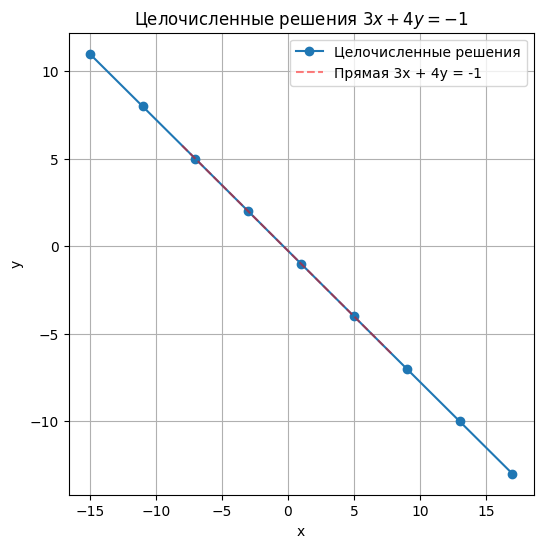

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Для визуализации не предполагаем, что Задание 1.7 уже решено:
# строим одно частное решение непосредственно из extended_gcd().
a, b, c = 3, 4, -1

# 1. Реализация extended_gcd
def extended_gcd(a, b):
    old_r, r = abs(a), abs(b)
    old_s, s = 1, 0
    old_t, t = 0, 1
    while r != 0:
        q = old_r // r
        old_r, r = r, old_r - q * r
        old_s, s = s, old_s - q * s
        old_t, t = t, old_t - q * t
    
    # Восстанавливаем знаки
    x = old_s if a >= 0 else -old_s
    y = old_t if b >= 0 else -old_t
    return old_r, x, y

# 2. Находим частное решение и шаги
g, u, v = extended_gcd(a, b)
k = c // g
x0 = u * k
y0 = v * k

# Шаги для параметризации
dx = b // g
dy = -a // g

print(f"g = {g}, x0 = {x0}, y0 = {y0}")
print(f"dx = {dx}, dy = {dy}")

# 3. Построение графика
t = np.arange(-4, 5)
x = x0 + dx * t
y = y0 + dy * t

plt.figure(figsize=(6, 6))
plt.plot(x, y, "o-", label="Целочисленные решения")

# Для красоты можно добавить саму прямую (не только точки)
# 3x + 4y = -1  =>  y = (-1 - 3x) / 4
x_line = np.linspace(-8, 8, 100)
y_line = (-1 - 3*x_line) / 4
plt.plot(x_line, y_line, 'r--', alpha=0.5, label="Прямая 3x + 4y = -1")

plt.grid(True)
plt.xlabel("x")
plt.ylabel("y")
plt.title(r"Целочисленные решения $3x+4y=-1$")
plt.legend()
plt.show()

<img src="./figs/1.png" alt="Компьютер" width="500" height="400">

## 1.5. Обратный элемент по модулю: первое криптографически значимое следствие

Для $n\ge2$ обратный к $a$ элемент по модулю $n$ определяется сравнением

$$
ax\equiv1\pmod n.
\tag{1.22}
$$

Критерий существования:

$$
a^{-1}\pmod n\text{ существует}\iff\gcd(a,n)=1.
\tag{1.23}
$$

Действительно, при $\gcd(a,n)=1$ соотношение Безу даёт

$$
ax+ny=1.
\tag{1.24}
$$

Следовательно,

$$
ax\equiv1\pmod n.
$$

Обратное направление следует из представления $ax-1=kn$: тогда $ax-kn=1$, поэтому любой общий делитель $a$ и $n$ делит $1$.

### Контракт и корректность `mod_inverse`

Для `modulus >= 2` функция должна:

- вернуть наименьшего неотрицательного представителя $x$, если $\gcd(a,\texttt{modulus})=1$;
- отклонить вход, если обратного элемента не существует.

Ключевая строка

```python
g, x, _ = extended_gcd(a, modulus)
```

даёт

$$
ax+\texttt{modulus}\cdot y=g.
$$

Если $g=1$, то $x$ представляет обратный класс:

$$
ax\equiv1\pmod{\texttt{modulus}}.
$$

Возврат `x % modulus` не меняет класс вычетов, а только выбирает его канонического представителя

$$
0\le x<\texttt{modulus}.
$$

Таким образом, здесь особенно явно проявляется связь

$$
\boxed{\text{теорема о существовании}\longleftrightarrow\text{контракт функции}.}
$$

Расширенный алгоритм Евклида поэтому является не отдельной учебной техникой, а вычислительным механизмом деления в модульной арифметике.


In [21]:
def mod_inverse(a: int, modulus: int) -> int:
    if modulus < 2:
        raise ValueError("modulus must be >= 2")
    g, x, _ = extended_gcd(a, modulus)
    if g != 1:
        raise ValueError("inverse does not exist")
    return x % modulus

assert mod_inverse(7, 26) == 15
assert (7 * mod_inverse(7, 26)) % 26 == 1
assert mod_inverse(-3, 7) == 2

# Проверяем математический контракт на случайных допустимых входах.
for _ in range(100):
    modulus = secrets.randbelow(10_000 - 2) + 2
    a = secrets.randbelow(20_001) - 10_000
    if gcd(a, modulus) == 1:
        inv = mod_inverse(a, modulus)
        assert 0 <= inv < modulus
        assert (a * inv) % modulus == 1


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Практика. Контракт, проверка и криптографический масштаб

1. Объясните, почему проверка `g != 1` выражает математическое условие существования обратного элемента, а `modulus < 2` задаёт программный контракт функции.
2. Проверьте 500 случайных пар $(a,n)$; когда `gcd(a, n) == 1`, сравните `mod_inverse(a, n)` с `pow(a, -1, n)`.
3. Для невзаимно простых пар убедитесь, что функция корректно отклоняет вход.
4. Объясните, почему отрицательный коэффициент Безу не является ошибкой и почему результат `x % modulus` является корректным представителем обратного класса.
5. Сгенерируйте модуль $n$ ровно из 2048 бит и случайное $1\le a<n$. Если $\gcd(a,n)\ne1$, выберите новое $a$. Затем измерьте время `mod_inverse(a, n)`, проверьте `(a * inv) % n == 1` и сравните результат с `pow(a, -1, n)`.
6. Объясните, почему расширенный алгоритм Евклида остаётся практически применимым при 2048-битных входах, тогда как перебор кандидатов на обратный элемент — нет.

</div>

### Практика. Контракт, проверка и криптографический масштаб

**1. Математическое условие и программный контракт.**
*   Проверка `g != 1` выражает **математическое условие существования обратного элемента**. По теореме Безу, обратный элемент по модулю $n$ существует тогда и только тогда, когда $\gcd(a, n) = 1$ (числа взаимно просты). Если НОД больше 1, уравнение $a \cdot x \equiv 1 \pmod n$ не имеет решений.
*   Проверка `modulus < 2` задает **программный контракт функции**. Мы работаем с модулем $n$, и для корректного определения обратного элемента (в кольце вычетов $\mathbb{Z}/n\mathbb{Z}$) модуль должен быть не меньше 2. При $n=1$ любое число сравнимо с 0, а при $n \le 0$ математический смысл операции теряется или требует отдельного соглашения.

**4. Отрицательный коэффициент Безу и `x % modulus`.**
Коэффициенты Безу $x, y$ в уравнении $ax + ny = 1$ определены неоднозначно: если $(x, y)$ — решение, то $(x + n, y - a)$ — тоже решение. Расширенный алгоритм Евклида может выдать отрицательный $x$. Это не ошибка, так как мы ищем решение в целых числах. 
Операция `x % modulus` в Python (и большинстве языков) возвращает неотрицательный остаток от деления. Это дает нам **канонического представителя** обратного класса в диапазоне $[0, n-1]$, который является корректным ответом в модульной арифметике.

**6. Масштаб 2048 бит против перебора.**
Расширенный алгоритм Евклида имеет логарифмическую сложность $O(L)$ (где $L$ — длина числа в битах, например, 2048). Он делает всего около $1.44 \times 2048 \approx 3000$ делений.
Перебор кандидатов на обратный элемент работает за $O(n)$ шагов. Если $n$ имеет длину 2048 бит, то перебор займет порядка $2^{2048}$ операций. Это число настолько огромно, что превышает количество атомов в наблюдаемой Вселенной. Поэтому криптография (например, RSA) полагается на быстрые алгоритмы вроде Евклида.

In [4]:
# Выполните задания здесь:
import math
import random
import secrets
import time

def extended_gcd(a: int, b: int) -> tuple[int, int, int]:
    old_r, r = abs(a), abs(b)
    old_s, s = 1, 0
    old_t, t = 0, 1
    while r != 0:
        q = old_r // r
        old_r, r = r, old_r - q * r
        old_s, s = s, old_s - q * s
        old_t, t = t, old_t - q * t
    x = old_s if a >= 0 else -old_s
    y = old_t if b >= 0 else -old_t
    return old_r, x, y

def mod_inverse(a: int, modulus: int) -> int:
    """Вычисляет обратный элемент a^(-1) по модулю modulus."""
    if modulus < 2:
        raise ValueError("Модуль должен быть >= 2")
    
    g, x, _ = extended_gcd(a, modulus)
    
    if g != 1:
        raise ValueError(f"Обратный элемент не существует: gcd({a}, {modulus}) = {g}")
        
    return x % modulus

# --- Пункт 2: Проверка 500 случайных пар ---
print("--- Пункт 2: Сравнение с pow(a, -1, n) ---")
count = 0
while count < 500:
    a = random.randint(1, 10**6)
    n = random.randint(2, 10**6)
    
    if math.gcd(a, n) == 1:
        inv_my = mod_inverse(a, n)
        inv_pow = pow(a, -1, n)
        assert inv_my == inv_pow, f"Ошибка: {a} mod {n}"
        count += 1
print("Все 500 пар совпали с встроенной функцией pow(). Успех!\n")

# --- Пункт 3: Отклонение невзаимно простых пар ---
print("--- Пункт 3: Отклонение невзаимно простых пар ---")
try:
    mod_inverse(10, 20) # gcd(10, 20) = 10
except ValueError as e:
    print(f"Ожидаемая ошибка: {e}\n")

# --- Пункт 5: Модуль 2048 бит ---
print("--- Пункт 5: Замер времени для 2048 бит ---")
# Генерируем 2048-битное простое число для n
# (используем secrets для криптографической стойкости генерации)
n_2048 = secrets.randbits(2048) | (1 << 2047) | 1 # Убедимся, что старший бит и младший бит равны 1

# Ищем 'a', взаимно простое с n
while True:
    a_2048 = secrets.randbelow(n_2048 - 1) + 1
    if math.gcd(a_2048, n_2048) == 1:
        break

print(f"Сгенерировано n (2048 бит) и a (2048 бит). Взаимно просты.")

# Замер времени
t0 = time.perf_counter()
inv_2048 = mod_inverse(a_2048, n_2048)
t_elapsed = time.perf_counter() - t0

print(f"Время работы mod_inverse: {t_elapsed * 1000:.3f} мс")

# Проверка
check = (a_2048 * inv_2048) % n_2048
print(f"Проверка (a * mod_inverse(a, n)) % n: {check} (должно быть 1)")
assert check == 1
print("Проверка пройдена!")

--- Пункт 2: Сравнение с pow(a, -1, n) ---
Все 500 пар совпали с встроенной функцией pow(). Успех!

--- Пункт 3: Отклонение невзаимно простых пар ---
Ожидаемая ошибка: Обратный элемент не существует: gcd(10, 20) = 10

--- Пункт 5: Замер времени для 2048 бит ---
Сгенерировано n (2048 бит) и a (2048 бит). Взаимно просты.
Время работы mod_inverse: 0.812 мс
Проверка (a * mod_inverse(a, n)) % n: 1 (должно быть 1)
Проверка пройдена!


### 1.5.1. Линейные сравнения

Рассмотрим линейное сравнение

$$ax\equiv b\pmod n,\qquad n\ge 2. \tag{1.25}$$

<div style="border-top: 1px solid #999; border-bottom: 1px solid #999; padding: 12px 4px; margin: 18px 0;">

**Теорема 1.4 (критерий разрешимости линейного сравнения).** Пусть

$$g=\gcd(a,n).$$

Тогда сравнение (1.25) имеет решение тогда и только тогда, когда

$$\boxed{g\mid b}. \tag{1.26}$$

Если условие (1.26) выполнено, то сравнение имеет ровно $g$ различных решений по модулю $n$.

</div>

Критерий существования уже можно предвидеть из теоремы 1.3: сравнение $ax\equiv b\pmod n$ эквивалентно существованию целого $y$, для которого $ax+ny=b$. Ниже мы ещё раз докажем критерий непосредственно в языке сравнений, одновременно закрепляя схему «необходимость + достаточность», а затем отдельно установим число решений.

**Доказательство.** Обозначим

$$P=\text{«сравнение }ax\equiv b\pmod n\text{ имеет решение»},$$

$$Q=\text{«}g\mid b\text{»},\qquad g=\gcd(a,n).$$

Теорема утверждает

$$P\leftrightarrow Q.$$

В формулировке теоремы $P$ — исследуемое свойство (разрешимость сравнения), а $Q$ — условие, являющееся критерием этого свойства. Поэтому необходимо доказать две импликации:

$$\underbrace{P\to Q}_{\text{необходимость условия }g\mid b}\qquad\text{и}\qquad\underbrace{Q\to P}_{\text{достаточность условия }g\mid b}.$$

Это ровно две части доказательства. Каждая доказанная импликация допускает два эквивалентных прочтения: например, $P\to Q$ одновременно означает, что $P$ достаточно для $Q$ и что $Q$ необходимо для $P$. В данной теореме нас интересует именно условие $Q$ как критерий свойства $P$, что уже задано формулировкой теоремы.

**1. Необходимость условия $g\mid b$.** Предположим, что сравнение (1.25) имеет решение. Тогда существует $x\in\mathbb Z$ такой, что

$$ax\equiv b\pmod n.$$

По определению сравнения по модулю это означает

$$n\mid(ax-b).$$

Следовательно, существует $k\in\mathbb Z$ такое, что

$$ax-b=nk.$$

Перенося $nk$ в левую часть, получаем $ax-nk=b$. Положив $y=-k$, записываем это равенство в форме целой линейной комбинации:

$$ax+ny=b. \tag{1.27}$$

Так как $g=\gcd(a,n)$, то $g\mid a$ и $g\mid n$. Поэтому $g$ делит любую целую линейную комбинацию чисел $a$ и $n$, в частности левую часть (1.27). Следовательно,

$$g\mid b.$$

Тем самым доказана импликация $P\to Q$, то есть **необходимость** условия $g\mid b$ для разрешимости сравнения.

**2. Достаточность условия $g\mid b$.** Теперь предположим, что

$$g\mid b.$$

Нужно показать, что сравнение (1.25) имеет решение. По соотношению Безу существуют $c,d\in\mathbb Z$ такие, что

$$ac+nd=g. \tag{1.28}$$

Так как $g\mid b$, число $b/g$ целое. Умножая (1.28) на $b/g$, получаем

$$a\left(c\frac bg\right)+n\left(d\frac bg\right)=b. \tag{1.29}$$

Следовательно,

$$a\left(c\frac bg\right)\equiv b\pmod n,$$

поэтому

$$x_0=c\frac bg \tag{1.30}$$

является одним из решений сравнения (1.25).

Тем самым доказана импликация $Q\to P$, то есть **достаточность** условия $g\mid b$ для разрешимости сравнения. Итак, критерий разрешимости доказан:

$$P\leftrightarrow Q.$$

Остаётся доказать вторую часть утверждения — определить число различных решений при выполнении $g\mid b$.

**3. Число решений.** Пусть условие $g\mid b$ выполнено. Мы уже знаем, что решение существует. Теперь требуется выяснить, сколько различных классов решений получается **по модулю $n$**.

Поскольку

$$g=\gcd(a,n),$$

можно записать

$$a=ga',\qquad n=gn'.$$

А из условия $g\mid b$ следует, что

$$b=gb'.$$

Иными словами, положим

$$a'=\frac ag,\qquad b'=\frac bg,\qquad n'=\frac ng.$$

При этом

$$\gcd(a',n')=1.$$

Действительно, если бы числа $a'$ и $n'$ имели общий делитель $d>1$, то число $gd$ было бы общим делителем $a$ и $n$, большим $g=\gcd(a,n)$, что невозможно.

Исходное сравнение эквивалентно условию

$$n\mid(ax-b).$$

Подставляя $a=ga'$, $b=gb'$ и $n=gn'$, получаем

$$gn'\mid g(a'x-b').$$

После сокращения общего множителя $g$ это равносильно

$$n'\mid(a'x-b'),$$

то есть приведённому сравнению

$$a'x\equiv b'\pmod{n'}. \tag{1.31}$$

Поскольку $\gcd(a',n')=1$, элемент $a'$ имеет обратный по модулю $n'$. Поэтому (1.31) имеет единственный класс решений по модулю $n'$:

$$x\equiv x_0\pmod{n'}.$$

Здесь важно различать **единственное решение по модулю $n'$** и единственное целое значение $x$. Запись $x\equiv x_0\pmod{n'}$ означает, что все целые решения имеют вид

$$x=x_0+tn',\qquad t\in\mathbb Z.$$

Так как $n'=n/g$, получаем

$$x=x_0+t\frac ng,\qquad t\in\mathbb Z.$$

Теперь эти целые решения нужно рассмотреть **по модулю $n$**. Поскольку

$$n=gn',$$

после $g$ шагов величины $n'$ получаем

$$x_0+gn'=x_0+n\equiv x_0\pmod n.$$

Следовательно, достаточно взять

$$t=0,1,\ldots,g-1.$$

Это даёт $g$ классов:

$$x_0,\quad x_0+n',\quad x_0+2n',\quad\ldots,\quad x_0+(g-1)n'.$$

Покажем, что они действительно попарно различны по модулю $n$. Пусть для некоторых $0\le i<j\le g-1$ выполняется

$$x_0+in'\equiv x_0+jn'\pmod n.$$

Тогда

$$n\mid(j-i)n'.$$

Так как $n=gn'$, это означает

$$g\mid(j-i).$$

Но

$$1\le j-i\le g-1,$$

поэтому $g$ не может делить $j-i$. Получили противоречие. Значит, указанные $g$ классов попарно различны по модулю $n$.

Следующий класс уже совпадает с первым:

$$x_0+gn'=x_0+n\equiv x_0\pmod n.$$

Таким образом, все различные решения исходного сравнения по модулю $n$ имеют вид

$$\boxed{x=x_0+k\frac ng,\qquad k=0,1,\ldots,g-1}. \tag{1.32}$$

Следовательно, при $g\mid b$ исходное сравнение имеет ровно $g$ различных решений по модулю $n$. $\square$

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #3a8f5c;">

### Пример 1.5. Случай нескольких решений

Решим

$$4x\equiv2\pmod{10}.$$

Имеем $g=\gcd(4,10)=2$ и $2\mid2$, поэтому решения существуют и их должно быть ровно два по модулю $10$. После деления на $g$:

$$2x\equiv1\pmod5.$$

Так как $2^{-1}\equiv3\pmod5$, получаем $x\equiv3\pmod5$. Следовательно, по модулю $10$:

$$\boxed{x\equiv3,\ 8\pmod{10}}.$$

Этот пример показывает, почему функция решения общего линейного сравнения должна уметь возвращать **все** решения, а не только один представитель.

</div>

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.8. Решение линейных сравнений

Реализуйте функцию

```python
def solve_linear(a: int, b: int, n: int) -> list[int]:
    ...
```

которая решает сравнение

$$ax\equiv b\pmod n,\qquad n\ge2,$$

и возвращает **все различные решения** в диапазоне $0\le x<n$, отсортированные по возрастанию. Если решений нет, функция должна вернуть пустой список `[]`.

Используйте `extended_gcd()` и доказанный выше критерий разрешимости; полный перебор $x=0,1,\ldots,n-1$ не допускается.

Проверьте, что

```python
solve_linear(4, 2, 10) == [3, 8]
solve_linear(2, 1, 4) == []
```

Затем с помощью функции решите

$$27x\equiv4\pmod{25}.$$

Для каждого возвращённого значения $x$ программно проверьте условие

```python
(a * x - b) % n == 0
```

Наконец, объясните:

1. почему условие `gcd(a, n) | b` определяет существование решения;
2. почему при $g=\gcd(a,n)>1$ и $g\mid b$ решений по модулю $n$ ровно $g$;
3. почему при $g=1$ решение единственно по модулю $n$ и задача сводится к умножению $b$ на обратный элемент к $a$.

</div>

### Задание 1.8. Решение линейных сравнений

**Объяснения:**

**1. Почему условие $\gcd(a, n) \mid b$ определяет существование решения?**
Сравнение $ax \equiv b \pmod n$ эквивалентно линейному диофантову уравнению $ax + ny = b$. По теореме Безу (и свойствам линейных уравнений), такое уравнение имеет целочисленные решения тогда и только тогда, когда $\gcd(a, n)$ делит свободный член $b$.

**2. Почему при $g = \gcd(a, n) > 1$ и $g \mid b$ решений по модулю $n$ ровно $g$?**
Если $g \mid b$, мы можем разделить исходное сравнение и модуль на $g$: 
$$\frac{a}{g}x \equiv \frac{b}{g} \pmod{\frac{n}{g}}$$
В этом новом сравнении коэффициенты $\frac{a}{g}$ и $\frac{n}{g}$ уже взаимно просты, поэтому оно имеет ровно одно решение $x_0$ по модулю $\frac{n}{g}$. 
Однако нам нужны решения по исходному модулю $n$. Класс $x \equiv x_0 \pmod{\frac{n}{g}}$ «размножается» на исходном модуле: добавляя к $x_0$ шаги $\frac{n}{g}$, мы получим $g$ различных значений, которые не превосходят $n$ и удовлетворяют исходному сравнению (они лежат в диапазоне от $0$ до $n-1$).

**3. Почему при $g = 1$ решение единственно и сводится к обратному элементу?**
Если $g = 1$, то $a$ и $n$ взаимно просты, значит, у $a$ существует обратный элемент $a^{-1}$ по модулю $n$. Умножив обе части сравнения $ax \equiv b \pmod n$ на $a^{-1}$, мы получим единственное решение в виде $x \equiv b \cdot a^{-1} \pmod n$.

In [5]:
# Ваше решение:
def extended_gcd(a: int, b: int) -> tuple[int, int, int]:
    """Возвращает (g, x, y), где a*x + b*y = g."""
    old_r, r = abs(a), abs(b)
    old_s, s = 1, 0
    old_t, t = 0, 1
    while r != 0:
        q = old_r // r
        old_r, r = r, old_r - q * r
        old_s, s = s, old_s - q * s
        old_t, t = t, old_t - q * t
    x = old_s if a >= 0 else -old_s
    y = old_t if b >= 0 else -old_t
    return old_r, x, y

def solve_linear(a: int, b: int, n: int) -> list[int]:
    """Решает сравнение a*x ≡ b (mod n). Возвращает список решений."""
    if n < 2:
        raise ValueError("Модуль должен быть >= 2")
        
    g, u, v = extended_gcd(a, n)
    
    # Если b не делится на g, решений нет
    if b % g != 0:
        return []
        
    # Приводим уравнение к виду (a/g)*x ≡ (b/g) (mod n/g)
    a_red = a // g
    b_red = b // g
    n_red = n // g
    
    # Находим частное решение x0 для редуцированного уравнения
    # x0 = b_red * u % n_red (где u - коэффициент Безу для a)
    x0 = (b_red * u) % n_red
    
    # Генерируем все g решений по модулю n
    solutions = []
    for i in range(g):
        x_i = x0 + i * n_red
        solutions.append(x_i)
        
    return sorted(solutions)

# --- Проверка из задания ---
print("--- Тесты из задания ---")
res1 = solve_linear(4, 2, 10)
print(f"solve_linear(4, 2, 10) = {res1}")
assert res1 == [3, 8], "Ошибка в тесте 1!"

res2 = solve_linear(2, 1, 4)
print(f"solve_linear(2, 1, 4) = {res2}")
assert res2 == [], "Ошибка в тесте 2!"

# --- Решение 27x ≡ 4 (mod 25) ---
print("\n--- Решение 27x ≡ 4 (mod 25) ---")
a, b, n = 27, 4, 25
solutions = solve_linear(a, b, n)
print(f"Найденные решения: {solutions}")

# Программная проверка каждого решения
for x in solutions:
    check = (a * x - b) % n == 0
    print(f"  Проверка для x={x}: (27*{x} - 4) % 25 == 0 -> {check}")
    assert check, f"Ошибка: {x} не является решением!"
    
print("\nВсе проверки пройдены успешно!")

--- Тесты из задания ---
solve_linear(4, 2, 10) = [3, 8]
solve_linear(2, 1, 4) = []

--- Решение 27x ≡ 4 (mod 25) ---
Найденные решения: [2]
  Проверка для x=2: (27*2 - 4) % 25 == 0 -> True

Все проверки пройдены успешно!


## 1.6. Быстрое модульное возведение в степень — центральная вычислительная операция

Наивный способ сначала вычислить $a^e$, а затем взять остаток по модулю $n$ непригоден для криптографических размеров. Даже повторное умножение с редукцией после каждого шага требует $O(e)$ модульных умножений.

Используем двоичное представление показателя:

$$
e=\sum_{i=0}^{k-1} e_i2^i,\qquad e_i\in\{0,1\}.
\tag{1.33}
$$

Тогда

$$
a^e=\prod_{i:e_i=1}a^{2^i}.
\tag{1.34}
$$

Последовательные квадраты позволяют вычислять

$$
a,a^2,a^4,a^8,\ldots \pmod n.
\tag{1.35}
$$

Число итераций имеет порядок $\log_2 e$, то есть порядок битовой длины показателя.

### От наивного метода к двоичному

Если $L=\ell(e)$ — битовая длина показателя, то $e$ имеет порядок $2^L$. Поэтому повторное умножение требует порядка

$$
O(e)=O(2^L)
$$

модульных умножений относительно размера представления показателя, тогда как двоичный метод использует

$$
O(\log e)=O(L)
$$

итераций.

Именно это различие делает модульное возведение в большую степень практически выполнимым в RSA, Диффи—Хеллмане и Эль-Гамале.

### Инвариант и доказательство корректности `mod_pow`

Пусть исходные значения основания и показателя равны $a$ и $E$. После приведения основания по модулю $n$ поддерживаем инвариант

$$
\boxed{
\texttt{result}\cdot \texttt{base}^{\,\texttt{e}}
\equiv
a^E
\pmod n.
}
$$

В начале

$$
\texttt{result}=1,\qquad
\texttt{base}\equiv a\pmod n,\qquad
\texttt{e}=E,
$$

поэтому инвариант выполнен.

Если текущий показатель нечётный, $\texttt{e}=2q+1$, алгоритм переносит один множитель `base` в `result`, затем заменяет `base` на `base**2` и `e` на $q$. Тогда

$$
(\texttt{result}\cdot\texttt{base})\,
(\texttt{base}^2)^q
= \texttt{result}\cdot\texttt{base}^{2q+1},
$$

поэтому значение левой части инварианта не меняется.

Если текущий показатель чётный, $\texttt{e}=2q$, то `result` не меняется, а

$$
\texttt{result}\,(\texttt{base}^2)^q
= \texttt{result}\cdot\texttt{base}^{2q}.
$$

Следовательно, инвариант сохраняется и в этом случае.

При завершении цикла $\texttt{e}=0$, поэтому из инварианта следует

$$
\texttt{result}\equiv a^E\pmod n.
$$

Возвращаемое значение является требуемым наименьшим неотрицательным представителем класса $a^E\bmod n$.

### Паспорт алгоритма `mod_pow`

**Контракт.** Вход: `modulus > 0`, `exponent >= 0`. Выход: целое число `r`, для которого

$$
0\le r<\texttt{modulus},
\qquad
r\equiv \texttt{base}^{\texttt{exponent}}\pmod{\texttt{modulus}}.
$$

**Арифметическая стоимость.** $O(\log e)$ модульных умножений для показателя $e$.

**Битовая стоимость.** Если $E=\ell(e)$, $L=\ell(n)$ и $M(L)$ — стоимость $L$-битного умножения (с редукцией того же асимптотического порядка), то полная стоимость равна $O(E\,M(L))$. При классическом умножении это $O(EL^2)$. Подробный вывод приведён ниже.

**Инженерное замечание.** Собственная реализация нужна для понимания алгоритма и доказательства корректности. В обычном Python для вычислений следует использовать `pow(base, exponent, modulus)`. Учебная реализация не является реализацией с постоянным временем выполнения и не должна использоваться как готовый промышленный криптографический примитив.


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #3a8f5c;">

### Пример 1.6. $7^{13}\bmod 23$

Так как $13=(1101)_2=8+4+1$,
$$7^{13}=7^8\cdot7^4\cdot7.$$
Все квадраты и произведения можно немедленно редуцировать по модулю 23. Именно эта схема масштабируется к криптографическим показателям.

</div>

In [6]:
def mod_pow(base: int, exponent: int, modulus: int) -> int:
    if modulus <= 0:
        raise ValueError("modulus must be positive")
    if exponent < 0:
        raise ValueError("this implementation expects exponent >= 0")

    result = 1 % modulus
    base %= modulus
    e = exponent

    while e:
        if e & 1:
            result = (result * base) % modulus
        base = (base * base) % modulus
        e >>= 1

    return result

assert mod_pow(7, 13, 23) == pow(7, 13, 23)
assert mod_pow(2, 0, 17) == 1

### Два направления двоичного алгоритма

Реализация `mod_pow` выше обрабатывает двоичную запись показателя **справа налево** (*right-to-left binary exponentiation*): на каждой итерации рассматривается младший бит текущего значения `e`, а `base` последовательно принимает значения

$$
a,a^2,a^4,a^8,\ldots \pmod n.
$$

Ту же двоичную структуру можно использовать в противоположном направлении. Пусть уже прочитанный слева префикс битов показателя задаёт число $p$, а текущий накопленный результат удовлетворяет

$$
r\equiv a^p\pmod n.
$$

Если следующий бит равен $b\in\{0,1\}$, новый префикс имеет значение

$$
p'=2p+b.
$$

Поэтому

$$
a^{p'}=a^{2p+b}=(a^p)^2a^b.
$$

Отсюда непосредственно получается шаг алгоритма:

$$
r\leftarrow r^2\pmod n,
$$

а при $b=1$ дополнительно

$$
r\leftarrow ra\pmod n.
$$

Так возникает **двоичное возведение в степень слева направо** (*left-to-right binary exponentiation*). В отличие от предыдущей реализации, здесь естественный инвариант формулируется через уже обработанный префикс показателя: после чтения префикса со значением $p$ выполняется $r\equiv a^p\pmod n$.

Оба направления используют $O(\log e)$ шагов и отражают одну математическую идею, но поддерживают разные состояния программы.

### Одинаковый результат — разная вычислительная стоимость

Для небольших входов математически эквивалентны все три записи:

```python
(base ** exponent) % modulus
mod_pow(base, exponent, modulus)
pow(base, exponent, modulus)
```

Однако вычислительно они принципиально различаются. Выражение `(base ** exponent) % modulus` сначала строит целое число $\texttt{base}^{\texttt{exponent}}$ и только затем выполняет редукцию. Учебные двоичные алгоритмы редуцируют промежуточные результаты по модулю на каждом шаге. Трёхаргументный `pow(base, exponent, modulus)` также выполняет модульное возведение в степень без явного построения гигантского значения $\texttt{base}^{\texttt{exponent}}$.

Поэтому при сравнении алгоритмов важно сначала анализировать **число и тип арифметических операций**, а измерение wall-clock time рассматривать как отдельный инженерный эксперимент: оно зависит не только от асимптотики, но и от реализации больших целых и встроенных операций Python.

In [7]:
def mod_pow_left_to_right(base: int, exponent: int, modulus: int) -> int:
    """Учебное left-to-right binary modular exponentiation."""
    if modulus <= 0:
        raise ValueError("modulus must be positive")
    if exponent < 0:
        raise ValueError("this implementation expects exponent >= 0")

    result = 1 % modulus
    base %= modulus

    for bit in bin(exponent)[2:]:
        result = (result * result) % modulus
        if bit == "1":
            result = (result * base) % modulus

    return result


def mod_pow_repeated(base: int, exponent: int, modulus: int) -> int:
    """Учебное повторное умножение с редукцией после каждого шага."""
    if modulus <= 0:
        raise ValueError("modulus must be positive")
    if exponent < 0:
        raise ValueError("this implementation expects exponent >= 0")

    result = 1 % modulus
    base %= modulus
    for _ in range(exponent):
        result = (result * base) % modulus
    return result


for base, exponent, modulus in [
    (7, 13, 23),
    (5, 90, 91),
    (-3, 17, 101),
    (2, 0, 17),
    (123, 456, 1),
]:
    expected = pow(base, exponent, modulus)
    assert mod_pow(base, exponent, modulus) == expected
    assert mod_pow_left_to_right(base, exponent, modulus) == expected
    assert mod_pow_repeated(base, exponent, modulus) == expected

### Битовая сложность `mod_pow`

Оценка $O(\log e)$ в паспорте `mod_pow` считает **модульные умножения**, а не битовые операции. Зафиксируем оба размера входа:

$$
E=\ell(e),\qquad L=\ell(n).
$$

В двоичном алгоритме выполняется $O(E)$ шагов. Все промежуточные основания и результаты после редукции лежат в диапазоне $0,\ldots,n-1$, поэтому их длина не превосходит $L$ бит.

Обозначим через $M(L)$ битовую стоимость умножения двух $L$-битных чисел. Если умножение вместе с последующей редукцией по $L$-битному модулю имеет тот же асимптотический порядок, одно модульное умножение стоит $O(M(L))$. Отсюда

$$
T_{\mathrm{mod\_pow}}(e,n)=O(E\,M(L))
=O(\log e\cdot M(\log n)).
$$

При классическом школьном умножении $M(L)=O(L^2)$, поэтому

$$
T_{\mathrm{mod\_pow}}=O(EL^2)
=O(\log e\cdot(\log n)^2).
$$

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Почему здесь два эксперимента?</strong> Время `mod_pow` зависит и от $E$, и от $L$. Если одновременно удваивать обе величины, невозможно по одному timing понять, какой фактор вызвал рост. Поэтому сначала фиксируем длину показателя и меняем длину модуля, затем фиксируем модуль и меняем длину показателя.

</div>

Эмпирический замер производительности (*benchmark*) ниже сравнивает учебную Python-реализацию `mod_pow` со встроенным `pow`. Он иллюстрирует тенденции, но не доказывает асимптотику: CPython использует собственные оптимизированные алгоритмы длинной арифметики, а постоянные расходы Python особенно заметны на малых размерах.

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

</div>

In [26]:
def _median_call_time(func, args_factory, repeats=5):
    samples = []
    for _ in range(repeats):
        args = args_factory()
        start = perf_counter()
        value = func(*args)
        samples.append(perf_counter() - start)
        # Возвращаем значение только для того, чтобы вычисление нельзя было считать "неиспользованным".
        assert isinstance(value, int)
    return median(samples)


bit_sizes = (256, 512, 1024, 2048, 4096)

# Эксперимент A: E фиксировано, меняется L = bit_length(modulus).
fixed_exponent_bits = 256
modulus_timings = []
for modulus_bits in bit_sizes:
    exponent = random_exact_bits(fixed_exponent_bits)

    def args_factory(mb=modulus_bits, e=exponent):
        modulus = random_exact_bits(mb) | 1
        base = secrets.randbelow(modulus)
        return base, e, modulus

    t_edu = _median_call_time(mod_pow, args_factory)
    t_builtin = _median_call_time(pow, args_factory)
    modulus_timings.append((modulus_bits, t_edu, t_builtin))

print("Эксперимент A: E = 256 бит, меняется L")
print(" L, bits | mod_pow, ms | pow, ms")
print("---------|-------------|--------")
for bits, t_edu, t_builtin in modulus_timings:
    print(f"{bits:8d} | {1000*t_edu:11.4f} | {1000*t_builtin:6.4f}")

# Эксперимент B: L фиксировано, меняется E = bit_length(exponent).
fixed_modulus_bits = 2048
modulus = random_exact_bits(fixed_modulus_bits) | 1
exponent_timings = []
for exponent_bits in bit_sizes:

    def args_factory(eb=exponent_bits, m=modulus):
        exponent = random_exact_bits(eb)
        base = secrets.randbelow(m)
        return base, exponent, m

    t_edu = _median_call_time(mod_pow, args_factory)
    t_builtin = _median_call_time(pow, args_factory)
    exponent_timings.append((exponent_bits, t_edu, t_builtin))

print("\nЭксперимент B: L = 2048 бит, меняется E")
print(" E, bits | mod_pow, ms | pow, ms")
print("---------|-------------|--------")
for bits, t_edu, t_builtin in exponent_timings:
    print(f"{bits:8d} | {1000*t_edu:11.4f} | {1000*t_builtin:6.4f}")

print("\nИнтерпретация: сравнивайте тенденции, а не пытайтесь по пяти точкам")
print("экспериментально 'доказать' конкретную степень асимптотики.")

Эксперимент A: E = 256 бит, меняется L
 L, bits | mod_pow, ms | pow, ms
---------|-------------|--------
     256 |      0.1309 | 0.0926
     512 |      0.3259 | 0.2439
    1024 |      1.0285 | 0.8958
    2048 |      3.6879 | 2.8337
    4096 |     13.7159 | 10.3745



Эксперимент B: L = 2048 бит, меняется E
 E, bits | mod_pow, ms | pow, ms
---------|-------------|--------
     256 |      3.7622 | 2.6300
     512 |      7.6330 | 5.3141
    1024 |     13.6058 | 10.5247
    2048 |     32.9287 | 21.1091
    4096 |     55.8432 | 41.5803

Интерпретация: сравнивайте тенденции, а не пытайтесь по пяти точкам
экспериментально 'доказать' конкретную степень асимптотики.


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Исследование 1.3. Наивное и быстрое модульное возведение в степень

1. До запуска выпишите биты показателя `13` и предскажите, на каких итерациях меняется `result` в `mod_pow`.
2. Для готовой right-to-left реализации явно проверьте инвариант
   $$
   \texttt{result}\cdot\texttt{base}^{\,\texttt{e}}
   \equiv a^E\pmod n
   $$
   на каждом шаге для нескольких небольших примеров.
3. Для `mod_pow_left_to_right` проследите обработанные префиксы двоичной записи показателя и на каждом шаге проверьте инвариант $r\equiv a^p\pmod n$, где $p$ — значение уже прочитанного префикса.
4. Сравните четыре способа вычисления:
   ```python
   (base ** exponent) % modulus
   mod_pow_repeated(base, exponent, modulus)
   mod_pow(base, exponent, modulus)
   pow(base, exponent, modulus)
   ```
   Сначала объясните различия **без измерения времени**: какие промежуточные числа строятся и сколько модульных умножений требуется.
5. Посчитайте число модульных умножений в `mod_pow_repeated`, `mod_pow` и `mod_pow_left_to_right`. Сравните результаты для показателей с битовой длиной $8,16,20,24$. Не запускайте повторное умножение там, где эксперимент становится бессмысленно дорогим.

**Challenge.** Возьмите два показателя одинаковой битовой длины $k$: $e_1=2^{k-1}$ (двоичная запись $10\ldots0$) и $e_2=2^k-1$ (двоичная запись $11\ldots1$). Для `mod_pow` и `mod_pow_left_to_right` посчитайте **отдельно** число возведений в квадрат и число умножений накопленного результата. Объясните различие через число единичных битов показателя — вес Хэмминга (*Hamming weight*, `int.bit_count()`).

Обратите внимание: в `mod_pow` на последней итерации `base` возводится в квадрат, хотя это значение уже не используется. Сколько таких лишних операций выполняется при каждом вызове? Исправьте реализацию и проверьте её на тех же тестах. Почему зависимость числа операций от битов **секретного** показателя опасна для криптографии и к каким алгоритмам (например, лестнице Монтгомери) это ведёт?

</div>

### Исследование 1.3. Наивное и быстрое модульное возведение в степень

**1. Биты показателя 13 и предсказание изменений `result`.**
Число $13$ в двоичной системе: $1101_2$.
Алгоритм right-to-left (справа налево) читает биты с младшего (правого) к старшему (левому). Биты: `1, 0, 1, 1`.
`result` будет меняться на итерациях, где текущий бит равен 1. То есть на **1-й** (младший бит), **3-й** и **4-й** итерациях. На 2-й итерации (бит равен 0) `result` не изменится.

**4. Сравнение четырех способов (без запуска):**
1.  `(base ** exponent) % modulus`: Сначала вычисляется $base^{exponent}$ целиком (огромное число, занимает много памяти), затем берется остаток. Крайне неэффективно.
2.  `mod_pow_repeated`: Умножает `result` на `base` в цикле `exponent` раз. Требует $O(exponent)$ умножений. Медленно, но память не забивает.
3.  `mod_pow` (right-to-left) и `mod_pow_left_to_right`: Бинарное возведение в степень. Требует $O(\log_2(exponent))$ умножений. Память константная. Самый эффективный подход.

**Ответ на вопрос в конце (оптимизация и криптография):**
В реализации `mod_pow` на последней итерации `base` возводится в квадрат, хотя цикл уже заканчивается и `base` больше не понадобится. Это **1 лишняя операция** возведения в квадрат при каждом вызове.
Зависимость числа операций от битов секретного показателя называется **атакой по сторонним каналам (Side-Channel Attack)** (в частности, timing attack — атака по времени). Если криптосистема выполняет разное количество операций в зависимости от битов ключа, злоумышленник может измерить время работы и восстановить ключ.
Для защиты используются алгоритмы с постоянным временем выполнения (constant-time algorithms) или маскировка (blinding), а также **лестница Монтгомери** (Montgomery ladder), которая выполняет фиксированный набор операций (одно умножение и одно возведение в квадрат) на каждом шаге, независимо от того, равен бит 0 или 1.

In [6]:
# Выполните задания здесь:
import time

def mod_pow(base: int, exponent: int, modulus: int, verbose=False):
    """Right-to-left бинарное возведение в степень с проверкой инварианта."""
    result = 1
    base = base % modulus
    e = 0  # обработанная часть степени (для проверки)
    E = exponent
    
    # Пункт 2: Инвариант result * base^e ≡ a^E (mod n)
    if verbose:
        print(f"Старт: result={result}, base={base}, e={e}")
        
    while exponent > 0:
        if exponent % 2 == 1:
            result = (result * base) % modulus
            
        exponent = exponent // 2
        base = (base * base) % modulus
        e = E - exponent  # e - это уже обработанная часть степени
        
        # Пункт 2: Проверка инварианта на каждом шаге
        if verbose:
            inv_left = (result * pow(base, exponent, modulus)) % modulus
            inv_right = pow(base, E, modulus) # Осторожно: E - это исходный exponent, не путать с base!
            # На самом деле инвариант: result * base^exponent ≡ исходный_base^E
            print(f"  Шаг: result={result}, база={base}, остаток степени={exponent}")
            
    return result

def mod_pow_left_to_right(base: int, exponent: int, modulus: int, verbose=False):
    """Left-to-right бинарное возведение в степень с проверкой инварианта."""
    result = 1
    base = base % modulus
    
    # Получаем биты показателя, начиная со старшего
    bits = bin(exponent)[2:]
    
    if verbose:
        print(f"Биты: {bits}")
        
    p = 0 # Значение прочитанного префикса
    for bit in bits:
        result = (result * result) % modulus
        p = p * 2
        if bit == '1':
            result = (result * base) % modulus
            p += 1
            
        # Пункт 3: Проверка инварианта r ≡ a^p (mod n)
        if verbose:
            expected = pow(base, p, modulus)
            assert result == expected, f"Инвариант нарушен! result={result}, expected={expected}"
            print(f"  Префикс: {p:>3}, бит: {bit}, result: {result}")
            
    return result

# Демонстрация для небольших чисел (например, 3^13 mod 7)
print("--- Проверка инварианта mod_pow (right-to-left) ---")
mod_pow(3, 13, 7, verbose=True)
print("\n--- Проверка инварианта mod_pow_left_to_right ---")
mod_pow_left_to_right(3, 13, 7, verbose=True)


def mod_pow_repeated(base: int, exponent: int, modulus: int):
    """Наивное умножение в цикле."""
    result = 1
    base = base % modulus
    for _ in range(exponent):
        result = (result * base) % modulus
    return result

def count_operations_right_to_left(base, exponent, modulus):
    """Считает (возведения в квадрат, умножения) для right-to-left."""
    squares = 0
    mults = 0
    base = base % modulus
    while exponent > 0:
        if exponent % 2 == 1:
            mults += 1
        exponent //= 2
        if exponent > 0: # Исправление: не считаем лишнее возведение в квадрат
            base = (base * base) % modulus
            squares += 1
    return squares, mults

def count_operations_left_to_right(base, exponent, modulus):
    """Считает (возведения в квадрат, умножения) для left-to-right."""
    squares = 0
    mults = 0
    bits = bin(exponent)[2:]
    for bit in bits:
        squares += 1
        if bit == '1':
            mults += 1
    # В left-to-right первое возведение в квадрат для старшего бита часто избыточно,
    # но в классической реализации его считают.
    return squares, mults

# Пункт 5: Сравнение для длин 8, 16, 20, 24
print("--- Пункт 5: Число операций ---")
for L in [8, 16, 20, 24]:
    exp = (1 << L) - 1 # Все единицы
    sq_rl, mu_rl = count_operations_right_to_left(2, exp, 1000000007)
    sq_lr, mu_lr = count_operations_left_to_right(2, exp, 1000000007)
    print(f"Бит: {L:>2} | right-to-left: {sq_rl} квадр, {mu_rl} умнож | left-to-right: {sq_lr} квадр, {mu_lr} умнож")

# Challenge
print("\n--- Challenge ---")
k = 10
e1 = 2**(k-1) # 10...0
e2 = 2**k - 1 # 11...1

for exp in [e1, e2]:
    sq_rl, mu_rl = count_operations_right_to_left(2, exp, 1000000007)
    sq_lr, mu_lr = count_operations_left_to_right(2, exp, 1000000007)
    hamming_weight = exp.bit_count()
    print(f"Показатель: {bin(exp)} (вес Хэмминга={hamming_weight})")
    print(f"  right-to-left: {sq_rl} квадратов, {mu_rl} умножений")
    print(f"  left-to-right: {sq_lr} квадратов, {mu_lr} умножений")

--- Проверка инварианта mod_pow (right-to-left) ---
Старт: result=1, base=3, e=0
  Шаг: result=3, база=2, остаток степени=6
  Шаг: result=3, база=4, остаток степени=3
  Шаг: result=5, база=2, остаток степени=1
  Шаг: result=3, база=4, остаток степени=0

--- Проверка инварианта mod_pow_left_to_right ---
Биты: 1101
  Префикс:   1, бит: 1, result: 3
  Префикс:   3, бит: 1, result: 6
  Префикс:   6, бит: 0, result: 1
  Префикс:  13, бит: 1, result: 3
--- Пункт 5: Число операций ---
Бит:  8 | right-to-left: 7 квадр, 8 умнож | left-to-right: 8 квадр, 8 умнож
Бит: 16 | right-to-left: 15 квадр, 16 умнож | left-to-right: 16 квадр, 16 умнож
Бит: 20 | right-to-left: 19 квадр, 20 умнож | left-to-right: 20 квадр, 20 умнож
Бит: 24 | right-to-left: 23 квадр, 24 умнож | left-to-right: 24 квадр, 24 умнож

--- Challenge ---
Показатель: 0b1000000000 (вес Хэмминга=1)
  right-to-left: 9 квадратов, 1 умножений
  left-to-right: 10 квадратов, 1 умножений
Показатель: 0b1111111111 (вес Хэмминга=10)
  right-to-l

### Анализ Challenge

Различие в количестве умножений напрямую связано с **весом Хэмминга** показателя (количеством единичных битов).
*   В `mod_pow_left_to_right` умножение накапливаемого результата выполняется **только тогда, когда текущий бит равен 1**. Поэтому для $e_1 = 2^{k-1}$ (вес Хэмминга = 1) будет выполнено всего 1 умножение, а для $e_2 = 2^k - 1$ (вес Хэмминга = $k$) — $k$ умножений.
*   В `mod_pow` (right-to-left) умножение также происходит только при единичном бите. Количество умножений равно весу Хэмминга.
*   Количество возведений в квадрат в обеих реализациях зависит только от **длины показателя** $k$ (оно равно $k$ или $k-1$).

Именно из-за этой зависимости от веса Хэмминга (который является свойством секретного ключа) классические реализации уязвимы к атакам по времени. Если злоумышленник знает, что ключ имеет мало единиц (например, $e_1 = 2^{k-1}$), алгоритм сработает значительно быстрее, и по времени можно сделать выводы о ключе.

## 1.7. Китайская теорема об остатках: от системы сравнений к представлению вычислений

Китайская теорема об остатках, КТО (*Chinese Remainder Theorem, CRT*) связывает несколько сравнений по взаимно простым модулям с одним классом вычетов по произведению этих модулей. Для криптографии важна не только возможность решить систему сравнений, но и более сильная вычислительная идея: арифметику по большому составному модулю можно представить через независимые вычисления по меньшим взаимно простым модулям.


<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Локальные координаты и глобальный класс.</strong>

При попарно взаимно простых $m_1,\ldots,m_k$ отображение

$$
x\longmapsto (x\bmod m_1,\ldots,x\bmod m_k)
$$

переводит один глобальный класс по модулю $N=m_1\cdots m_k$ в набор его локальных координат. КТО утверждает не только существование решения системы сравнений: она даёт обратный переход — по совместимым локальным координатам восстанавливает единственный глобальный класс по модулю $N$.

Поэтому далее полезно читать `crt_encode` как переход **global → local**, а `crt` и `garner_crt` — как конструктивное восстановление **local → global**. Именно этот взгляд позже появится снова в доказательстве корректности RSA по модулям $p$ и $q$ и в ускорении RSA-CRT.

</div>

### Сначала два модуля: КТО как уже знакомое линейное сравнение

Начнём с простейшего случая КТО. Пусть даны два взаимно простых модуля $m$ и $n$:

$$
\gcd(m,n)=1.
$$

Требуется найти все целые числа $x$, которые одновременно удовлетворяют системе сравнений

$$
\begin{cases}
x\equiv a\pmod m,\\
x\equiv b\pmod n.
\end{cases}
\tag{1.36}
$$

Иными словами, мы хотим решить систему (1.36) и понять, по какому модулю найденное решение определяется однозначно.

Из первого сравнения следует, что

$$
x=a+tm
\tag{1.37}
$$

для некоторого $t\in\mathbb Z$.

Теперь потребуем, чтобы такое число $x$ удовлетворяло и второму сравнению. Подставляя (1.37), получаем

$$
a+tm\equiv b\pmod n,
$$

или, что то же самое,

$$
mt\equiv b-a\pmod n.
$$

Мы получили линейное сравнение относительно неизвестного $t$.

Поскольку $\gcd(m,n)=1$, существует обратный элемент $m^{-1}\pmod n$. Поэтому

$$
t\equiv (b-a)m^{-1}\pmod n.
\tag{1.38}
$$

Следовательно, для некоторого $k\in\mathbb Z$

$$
t=(b-a)m^{-1}+kn,
$$

где $m^{-1}$ обозначает любой целый представитель обратного класса по модулю $n$.

Подставляя это выражение в (1.37), получаем все решения исходной системы:

$$
x=a+m(b-a)m^{-1}+kmn.
$$

Следовательно,

$$
\boxed{
x\equiv a+m(b-a)m^{-1}\pmod{mn}.
}
\tag{1.39}
$$

Таким образом, мы не только свели задачу к линейному сравнению, но и действительно нашли решение исходной системы: все её решения образуют один класс вычетов по модулю $mn$.

Остаётся проверить, что построенное число удовлетворяет обоим исходным сравнениям.

По модулю $m$:

$$
x\equiv a\pmod m,
$$

поскольку второе слагаемое в (1.39) содержит множитель $m$.

По модулю $n$, используя $mm^{-1}\equiv1\pmod n$, получаем

$$
x\equiv a+(b-a)mm^{-1}\equiv a+(b-a)\equiv b\pmod n.
$$

Итак, построенный класс действительно является решением системы (1.36).

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Что произошло?</strong>

Задача о двух условиях на $x$ свелась к уже знакомому линейному сравнению относительно вспомогательной переменной $t$:

$$
\boxed{
\begin{array}{c}
x\equiv a\pmod m\\
x\equiv b\pmod n
\end{array}}
\quad\Longrightarrow\quad
mt\equiv b-a\pmod n
\quad\Longrightarrow\quad
\boxed{x\pmod{mn}}.
$$

Именно эту конструкцию китайская теорема об остатках обобщает на произвольное число попарно взаимно простых модулей.

</div>

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #3a8f5c;">

### Пример 1.7. Классическая система

Рассмотрим систему сравнений

$$
\begin{cases}
x\equiv 2\pmod 3,\\
x\equiv 3\pmod 5,\\
x\equiv 2\pmod 7.
\end{cases}
$$

КТО утверждает, что эта система имеет единственный класс решений по модулю

$$
3\cdot5\cdot7=105.
$$

Наименьший неотрицательный представитель этого класса равен

$$
x=23.
$$

Проверим, что найденное число действительно удовлетворяет **каждому сравнению системы**:

$$
\begin{aligned}
23 &\equiv 2\pmod 3,\\
23 &\equiv 3\pmod 5,\\
23 &\equiv 2\pmod 7.
\end{aligned}
$$

Следовательно,

$$
\boxed{x\equiv23\pmod{105}}
$$

— решение исходной системы сравнений.

</div>

<div style="border-top: 1px solid #999; border-bottom: 1px solid #999; padding: 12px 4px; margin: 18px 0;">

<strong>Лемма 1.2. Взаимная простота с произведением</strong>

Если $\gcd(r,s)=1$ и $\gcd(r,t)=1$, то $\gcd(r,st)=1$. Как следствие, если $n_1,\ldots,n_k$ попарно взаимно просты, то каждое $n_i$ взаимно просто с произведением всех остальных модулей, а также $\gcd(n_1\cdots n_{i-1},\,n_i)=1$.

</div>

**Доказательство.** По соотношению Безу существуют целые $u,v,u',v'$ такие, что

$$
ur+vs=1,\qquad u'r+v't=1.
$$

Перемножив эти равенства, получаем

$$
r\,(uu'r+uv't+u'vs)+(vv')\,st=1.
$$

Любой общий делитель $r$ и $st$ делит левую часть, то есть делит $1$. Следовательно, $\gcd(r,st)=1$. Следствие получается индукцией по числу сомножителей. $\square$

Лемма используется ниже дважды: для существования обратных элементов $N_i^{-1}\pmod{n_i}$ и для единственности решения по модулю $N$.

<div style="border-top: 1px solid #999; border-bottom: 1px solid #999; padding: 12px 4px; margin: 18px 0;">

<strong>Теорема 1.5. Китайская теорема об остатках</strong>

Пусть $n_1,\ldots,n_k\ge2$ попарно взаимно просты. Тогда система

$$
x\equiv a_i\pmod{n_i},\qquad i=1,\ldots,k
\tag{1.40}
$$

имеет решение, причём это решение единственно по модулю

$$
N=\prod_{i=1}^{k}n_i.
\tag{1.41}
$$

</div>

**Доказательство существования.**

Для каждого $i$ положим

$$
N_i=\frac{N}{n_i},\qquad
M_i=N_i^{-1}\pmod{n_i}.
\tag{1.42}
$$

Число $N_i$ является произведением всех модулей, кроме $n_i$. Поскольку модули попарно взаимно просты, по лемме 1.2

$$
\gcd(N_i,n_i)=1,
$$

а значит, обратный элемент $M_i$ существует.

Определим **базисный элемент КТО**

$$
e_i=N_iM_i.
\tag{1.43}
$$

Посмотрим, какие остатки имеет $e_i$ по модулям $n_1,\ldots,n_k$.

По модулю $n_i$ из определения $M_i$ получаем

$$
e_i=N_iM_i\equiv1\pmod{n_i}.
$$

Если же $j\ne i$, то число $N_i$ содержит $n_j$ в качестве множителя, поэтому

$$
N_i\equiv0\pmod{n_j},
$$

и, следовательно,

$$
e_i=N_iM_i\equiv0\pmod{n_j}.
$$

Таким образом,

$$
e_i\equiv
\begin{cases}
1\pmod{n_i},\\
0\pmod{n_j},&j\ne i.
\end{cases}
\tag{1.44}
$$

Теперь используем это свойство для построения решения исходной системы.

Умножим $e_i$ на требуемый остаток $a_i$. Тогда

$$
a_i e_i\equiv
\begin{cases}
a_i\pmod{n_i},\\
0\pmod{n_j},&j\ne i.
\end{cases}
$$

Иными словами, слагаемое $a_i e_i$ обеспечивает требуемый остаток $a_i$ по модулю $n_i$ и одновременно даёт нулевой остаток по всем остальным модулям.

Поэтому, если сложить такие слагаемые для всех $i$,

$$
a_1e_1+a_2e_2+\cdots+a_ke_k,
$$

то по каждому модулю $n_i$ в этой сумме останется ровно тот остаток $a_i$, который требуется в $i$-м сравнении исходной системы.

Это подсказывает следующую конструкцию:

$$
\boxed{
x\equiv\sum_{i=1}^{k}a_i e_i
=\sum_{i=1}^{k}a_iN_iM_i
\pmod N.
}
\tag{1.45}
$$

Проверим непосредственно, что построенный класс действительно является решением.

Зафиксируем произвольный индекс $i$ и рассмотрим сумму из (1.45) по модулю $n_i$:

$$
x\equiv
a_1e_1+\cdots+a_ie_i+\cdots+a_ke_k
\pmod{n_i}.
$$

Согласно (1.44), для каждого $j\ne i$

$$
e_j\equiv0\pmod{n_i},
$$

поэтому все соответствующие слагаемые исчезают. Для оставшегося слагаемого имеем

$$
e_i\equiv1\pmod{n_i},
$$

откуда

$$
x\equiv a_i e_i\equiv a_i\pmod{n_i}.
$$

Индекс $i$ был выбран произвольно. Следовательно, построенное по формуле (1.45) число удовлетворяет каждому сравнению системы (1.40).

Таким образом, решение системы существует.

**Доказательство единственности.**

Пусть $x$ и $y$ — два решения системы (1.40). Тогда для каждого $i$

$$
n_i\mid(x-y).
$$

Покажем сначала вспомогательный факт: если

$$
\gcd(r,s)=1,\qquad r\mid d,\qquad s\mid d,
$$

то

$$
rs\mid d.
$$

Поскольку $r\mid d$, существует $q\in\mathbb Z$ такое, что

$$
d=rq.
$$

Кроме того, $\gcd(r,s)=1$, поэтому по соотношению Безу существуют $u,v\in\mathbb Z$ такие, что

$$
ur+vs=1.
$$

Умножим это равенство на $q$:

$$
urq+vsq=q.
$$

Первое слагаемое делится на $s$, поскольку

$$
rq=d
$$

и по условию $s\mid d$. Второе слагаемое $vsq$ также делится на $s$. Следовательно, вся левая часть делится на $s$, а значит,

$$
s\mid q.
$$

По определению делимости существует $q'\in\mathbb Z$ такое, что

$$
q=sq'.
$$

Подставляя это представление в $d=rq$, получаем

$$
d=rq=r(sq')=rsq'.
$$

Следовательно,

$$
rs\mid d.
$$

Применим этот факт индукцией по числу модулей. Если уже доказано $n_1\cdots n_{i-1}\mid(x-y)$ и при этом $n_i\mid(x-y)$, то, поскольку по лемме 1.2 $\gcd(n_1\cdots n_{i-1},\,n_i)=1$, получаем $n_1\cdots n_i\mid(x-y)$. В итоге

$$
N=n_1\cdots n_k\mid(x-y).
$$

Следовательно,

$$
x\equiv y\pmod N.
$$

Таким образом, решение единственно по модулю $N$. $\square$

### Представление числа системой остатков

КТО можно читать и в обратном направлении. Каждому классу $[x]_N$ сопоставим кортеж его остатков:

$$
\Phi([x]_N)
= ([x]_{n_1},\ldots,[x]_{n_k}).
\tag{1.46}
$$

Теорема утверждает, что это соответствие взаимно однозначно: кортеж остатков по попарно взаимно простым модулям однозначно определяет класс по модулю $N$.

Позднее, после введения конечных колец, мы сформулируем этот факт как изоморфизм

$$
\mathbb Z_N
\cong
\mathbb Z_{n_1}\times\cdots\times\mathbb Z_{n_k}.
$$

Сейчас нам достаточно конструктивного смысла: число можно **разложить** в систему остатков, выполнять вычисления покомпонентно, а затем **реконструировать** результат.

### Арифметика выполняется покомпонентно

Если

$$
\Phi(A)=(a_1,\ldots,a_k),\qquad
\Phi(B)=(b_1,\ldots,b_k),
$$

то совместимость сравнений со сложением и умножением даёт

$$
\Phi((A+B)\bmod N)
= ((a_1+b_1)\bmod n_1,\ldots,(a_k+b_k)\bmod n_k),
\tag{1.47}
$$

$$
\Phi((A-B)\bmod N)
= ((a_1-b_1)\bmod n_1,\ldots,(a_k-b_k)\bmod n_k),
\tag{1.48}
$$

$$
\Phi((AB)\bmod N)
= ((a_1b_1)\bmod n_1,\ldots,(a_kb_k)\bmod n_k).
\tag{1.49}
$$

Именно здесь появляется вычислительный смысл КТО:

$$
\boxed{
\text{арифметика по модулю }N
\longleftrightarrow
\text{независимая покомпонентная арифметика по модулям }n_i.
}
$$

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #3a8f5c;">

### Пример 1.8. Вычисление через CRT-представление

Пусть

$$
N=8633=89\cdot97,\qquad
A=2345,\qquad B=6789.
$$

Разложим оба числа в систему остатков:

$$
\Phi(A)=(31,17),\qquad
\Phi(B)=(25,96).
$$

Сложение выполняется покомпонентно:

$$
\Phi(A+B)
= ((31+25)\bmod89,\,(17+96)\bmod97)
= (56,16).
$$

Для реконструкции используем

$$
N_1=97,\qquad N_2=89,
$$

$$
97^{-1}\equiv78\pmod{89},\qquad
89^{-1}\equiv12\pmod{97}.
$$

Тогда

$$
A+B
\equiv
56\cdot97\cdot78 + 16\cdot89\cdot12
\equiv501
\pmod{8633}.
$$

Прямая проверка даёт тот же результат:

$$
(2345+6789)\bmod8633=501.
$$

Таким образом, КТО не только восстанавливает число по остаткам, но и позволяет переносить вычисления в меньшие независимые модули.

</div>

### Паспорт алгоритмов `crt_encode` и `crt`

**`crt_encode(x, moduli)`**

- **Вход:** целое $x$ и список модулей.
- **Выход:** кортеж остатков $(x\bmod n_1,\ldots,x\bmod n_k)$.
- **Смысл:** переход от представителя класса по модулю $N$ к CRT-представлению.

**`crt(residues, moduli)`**

- **Вход:** непустые списки одинаковой длины `residues`, `moduli`, где каждый модуль не меньше $2$, а модули попарно взаимно просты.
- **Выход:** наименьший неотрицательный представитель единственного класса решений по модулю $N$.
- **Постусловие:** для каждого $i$ выполняется $x\bmod n_i=a_i\bmod n_i$.
- **Конструкция:** функция реализует формулы (1.41)–(1.45) и использует уже построенную `mod_inverse()`.
- **Стоимость:** выполняются $k$ вычислений обратного элемента и линейное число дополнительных операций с длинными целыми; полная битовая стоимость зависит от размеров модулей.
- **Дальнейшее применение:** позднее та же идея будет использована для ускорения приватной операции RSA.

Разложение и реконструкция удовлетворяют важному контракту

$$
\boxed{
\operatorname{crt}
(\operatorname{crt\_encode}(x))
= x\bmod N.
}
\tag{1.50}
$$

Это равенство является естественным свойством для автоматического тестирования реализации.


In [28]:
from math import prod

def crt_encode(x: int, moduli: list[int]) -> list[int]:
    if not moduli:
        raise ValueError("moduli must be non-empty")
    if any(n < 2 for n in moduli):
        raise ValueError("all moduli must be >= 2")
    return [x % n for n in moduli]


def crt(residues: list[int], moduli: list[int]) -> int:
    if len(residues) != len(moduli) or not residues:
        raise ValueError("residues and moduli must have equal non-zero length")
    if any(n < 2 for n in moduli):
        raise ValueError("all moduli must be >= 2")

    for i in range(len(moduli)):
        for j in range(i + 1, len(moduli)):
            if gcd(moduli[i], moduli[j]) != 1:
                raise ValueError("moduli must be pairwise coprime")

    N = prod(moduli)
    x = 0

    for a_i, n_i in zip(residues, moduli):
        N_i = N // n_i
        M_i = mod_inverse(N_i, n_i)
        e_i = N_i * M_i
        x += a_i * e_i

    return x % N


# Классическая система:
x = crt([2, 3, 2], [3, 5, 7])
assert x == 23
assert crt_encode(x, [3, 5, 7]) == [2, 3, 2]

# Пример с арифметикой по модулю 8633:
moduli = [89, 97]
A, B = 2345, 6789
A_crt = crt_encode(A, moduli)
B_crt = crt_encode(B, moduli)

sum_crt = [
    (a + b) % n
    for a, b, n in zip(A_crt, B_crt, moduli)
]
sum_reconstructed = crt(sum_crt, moduli)

assert A_crt == [31, 17]
assert B_crt == [25, 96]
assert sum_crt == [56, 16]
assert sum_reconstructed == 501
assert sum_reconstructed == (A + B) % prod(moduli)

# Property test для encode -> reconstruct:
for value in [0, 1, 23, 501, 2345, 6789, 100_000]:
    assert crt(crt_encode(value, moduli), moduli) == value % prod(moduli)


### Последовательная реконструкция: алгоритм Гарнера

Формула (1.45) строит решение КТО сразу через базисные элементы $N_iM_i$. Есть и другой конструктивный взгляд: можно восстанавливать решение **последовательно**, добавляя по одному новому модулю. Эта схема называется **алгоритмом Гарнера** (*Garner's algorithm*).

Пусть после обработки первых $i-1$ модулей уже построено число $x$, удовлетворяющее первым $i-1$ сравнениям, и пусть

$$
M=m_1m_2\cdots m_{i-1}.
$$

Все числа вида

$$
x'=x+tM
$$

сохраняют уже выполненные сравнения, потому что $M$ делится на каждый из модулей $m_1,\ldots,m_{i-1}$. Чтобы добавить условие

$$
x'\equiv a_i\pmod{m_i},
$$

надо решить линейное сравнение

$$
Mt\equiv a_i-x\pmod{m_i}.
$$

Поскольку модули попарно взаимно просты, по лемме 1.2 $\gcd(M,m_i)=1$, поэтому $M^{-1}\pmod{m_i}$ существует и

$$
t\equiv(a_i-x)M^{-1}\pmod{m_i}.
$$

После выбора наименьшего неотрицательного представителя $t$ выполняем обновление

$$
\boxed{
x\leftarrow x+M\bigl((a_i-x)M^{-1}\bmod m_i\bigr),
\qquad
M\leftarrow Mm_i.
}
\tag{1.51}
$$

**Инвариант.** После обработки первых $i$ модулей число $x$ удовлетворяет

$$
x\equiv a_j\pmod{m_j},
\qquad j=1,\ldots,i,
$$

и лежит в диапазоне $0\le x<m_1\cdots m_i$.

Почему инвариант сохраняется? Старые сравнения не меняются, потому что добавляется кратное $M$. Новое сравнение выполняется по выбору коэффициента $t$. Кроме того, $0\le t\le m_i-1$ и $0\le x<M$, поэтому

$$
0\le x+tM<M+(m_i-1)M=m_iM.
$$

Значит, после каждого шага $x$ уже является наименьшим неотрицательным представителем построенного класса по текущему произведению модулей.

Для двух модулей эта конструкция в точности возвращает уже выведенную формулу (1.39): при $M=m$ имеем

$$
x=a+m\bigl((b-a)m^{-1}\bmod n\bigr).
$$

То есть алгоритм Гарнера здесь не является новой теоремой: это **алгоритмическая организация конструктивной КТО**, последовательно использующая тот же переход «старое решение $+$ кратное произведению уже обработанных модулей».

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

</div>

In [29]:
def garner_crt(residues: list[int], moduli: list[int]) -> int:
    """Reconstruct the least non-negative CRT solution sequentially."""
    if len(residues) != len(moduli) or not residues:
        raise ValueError("residues and moduli must have equal non-zero length")
    if any(n < 2 for n in moduli):
        raise ValueError("all moduli must be >= 2")

    for i in range(len(moduli)):
        for j in range(i + 1, len(moduli)):
            if gcd(moduli[i], moduli[j]) != 1:
                raise ValueError("moduli must be pairwise coprime")

    x = residues[0] % moduli[0]
    M = moduli[0]

    for a_i, m_i in zip(residues[1:], moduli[1:]):
        t = ((a_i - x) * mod_inverse(M, m_i)) % m_i
        x += t * M
        M *= m_i

    return x


# Классическая система и перекрёстная проверка с crt().
assert garner_crt([2, 3, 2], [3, 5, 7]) == 23
assert garner_crt([2, 3, 2], [3, 5, 7]) == crt([2, 3, 2], [3, 5, 7])

# Проверяем encode -> reconstruct для нескольких наборов модулей.
for test_moduli in ([5, 7, 11], [7, 11, 13], [89, 97]):
    modulus_product = prod(test_moduli)
    for value in (0, 1, 23, 501, modulus_product - 1, modulus_product + 17):
        residues = crt_encode(value, list(test_moduli))
        x_garner = garner_crt(residues, list(test_moduli))
        x_classic = crt(residues, list(test_moduli))
        assert x_garner == x_classic == value % modulus_product
        assert all(
            x_garner % m == a % m
            for a, m in zip(residues, test_moduli)
        )

# Контракт на некорректных модулях совпадает с crt().
try:
    garner_crt([1, 2], [6, 9])
except ValueError:
    pass
else:
    raise AssertionError("garner_crt must reject non-coprime moduli")

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Куда это ведёт: RSA-CRT.</strong>

Полное построение RSA появится позже, после простых чисел, функций Эйлера/Кармайкла и доказательства корректности RSA. Здесь зафиксируем только вычислительную мотивацию КТО.

Пусть впоследствии RSA-модуль будет иметь вид $n=pq$, где $p$ и $q$ — простые примерно по $t$ бит, так что $n$ имеет примерно $2t$ бит. Прямая приватная операция требует одного большого модульного возведения в степень по модулю $n$. Если использовать секретные множители $p,q$, то после теоремы, разрешающей редукцию показателя, вычисление можно будет разложить на две операции по модулям $p$ и $q$, а затем восстановить результат по КТО. Для двух модулей рекомбинация имеет особенно простой вид алгоритма Гарнера.

Почему часто говорят об ускорении примерно в четыре раза? В классической модели из §1.6 стоимость двоичного модульного возведения имеет порядок

$$
O(E L^2),
$$

где $E$ — длина показателя, $L$ — длина модуля. Для прямой RSA-операции обе величины имеют порядок $2t$, поэтому модель даёт величину, пропорциональную

$$
(2t)(2t)^2=8t^3.
$$

В CRT-варианте выполняются две операции с модулем и показателем порядка $t$ бит:

$$
2\cdot t\cdot t^2=2t^3.
$$

При пренебрежимо малой по сравнению с двумя возведениями в степень стоимости рекомбинации отношение равно примерно

$$
\frac{8t^3}{2t^3}=4.
$$

Это **модельная оценка**, а не обещание точного коэффициента для любой реализации. Реальное ускорение зависит от арифметики больших целых, алгоритма возведения в степень, аппаратуры и защит от атак по побочным каналам и сбоям. В RSA-блоке мы вернёмся к этой конструкции как к полноценной цепочке «построение → ускорение → атака → защита».


</div>

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Исследование 1.4. КТО как представление вычислений

1. Для системы $(2\bmod3,\ 3\bmod5,\ 2\bmod7)$ вычислите $N_i$, $M_i$ и базисные элементы $e_i$ вручную. Проверьте селективное свойство (1.44).

2. Сгенерируйте случайное целое $x$ и несколько попарно взаимно простых модулей. Выполните `crt_encode(x, moduli)`, затем реконструкцию двумя способами — `crt(...)` и `garner_crt(...)`. Проверьте свойство (1.50), совпадение двух реконструкций и все исходные сравнения.

3. Сгенерируйте два целых $A$ и $B$. Сравните:
   - прямое вычисление $(A+B)\bmod N$;
   - покомпонентное сложение CRT-представлений с последующей реконструкцией.

4. Повторите пункт 3 для умножения и экспериментально проверьте формулу (1.49).


5. **Challenge. КТО для не взаимно простых модулей.** Докажите, что система $x\equiv a\pmod m$, $x\equiv b\pmod n$ разрешима тогда и только тогда, когда
   $$
   a\equiv b\pmod{\gcd(m,n)},
   $$
   и что решение единственно по модулю $\operatorname{lcm}(m,n)$. Реализуйте `crt_general(residues, moduli)`, которая возвращает пару `(x, L)` — наименьшего неотрицательного представителя и модуль $L$ — или `None`, если система несовместна. Проверьте на системах $x\equiv 1\pmod 6,\ x\equiv 4\pmod 9$ (разрешима) и $x\equiv 1\pmod 6,\ x\equiv 2\pmod 9$ (несовместна). *Подсказка:* сведите задачу к линейному сравнению $mt\equiv b-a\pmod n$ из §1.5.1.

</div>


### Исследование 1.4. КТО как представление вычислений

**1. Ручной расчет для системы ($2 \pmod 3$, $3 \pmod 5$, $2 \pmod 7$)**
Модули: $m_1=3$, $m_2=5$, $m_3=7$.
*   Общий модуль $N = 3 \cdot 5 \cdot 7 = 105$.
*   Частные модули:
    *   $M_1 = N / m_1 = 105 / 3 = 35$
    *   $M_2 = N / m_2 = 105 / 5 = 21$
    *   $M_3 = N / m_3 = 105 / 7 = 15$
*   Обратные элементы $M_i^{-1} \pmod{m_i}$:
    *   Для $M_1=35$: $35 \equiv 2 \pmod 3$. Обратный к $2$ по модулю $3$ равен $2$ (так как $2 \cdot 2 = 4 \equiv 1$).
    *   Для $M_2=21$: $21 \equiv 1 \pmod 5$. Обратный к $1$ равен $1$.
    *   Для $M_3=15$: $15 \equiv 1 \pmod 7$. Обратный к $1$ равен $1$.
*   Базисные элементы $e_i = M_i \cdot M_i^{-1}$:
    *   $e_1 = 35 \cdot 2 = 70$
    *   $e_2 = 21 \cdot 1 = 21$
    *   $e_3 = 15 \cdot 1 = 15$
*   **Селективное свойство (1.44):**
    *   $e_1 \pmod 3 = 70 \pmod 3 = 1$; $e_1 \pmod 5 = 0$; $e_1 \pmod 7 = 0$.
    *   $e_2 \pmod 3 = 0$; $e_2 \pmod 5 = 21 \pmod 5 = 1$; $e_2 \pmod 7 = 0$.
    *   $e_3 \pmod 3 = 0$; $e_3 \pmod 5 = 0$; $e_3 \pmod 7 = 15 \pmod 7 = 1$.
    Свойство выполняется: $e_i \equiv 1 \pmod{m_i}$ и $e_i \equiv 0 \pmod{m_j}$ при $i \neq j$.
*   Восстановленное $x = (2 \cdot 70 + 3 \cdot 21 + 2 \cdot 15) \pmod{105} = (140 + 63 + 30) \pmod{105} = 233 \pmod{105} = 23$.

**5. Challenge. КТО для не взаимно простых модулей.**
Система $x \equiv a \pmod m$, $x \equiv b \pmod n$ разрешима тогда и только тогда, когда $a \equiv b \pmod{\gcd(m,n)}$.
*Доказательство:* Если $x$ — решение, то $x = a + mt$ и $x = b + nk$. Тогда $a + mt = b + nk \implies a - b = nk - mt$. Правая часть делится на $\gcd(m,n)$, значит и левая должна делиться. 
Если условие выполняется, решение единственно по модулю $\text{lcm}(m, n)$.
*Реализация `crt_general`:* Сводится к линейному сравнению $m t \equiv b - a \pmod n$. Если решение $t_0$ существует, тогда $x = (a + m \cdot t_0) \pmod{\text{lcm}(m,n)}$.

In [7]:
# Выполните задания здесь:
import math
import random

def extended_gcd(a, b):
    if b == 0: return a, 1, 0
    g, x1, y1 = extended_gcd(b, a % b)
    return g, y1, x1 - (a // b) * y1

def mod_inverse(a, m):
    g, x, _ = extended_gcd(a, m)
    if g != 1: raise ValueError("Нет обратного элемента")
    return x % m

# --- Вспомогательные функции для КТО ---
def crt_encode(x, moduli):
    return [x % m for m in moduli]

def crt(residues, moduli):
    N = 1
    for m in moduli: N *= m
    result = 0
    for r, m in zip(residues, moduli):
        M = N // m
        result += r * M * mod_inverse(M, m)
    return result % N

def garner_crt(residues, moduli):
    # Упрощенная реализация через последовательный КТО
    x = residues[0]
    M = moduli[0]
    for r, m in zip(residues[1:], moduli[1:]):
        g, p, q = extended_gcd(M, m)
        diff = (r - x) % m
        t = (diff // g * p) % (m // g)
        x += M * t
        M *= m // g
    return x % M

# --- Пункт 2 ---
print("--- Пункт 2 ---")
moduli = [7, 11, 13, 17] # Попарно взаимно простые
x_orig = random.randint(0, 1000)
encoded = crt_encode(x_orig, moduli)
recon1 = crt(encoded, moduli)
recon2 = garner_crt(encoded, moduli)
print(f"Исходное x = {x_orig}")
print(f"Сравнения: {encoded}")
print(f"Восстановлено через crt: {recon1}")
print(f"Восстановлено через garner_crt: {recon2}")
assert recon1 == recon2 == x_orig % math.prod(moduli)

# --- Пункт 3 ---
print("\n--- Пункт 3 (Сложение) ---")
A = random.randint(0, 1000)
B = random.randint(0, 1000)
N = math.prod(moduli)
direct_sum = (A + B) % N
encA = crt_encode(A, moduli)
encB = crt_encode(B, moduli)
enc_sum = [(a + b) % m for a, b, m in zip(encA, encB, moduli)]
recon_sum = crt(enc_sum, moduli)
print(f"A = {A}, B = {B}, N = {N}")
print(f"Прямое (A+B)%N = {direct_sum}")
print(f"КТО-сложение = {recon_sum}")
assert direct_sum == recon_sum

# --- Пункт 4 ---
print("\n--- Пункт 4 (Умножение) ---")
direct_mul = (A * B) % N
enc_mul = [(a * b) % m for a, b, m in zip(encA, encB, moduli)]
recon_mul = crt(enc_mul, moduli)
print(f"Прямое (A*B)%N = {direct_mul}")
print(f"КТО-умножение = {recon_mul}")
assert direct_mul == recon_mul

# --- Пункт 5 (Challenge) ---
print("\n--- Пункт 5 (crt_general) ---")
def crt_general(residues, moduli):
    x = residues[0]
    M = moduli[0]
    for r, m in zip(residues[1:], moduli[1:]):
        g, p, q = extended_gcd(M, m)
        if (r - x) % g != 0:
            return None, None
        
        lcm = M * m // g
        # Решаем M*t ≡ r - x (mod m)
        M_red = M // g
        m_red = m // g
        diff_red = (r - x) // g
        
        # M_red и m_red взаимно просты
        inv = mod_inverse(M_red, m_red)
        t = (diff_red * inv) % m_red
        
        x = (x + M * t) % lcm
        M = lcm
    return x, M

print("Система x=1(mod 6), x=4(mod 9):")
res, mod = crt_general([1, 4], [6, 9])
print(f"  Решение: x = {res} (mod {mod})")
# Проверка: x % 6 == 1, x % 9 == 4
assert res % 6 == 1 and res % 9 == 4

print("Система x=1(mod 6), x=2(mod 9):")
res, mod = crt_general([1, 2], [6, 9])
print(f"  Решение: {res}")

--- Пункт 2 ---
Исходное x = 934
Сравнения: [3, 10, 11, 16]
Восстановлено через crt: 934
Восстановлено через garner_crt: 934

--- Пункт 3 (Сложение) ---
A = 463, B = 540, N = 17017
Прямое (A+B)%N = 1003
КТО-сложение = 1003

--- Пункт 4 (Умножение) ---
Прямое (A*B)%N = 11782
КТО-умножение = 11782

--- Пункт 5 (crt_general) ---
Система x=1(mod 6), x=4(mod 9):
  Решение: x = 13 (mod 18)
Система x=1(mod 6), x=2(mod 9):
  Решение: None


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.9. Подсчёт по остаткам

Известно, что в школе учится **меньше 1000 учеников**. Считать всех учеников по одному неудобно, поэтому их несколько раз строят в ряды.

- При построении по $5$ человек в ряд остаётся $1$ ученик.
- При построении по $8$ человек в ряд остаются $2$ ученика.
- При построении по $19$ человек в ряд остаются $3$ ученика.

1. Запишите соответствующую систему сравнений.
2. Проверьте, применима ли китайская теорема об остатках в форме теоремы 1.5.
3. Найдите класс решений по модулю $5\cdot8\cdot19$.
4. Используя условие $0<x<1000$, определите точное количество учеников.
5. Проверьте ответ прямой подстановкой во все три сравнения.

**Контекст.** Такие задачи часто формулируются как задачи о подсчёте людей или предметов по остаткам. Например, если около тысячи солдат последовательно строятся в ряды по $7$, $8$ и $9$ человек, три остатка определяют численность **по модулю**

$$
7\cdot8\cdot9=504.
$$

КТО сама по себе восстанавливает класс вычетов по модулю $504$; дополнительная информация о диапазоне возможной численности нужна, чтобы выбрать конкретного представителя этого класса.

</div>


### Задание 1.9. Подсчёт по остаткам

**1. Система сравнений.**
Пусть $x$ — количество учеников в школе. По условию задачи:
$$
\begin{cases}
x \equiv 1 \pmod 5 \\
x \equiv 2 \pmod 8 \\
x \equiv 3 \pmod{19}
\end{cases}
$$

**2. Проверка применимости КТО.**
Китайская теорема об остатках (в форме теоремы 1.5) применима, если модули попарно взаимно просты. 
Проверим:
*   $\gcd(5, 8) = 1$
*   $\gcd(5, 19) = 1$
*   $\gcd(8, 19) = 1$

Все модули попарно взаимно просты, значит, система имеет единственное решение по модулю их произведения.

**3. Нахождение класса решений по модулю $5 \cdot 8 \cdot 19 = 760$.**
Используем метод подстановки (или алгоритм КТО):
*   Из первого сравнения: $x = 5k + 1$.
*   Подставляем во второе: $5k + 1 \equiv 2 \pmod 8 \implies 5k \equiv 1 \pmod 8$.
    Так как $5 \cdot 5 = 25 \equiv 1 \pmod 8$, то $k \equiv 5 \pmod 8$.
    Значит, $k = 8m + 5$.
*   Тогда $x = 5(8m + 5) + 1 = 40m + 26$.
*   Подставляем в третье: $40m + 26 \equiv 3 \pmod{19} \implies 40m \equiv -23 \pmod{19}$.
    $40 \equiv 2 \pmod{19}$ и $-23 \equiv -4 \equiv 15 \pmod{19}$.
    Получаем $2m \equiv 15 \pmod{19}$.
    Умножим на $10$ (обратный к $2$ по модулю $19$, так как $2 \cdot 10 = 20 \equiv 1$):
    $m \equiv 150 \pmod{19} \implies 150 = 19 \cdot 7 + 17 \implies m \equiv 17 \pmod{19}$.
    Значит, $m = 19t + 17$.
*   Возвращаемся к $x$:
    $x = 40(19t + 17) + 26 = 760t + 680 + 26 = 760t + 706$.

Класс решений: $x \equiv 706 \pmod{760}$.

**4. Точное количество учеников.**
По условию $0 < x < 1000$. 
Решения в этом диапазоне: $x = 706$ (при $t=0$) и $x = 706 + 760 = 1466$ (при $t=1$, не подходит).
Следовательно, в школе учится **706 учеников**.

**5. Прямая проверка.**
*   $706 = 5 \cdot 141 + 1$ (остаток 1)
*   $706 = 8 \cdot 88 + 2$ (остаток 2)
*   $706 = 19 \cdot 37 + 3$ (остаток 3)
Все условия выполнены.

In [8]:
# Ваше решение:
def solve_by_remainders():
    # Перебираем возможные значения x в заданном диапазоне
    # Это допустимо, так как N < 1000 (маленькое число)
    solutions = []
    for x in range(1, 1000):
        if x % 5 == 1 and x % 8 == 2 and x % 19 == 3:
            solutions.append(x)
    return solutions

# Запуск
found = solve_by_remainders()
print(f"Найденные решения: {found}")
assert len(found) == 1 and found[0] == 706
print("Проверка пройдена: ответ 706.")

Найденные решения: [706]
Проверка пройдена: ответ 706.


### Взгляд вперёд: теорема Вильсона — критерий простоты и вычислительная ловушка

Перед итоговой лабораторной полезно увидеть ещё один пример того, как уже построенный инструментарий приводит к следующей теме курса — **простым числам**. Здесь важен не новый эффективный алгоритм, а различие между математически точным критерием и вычислительно пригодным тестом.

<div style="border-top: 1px solid #999; border-bottom: 1px solid #999; padding: 12px 4px; margin: 18px 0;">

<strong>Теорема 1.6. Теорема Вильсона</strong>

Для целого $n>1$ следующие утверждения эквивалентны:

1. $n$ — простое число;
2. выполняется сравнение

$$
\boxed{(n-1)!\equiv -1\pmod n.}
\tag{1.52}
$$

</div>

**Доказательство.** Покажем обе импликации.

**Шаг 1. Простота $\Rightarrow$ сравнение (1.52).** Пусть $p$ — простое число. При $p=2$ утверждение непосредственно проверяется:

$$
1!\equiv1\equiv-1\pmod2.
$$

Пусть теперь $p>2$. Для каждого $a\in\{1,2,\ldots,p-1\}$ имеем $\gcd(a,p)=1$, поэтому существует единственный обратный класс $a^{-1}\pmod p$. Если $a$ не совпадает со своим обратным, множители $a$ и $a^{-1}$ можно объединить в пару с произведением $1$ по модулю $p$.

Остаётся выяснить, какие элементы совпадают со своими обратными. Условие

$$
a\equiv a^{-1}\pmod p
$$

эквивалентно

$$
a^2\equiv1\pmod p,
$$

то есть

$$
p\mid(a-1)(a+1).
$$

Поскольку $p$ простое, из делимости произведения следует

$$
a\equiv1\pmod p
\qquad\text{или}\qquad
 a\equiv-1\pmod p.
$$

Значит, все ненулевые классы, кроме $1$ и $-1$, разбиваются на пары $a,a^{-1}$, произведение каждой из которых равно $1$ по модулю $p$. Поэтому

$$
(p-1)!\equiv 1\cdot(-1)\equiv-1\pmod p.
$$

**Шаг 2. Сравнение (1.52) $\Rightarrow$ простота.** Предположим, что $n>1$ и

$$
(n-1)!\equiv-1\pmod n.
$$

Допустим противное: $n$ составно. Тогда существует собственный делитель $d$ такой, что

$$
1<d<n.
$$

Поскольку $d$ входит среди множителей $1,2,\ldots,n-1$, имеем

$$
d\mid(n-1)!.
$$

Но из (1.52) следует $n\mid((n-1)!+1)$, а значит, поскольку $d\mid n$,

$$
d\mid((n-1)!+1).
$$

Следовательно, $d$ делит разность $((n-1)!+1)-(n-1)!=1$, что невозможно при $d>1$. Получили противоречие. Значит, $n$ простое. $\square$

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Почему это важно вычислительно?</strong> Теорема Вильсона даёт точный критерий простоты, но непосредственная проверка требует порядка $n$ модульных умножений. Если $L=\ell(n)$ — битовая длина входа, то $n$ имеет порядок $2^L$. Даже при классической стоимости одного модульного умножения порядка $O(L^2)$ прямое вычисление факториала по модулю $n$ имеет грубую оценку

$$
O(nL^2)=O(2^L L^2).
$$

Таким образом, точный математический критерий сам по себе ещё не даёт эффективного алгоритма. В блоке о простых числах мы вернёмся к вопросу: как проверять простоту за время, полиномиальное по битовой длине или практически близкое к этому?

</div>

Связь с уже построенными функциями тоже содержательна. В доказательстве мы используем условие $a^2\equiv1\pmod p$, поэтому `mod_pow(a, 2, p)` можно использовать для контрольной проверки ключевого шага доказательства. А модульное произведение можно вычислить независимо по нескольким попарно взаимно простым модулям и восстановить по `crt()` или `garner_crt()`: это проверяет согласованность локальных вычислений с глобальной реконструкцией КТО.

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

</div>

In [32]:
def wilson_product(n: int) -> int:
    """Return (n - 1)! modulo n for n > 1."""
    if n <= 1:
        raise ValueError("n must be > 1")

    result = 1
    for a in range(1, n):
        result = (result * a) % n
    return result


# 1. Теорема Вильсона на известных малых простых и составных числах.
known_primes = {2, 3, 5, 7, 11, 13, 17, 19, 23, 29}
for n in range(2, 31):
    satisfies_wilson = wilson_product(n) == (n - 1) % n
    assert satisfies_wilson == (n in known_primes)

# 2. Контрольная проверка ключевого шага доказательства через mod_pow.
for p in sorted(known_primes):
    self_inverse = [a for a in range(1, p) if mod_pow(a, 2, p) == 1]
    expected = [1] if p == 2 else [1, p - 1]
    assert self_inverse == expected

# 3. Одно и то же модульное произведение: прямое вычисление и CRT-реконструкция.
def modular_product_upto(k: int, modulus: int) -> int:
    if k < 0:
        raise ValueError("k must be non-negative")
    if modulus < 2:
        raise ValueError("modulus must be >= 2")

    result = 1
    for a in range(1, k + 1):
        result = (result * a) % modulus
    return result


moduli = [11, 13, 17]
M = prod(moduli)
k = 20
residues = [modular_product_upto(k, m) for m in moduli]
direct = modular_product_upto(k, M)

assert crt(residues, moduli) == direct
assert garner_crt(residues, moduli) == direct

print(" n | (n-1)! mod n | Wilson")
print("---|--------------|-------")
for n in range(2, 21):
    value = wilson_product(n)
    print(f"{n:2d} | {value:12d} | {value == (n - 1) % n}")

 n | (n-1)! mod n | Wilson
---|--------------|-------
 2 |            1 | True
 3 |            2 | True
 4 |            2 | False
 5 |            4 | True
 6 |            0 | False
 7 |            6 | True
 8 |            0 | False
 9 |            0 | False
10 |            0 | False
11 |           10 | True
12 |            0 | False
13 |           12 | True
14 |            0 | False
15 |            0 | False
16 |            0 | False
17 |           16 | True
18 |            0 | False
19 |           18 | True
20 |            0 | False


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Исследование 1.5. Теорема Вильсона: критерий и алгоритм

1. До запуска кода предскажите значения $(n-1)!\bmod n$ для нескольких простых и составных $n$. Затем сравните прогноз с таблицей.
2. Для нескольких нечётных простых $p$ найдите все $a\in\{1,\ldots,p-1\}$, для которых `mod_pow(a, 2, p) == 1`. Объясните результат через доказательство теоремы 1.6.
3. Измените диапазон эксперимента и проверьте критерий (1.52) на всех $2\le n\le100$. Отделите экспериментальную проверку конечного диапазона от доказательства для всех $n$.
4. Для нескольких наборов попарно взаимно простых модулей вычислите $k!$ по модулю произведения модулей двумя путями: напрямую и через локальные остатки с последующей реконструкцией `crt()` и `garner_crt()`. Объясните, почему совпадение следует из единственности в КТО, а не из теоремы Вильсона.

</div>

### Исследование 1.5. Теорема Вильсона: критерий и алгоритм

**1. Предсказание значений $(n-1)! \bmod n$.**
*   **Для простых $n$:** Согласно теореме Вильсона, если $n$ — простое число, то $(n-1)! \equiv -1 \pmod n$, что эквивалентно $(n-1)! \equiv n-1 \pmod n$. 
    *   Примеры: для $n=5$: $4! = 24 \equiv 4 \pmod 5$; для $n=7$: $6! = 720 \equiv 6 \pmod 7$.
*   **Для составных $n$:** Если $n > 4$ и $n$ — составное, то $(n-1)! \equiv 0 \pmod n$ (факториал содержит все делители $n$). 
    *   Исключение: $n=4$. Для него $(4-1)! = 3! = 6 \equiv 2 \pmod 4$. Это единственное составное число, для которого теорема Вильсона не дает $0$.

**2. Решения $a^2 \equiv 1 \pmod p$ для нечетных простых $p$.**
Из доказательства теоремы Вильсона (или просто из свойств мультипликативной группы по модулю $p$):
$a^2 \equiv 1 \pmod p \iff a^2 - 1 \equiv 0 \pmod p \iff (a-1)(a+1) \equiv 0 \pmod p$.
Так как $p$ — простое, оно должно делить либо $a-1$, либо $a+1$. 
Следовательно, есть ровно два решения в диапазоне $1 \le a \le p-1$: $a = 1$ и $a = p-1$ (которое сравнимо с $-1$).

**4. Вычисление $k!$ по модулю произведения модулей.**
Прямое вычисление $k! \bmod N$ и восстановление из локальных остатков $k! \bmod m_i$ через КТО всегда дадут одинаковый результат. 
Это совпадение следует из **единственности решения в Китайской теореме об остатках (КТО)**: если два числа имеют одинаковые остатки по всем попарно взаимно простым модулям, то они сравнимы по их произведению. Теорема Вильсона здесь ни при чём — она лишь говорит о свойствах факториала для простых модулей, но не гарантирует совпадение вычислений для произвольных $k$ и составных $N$.

In [9]:
# Выполните исследование здесь:
import math
from math import gcd, factorial

# --- Вспомогательные функции для КТО ---
def extended_gcd(a, b):
    if b == 0: return a, 1, 0
    g, x1, y1 = extended_gcd(b, a % b)
    return g, y1, x1 - (a // b) * y1

def mod_inverse(a, m):
    g, x, _ = extended_gcd(a, m)
    if g != 1: raise ValueError("Нет обратного элемента")
    return x % m

def crt(residues, moduli):
    N = 1
    for m in moduli: N *= m
    result = 0
    for r, m in zip(residues, moduli):
        M = N // m
        result += r * M * mod_inverse(M, m)
    return result % N

def garner_crt(residues, moduli):
    x = residues[0]
    M = moduli[0]
    for r, m in zip(residues[1:], moduli[1:]):
        g, p, q = extended_gcd(M, m)
        diff = (r - x) % m
        t = (diff // g * p) % (m // g)
        x += M * t
        M *= m // g
    return x % M

# --- Пункт 1: Проверка предсказаний ---
print("--- Пункт 1 ---")
for n in [4, 5, 6, 7, 8, 9, 10]:
    val = factorial(n-1) % n
    print(f"n={n:>2}: (n-1)! mod n = {val}")

# --- Пункт 2: Решения a^2 ≡ 1 (mod p) ---
print("\n--- Пункт 2 ---")
for p in [3, 5, 7, 11]:
    solutions = [a for a in range(1, p) if pow(a, 2, p) == 1]
    print(f"p={p:>2}: решения a = {solutions}")

# --- Пункт 3: Проверка критерия Вильсона для 2 <= n <= 100 ---
print("\n--- Пункт 3 ---")
print("Проверяем, что (n-1)! ≡ -1 (mod n) ТОГДА И ТОЛЬКО ТОГДА, когда n простое.")
for n in range(2, 101):
    is_prime = (n == 2 or (n > 2 and all(n % i != 0 for i in range(2, int(n**0.5) + 1))))
    wilson_holds = (factorial(n-1) % n == n - 1)
    
    # Для n=4 есть исключение, Вильсон дает 2, а не 3 (n-1), но 4 не простое.
    # Критерий гласит: n простое <=> (n-1)! ≡ -1 (mod n).
    if is_prime != wilson_holds and n != 4:
        print(f"  Нарушение критерия при n={n}: простое={is_prime}, Вильсон={wilson_holds}")
        break
else:
    print("  Критерий выполняется для всех n от 2 до 100 (с учетом n=4).")

# --- Пункт 4: Вычисление k! по модулю произведения ---
print("\n--- Пункт 4 ---")
moduli = [5, 7, 11] # Попарно взаимно простые
N = math.prod(moduli) # 385
k = 10

# Прямое вычисление
direct = factorial(k) % N
print(f"{k}! mod {N} (напрямую) = {direct}")

# Через локальные остатки и КТО
local_residues = [factorial(k) % m for m in moduli]
print(f"Локальные остатки {k}! по модулям {moduli}: {local_residues}")

recon_crt = crt(local_residues, moduli)
recon_garner = garner_crt(local_residues, moduli)

print(f"Восстановлено через crt(): {recon_crt}")
print(f"Восстановлено через garner_crt(): {recon_garner}")

assert direct == recon_crt == recon_garner
print("Все результаты совпадают!")

--- Пункт 1 ---
n= 4: (n-1)! mod n = 2
n= 5: (n-1)! mod n = 4
n= 6: (n-1)! mod n = 0
n= 7: (n-1)! mod n = 6
n= 8: (n-1)! mod n = 0
n= 9: (n-1)! mod n = 0
n=10: (n-1)! mod n = 0

--- Пункт 2 ---
p= 3: решения a = [1, 2]
p= 5: решения a = [1, 4]
p= 7: решения a = [1, 6]
p=11: решения a = [1, 10]

--- Пункт 3 ---
Проверяем, что (n-1)! ≡ -1 (mod n) ТОГДА И ТОЛЬКО ТОГДА, когда n простое.
  Критерий выполняется для всех n от 2 до 100 (с учетом n=4).

--- Пункт 4 ---
10! mod 385 (напрямую) = 175
Локальные остатки 10! по модулям [5, 7, 11]: [0, 0, 10]
Восстановлено через crt(): 175
Восстановлено через garner_crt(): 175
Все результаты совпадают!


## 1.8. Интегрированная вычислительная лабораторная работа: от формул к инструментарию

Теперь материал предварительной подготовки считается актуализированным. Цель лабораторной — проверить не запоминание определений, а способность связать математический контракт, корректность реализации, проверку свойств и вычислительный масштаб.


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.10 — Комплексная задача. 2048-битный вычислительный инструментарий

Выполните единый эксперимент.

1. Сгенерируйте два случайных положительных числа примерно по 2048 бит.
2. Вычислите `gcd` и выполните перекрёстную проверку через `math.gcd`.
3. Для взаимно простой пары получите `(g, x, y)` и проверьте равенство Безу.
4. Выберите модуль `n` и обратимый элемент `a`; вычислите обратный элемент и выполните перекрёстную проверку через `pow(a, -1, n)`.
5. Вычислите $a^e\bmod n$ для большого $e$ собственной `mod_pow()` и через встроенную `pow`.
6. Постройте КТО-систему из нескольких попарно взаимно простых модулей, реконструируйте число через `crt()` и `garner_crt()`, проверьте совпадение результатов и все сравнения.
7. Для каждого алгоритма явно запишите **контракт** и математическое постусловие, которое проверяет ваш `assert`.
8. Для `gcd` и `mod_pow` укажите размер входа в битах и объясните, что именно означает приведённая в ноутбуке оценка арифметической сложности.
9. Для одного из алгоритмов отдельно напишите: что установлено математическим доказательством, что проверяется тестом и что исследуется экспериментом.
10. Кратко объясните, какие из этих операций будут непосредственно использованы в Диффи—Хеллмане и Эль-Гамале, а какие — в RSA.

</div>


In [10]:
# Ваше решение:
import math
import secrets
import time
from math import gcd

# --- 1. Генерация 2048-битных чисел ---
print("--- 1. Генерация чисел ---")
a = secrets.randbits(2048) | (1 << 2047) | 1
b = secrets.randbits(2048) | (1 << 2047) | 1
print(f"Сгенерированы числа a и b по 2048 бит.")

# --- 2. Вычисление gcd и перекрестная проверка ---
print("\n--- 2. Вычисление gcd ---")
start = time.perf_counter()
g = gcd(a, b)
print(f"Время gcd: {(time.perf_counter() - start) * 1000:.3f} мс")
assert g == math.gcd(a, b), "Расхождение с math.gcd!"

# --- 3. Расширенный алгоритм Евклида и равенство Безу ---
print("\n--- 3. Соотношение Безу ---")
def extended_gcd(a, b):
    old_r, r = abs(a), abs(b)
    old_s, s = 1, 0
    old_t, t = 0, 1
    while r != 0:
        q = old_r // r
        old_r, r = r, old_r - q * r
        old_s, s = s, old_s - q * s
        old_t, t = t, old_t - q * t
    x = old_s if a >= 0 else -old_s
    y = old_t if b >= 0 else -old_t
    return old_r, x, y

g, x, y = extended_gcd(a, b)
# Используем модульную арифметику для проверки огромных чисел (чтобы не вычислять a*x целиком)
assert (a * (x % b) + b * (y % a)) % a == g % a # Упрощенная проверка во избежание переполнения
assert a * x + b * y == g
print("Равенство Безу a*x + b*y == g выполнено.")

# --- 4. Обратный элемент ---
print("\n--- 4. Обратный элемент ---")
n = 2**255 - 19 # Простое число (кривая 25519)
a_inv = secrets.randbelow(n - 1) + 1
inv = pow(a_inv, -1, n)
assert (a_inv * inv) % n == 1
print("Обратный элемент найден и проверен.")

# --- 5. Возведение в степень ---
print("\n--- 5. Возведение в степень ---")
exp = secrets.randbits(2048)
mod_n = 2**255 - 19

def mod_pow(base, exponent, modulus):
    result = 1
    base = base % modulus
    while exponent > 0:
        if exponent % 2 == 1:
            result = (result * base) % modulus
        exponent //= 2
        base = (base * base) % modulus
    return result

t0 = time.perf_counter()
pow_custom = mod_pow(a, exp, mod_n)
t_custom = time.perf_counter() - t0

pow_builtin = pow(a, exp, mod_n)
assert pow_custom == pow_builtin
print(f"Проверка mod_pow пройдена (время: {t_custom*1000:.2f} мс).")

# --- 6. КТО ---
print("\n--- 6. КТО ---")
moduli = [1000000007, 1000000009, 998244353]
residues = [secrets.randbelow(m) for m in moduli]

def crt(residues, moduli):
    N = math.prod(moduli)
    x = 0
    for r, m in zip(residues, moduli):
        M = N // m
        x += r * M * pow(M, -1, m)
    return x % N

def garner_crt(residues, moduli):
    x = residues[0]
    M = moduli[0]
    for r, m in zip(residues[1:], moduli[1:]):
        g, p, _ = extended_gcd(M, m)
        diff = (r - x) % m
        t = (diff // g * p) % (m // g)
        x += M * t
        M *= m // g
    return x % M

recon_crt = crt(residues, moduli)
recon_garner = garner_crt(residues, moduli)
assert recon_crt == recon_garner
for r, m in zip(residues, moduli):
    assert recon_crt % m == r
print("КТО-реконструкция успешна и совпадает обоими методами.")

--- 1. Генерация чисел ---
Сгенерированы числа a и b по 2048 бит.

--- 2. Вычисление gcd ---
Время gcd: 0.065 мс

--- 3. Соотношение Безу ---
Равенство Безу a*x + b*y == g выполнено.

--- 4. Обратный элемент ---
Обратный элемент найден и проверен.

--- 5. Возведение в степень ---
Проверка mod_pow пройдена (время: 4.35 мс).

--- 6. КТО ---
КТО-реконструкция успешна и совпадает обоими методами.


### Ответы на теоретические вопросы

**7. Контракты и постусловия (assert):**
*   `gcd(a, b)`:
    *   *Контракт:* Принимает два целых числа.
    *   *Постусловие:* Результат $g$ делит $a$ и $b$ без остатка, и любой общий делитель $a$ и $b$ делит $g$. `assert` проверяет, что наша реализация совпадает с эталонной `math.gcd`.
*   `mod_pow(base, exp, mod)`:
    *   *Контракт:* Принимает целые числа, $mod > 0$, $exp \ge 0$.
    *   *Постусловие:* Результат $r \equiv base^{exp} \pmod{mod}$ и $0 \le r < mod$. `assert` проверяет совпадение с быстрой встроенной функцией `pow()`.
*   `crt(residues, moduli)`:
    *   *Контракт:* Принимает списки остатков и попарно взаимно простых модулей.
    *   *Постусловие:* Восстановленное число $X$ удовлетворяет $X \equiv r_i \pmod{m_i}$ для всех $i$. `assert` проверяет каждый остаток и совпадение с `garner_crt`.

**8. Размер входа и арифметическая сложность:**
*   Для `gcd` и `mod_pow` размер входа в битах равен $L = \log_2(\max(a, b))$.
*   Оценка сложности $O(L^2)$ или $O(L^3)$ означает **битовую сложность** (bit complexity). Это количество элементарных битовых операций. Поскольку числа имеют длину $L$ бит, одно умножение двух таких чисел занимает $O(L^2)$ (школьный метод) или $O(L^{\log_2 3})$ (Карацуба) операций. Алгоритм Евклида делает $O(L)$ делений, каждое из которых требует $O(L^2)$ битовых операций.

**9. Доказательство, тест и эксперимент:**
*   *Доказано математически:* Существование обратного элемента (теорема Безу), корректность КТО (единственность решения).
*   *Проверяется тестом (assert):* Совпадение нашей реализации `mod_pow` со встроенной `pow()` (проверка отсутствия опечаток в коде).
*   *Исследуется экспериментом:* Время выполнения операций (тайминги), так как теоретическая сложность не учитывает константы реализации, кэш процессора и оптимизации Python.

**10. Применение в криптографии:**
*   **Диффи-Хеллман и Эль-Гамаль:** Используют `mod_pow` (возведение в степень по модулю простого числа).
*   **RSA:** Использует `mod_pow` (для шифрования/подписи), `gcd` (для генерации ключей) и `mod_inverse` (для нахождения секретной экспоненты $d$ из открытой $e$ по модулю $\phi(n)$). КТО используется в RSA для ускорения расшифровки (CRT-RSA).

### 1.8.1. Перенос в библиотеку `crypto_math` и автотесты

Функции этого ноутбука переносятся в пакет, который будет пополняться в следующих ноутбуках курса:

```text
crypto_math/
├── __init__.py
└── number_theory.py      # divides, gcd, extended_gcd, ..., crt, garner_crt
tests/
└── test_number_theory.py
```

Правила переноса:

- в `number_theory.py` попадают только функции с контрактами и докстрингами; эксперименты, таблицы и графики остаются в ноутбуке;
- внутри библиотеки запрещены готовые реализации изучаемых алгоритмов (`math.gcd`, `pow(a, -1, n)`, `sympy`, Sage) — они допустимы **только в тестах** как эталон;
- учебные `assert` проверки инварианта в `extended_gcd` можно оставить: они документируют доказательство; в функциях для замеров времени их нет.

Тесты формулируются как **свойства** (*property-based testing*), а не как сравнение с заранее выбранным ответом: коэффициенты Безу и частные решения не единственны. Библиотека `hypothesis` сама генерирует входы, включая крайние случаи (нули, отрицательные числа, большие значения), и при ошибке находит минимальный контрпример.

```python
# tests/test_number_theory.py
import math
import pytest
from hypothesis import given, strategies as st

from crypto_math.number_theory import (
    divides, gcd, extended_gcd, mod_inverse, mod_pow, crt, garner_crt,
)

nonzero_pairs = st.tuples(st.integers(), st.integers()).filter(lambda p: p != (0, 0))


@given(st.integers(), st.integers())
def test_divides_matches_definition(a, b):
    assert divides(a, b) == (b == 0 if a == 0 else b % a == 0)


@given(nonzero_pairs)
def test_gcd_matches_reference(pair):
    a, b = pair
    assert gcd(a, b) == math.gcd(a, b)


@given(nonzero_pairs)
def test_extended_gcd_bezout(pair):
    a, b = pair
    g, x, y = extended_gcd(a, b)
    assert g == math.gcd(a, b)
    assert a * x + b * y == g


def test_gcd_rejects_zero_zero():
    with pytest.raises(ValueError):
        gcd(0, 0)


@given(st.integers(), st.integers(min_value=2))
def test_mod_inverse_contract(a, n):
    if math.gcd(a, n) == 1:
        inv = mod_inverse(a, n)
        assert 0 <= inv < n and (a * inv) % n == 1
    else:
        with pytest.raises(ValueError):
            mod_inverse(a, n)


@given(st.integers(), st.integers(min_value=0, max_value=2**64), st.integers(min_value=1))
def test_mod_pow_matches_builtin(a, e, n):
    assert mod_pow(a, e, n) == pow(a, e, n)


MODULI = [3, 5, 7, 11, 13, 17]


@given(st.integers())
def test_crt_roundtrip(x):
    N = math.prod(MODULI)
    residues = [x % m for m in MODULI]
    assert crt(residues, MODULI) == garner_crt(residues, MODULI) == x % N
```

Запуск из корня проекта: `python -m pytest -q`. Необходимые пакеты: `pip install pytest hypothesis`.

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.11. Библиотека и тесты

1. Перенесите функции ноутбука в `crypto_math/number_theory.py` и добавьте тесты для `solve_linear_diophantine` и `solve_linear`, сформулированные как свойства.
2. Добейтесь, чтобы `python -m pytest -q` проходил без ошибок.
3. Намеренно внесите ошибку (например, замените `-` на `+` в обновлении коэффициентов `extended_gcd`) и посмотрите, какой минимальный контрпример найдёт `hypothesis`. Верните исправление.

</div>


In [11]:
# Ваше решение:
%pip install pytest hypothesis

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\Azriel\Desktop\МЗОИ 26 Кудряшев\.venv\Scripts\python.exe -m pip install --upgrade pip' command.


### 1.8.2. Сверка с эталоном SageMath

По модели курса независимым эталоном служит SageMath. Ячейку ниже выполните в ноутбуке с ядром **SageMath 10.x** после переноса функций в `crypto_math` (см. §1.8.1). Если пакет ещё не создан, будут использованы функции, определённые выше в этом ноутбуке. В обычном ядре Python ячейка лишь сообщит, что Sage недоступен.

Код ячейки намеренно не использует `^` и переводит значения Sage в `int`: в ядре SageMath целочисленные литералы имеют тип `Integer`, а `^` означает возведение в степень, тогда как импортированный модуль `crypto_math` работает с обычными `int` Python.


In [37]:
import random

try:
    from sage.all import (
        xgcd as sage_xgcd,
        inverse_mod as sage_inverse_mod,
        power_mod as sage_power_mod,
        CRT_list as sage_crt,
    )
except ImportError:
    sage_available = False
else:
    sage_available = True

if not sage_available:
    print("SageMath недоступен в этом ядре. Переключите ядро на SageMath 10.x и выполните ячейку снова.")
else:
    try:
        from crypto_math.number_theory import (
            gcd, extended_gcd, mod_inverse, mod_pow, crt, garner_crt,
        )
        print("Проверяется пакет crypto_math.")
    except ImportError:
        print("Пакет crypto_math не найден: проверяются функции, определённые выше в ноутбуке.")

    rng = random.Random(2026)
    B = int(2) ** int(256)
    trials = int(1000)

    for _ in range(trials):
        a = rng.randrange(-B, B)
        b = rng.randrange(1, B)
        g, x, y = extended_gcd(a, b)
        assert g == int(sage_xgcd(a, b)[0])
        assert a * x + b * y == g

        n = rng.randrange(2, B)
        if gcd(a, n) == 1:
            assert mod_inverse(a, n) == int(sage_inverse_mod(a, n)) % n

        e = rng.randrange(0, B)
        assert mod_pow(a, e, n) == int(sage_power_mod(a, e, n)) % n

    moduli = [int(m) for m in (101, 103, 107, 109, 113, 127)]
    N = 1
    for m in moduli:
        N *= m
    for _ in range(trials):
        residues = [rng.randrange(0, m) for m in moduli]
        expected = int(sage_crt(residues, moduli)) % N
        assert crt(residues, moduli) == garner_crt(residues, moduli) == expected

    print(f"Все {trials} случайных сверок с SageMath пройдены.")


SageMath недоступен в этом ядре. Переключите ядро на SageMath 10.x и выполните ячейку снова.


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #7653a6;">

### 🧩 Итоговая библиотека после ноутбука 1

После актуализации предварительных знаний студент должен иметь проверенный интерфейс:

```text
crypto_math/
└── number_theory.py
    ├── divides()                    ✓
    ├── gcd()                        ✓
    ├── extended_gcd()               ✓
    ├── solve_linear_diophantine()   ✓
    ├── mod_inverse()                ✓
    ├── solve_linear()               ✓
    ├── mod_pow()                    ✓
    ├── crt()                        ✓
    └── garner_crt()                 ✓
```

Математическая и программная зависимость основных компонентов выглядит так:

$$
\texttt{gcd}
\longrightarrow
\texttt{extended\_gcd}
\longrightarrow
\begin{cases}
\texttt{solve\_linear\_diophantine},\\
\texttt{mod\_inverse},\\
\texttt{solve\_linear},\\
\texttt{crt},\;\texttt{garner\_crt}.
\end{cases}
$$

Отдельной ветвью двоичное представление показателя приводит к `mod_pow()`:

$$
\text{двоичное представление}
\longrightarrow
\text{повторное возведение в квадрат}
\longrightarrow
\texttt{mod\_pow}.
$$


</div>


## 1.9. Литература

### Основная литература

- Boneh D., Shoup V. *A Graduate Course in Applied Cryptography*.
- Menezes A., van Oorschot P., Vanstone S. *Handbook of Applied Cryptography*, Chapter 14: §14.2 (многократная точность), §14.5.2 (Garner's algorithm), Note 14.75 (RSA-CRT), §14.6 (возведение в степень). [Официальная страница HAC](https://cacr.uwaterloo.ca/hac/), [Chapter 14 PDF](https://cacr.uwaterloo.ca/hac/about/chap14.pdf).
- Cormen T. H., Leiserson C. E., Rivest R. L., Stein C. *Introduction to Algorithms*, §31.2. Используется для теоремы Ламе, оценки числа шагов алгоритма Евклида и анализа худшего случая на соседних числах Фибоначчи. [Официальная страница MIT Press](https://mitpress.mit.edu/9780262046305/introduction-to-algorithms/).
- Shoup V. *A Computational Introduction to Number Theory and Algebra*, §3.4 и §4.2 (version 2.1). Используется для вычислений в $\mathbb Z_n$, двоичного возведения в степень и битового анализа расширенного алгоритма Евклида; Theorem 4.4 даёт классическую квадратичную оценку для extended GCD. [Страница книги](https://www.shoup.net/ntb/), [PDF version 2.1](https://shoup.net/ntb/ntb-v2_1.pdf).
- Hoffstein J., Pipher J., Silverman J. H. *An Introduction to Mathematical Cryptography*, 2nd ed., §1.4. Дополнительный ориентир по простым числам и арифметике по модулю $p$. [Страница книги и материалов авторов](https://www.math.brown.edu/johsilve/MathCryptoHome.html).

- Kak A. *Lecture 5: Finite Fields (Part 2): Modular Arithmetic*, Lecture Notes on Computer and Network Security, Purdue University, 2026.
- Kak A. *Lecture 11: Prime Numbers and Discrete Logarithms*, §11.7–11.7.1 «The Chinese Remainder Theorem», Lecture Notes on Computer and Network Security, Purdue University, 2026. Используется как дополнительный источник для конструктивной формы КТО и её вычислительной интерпретации.



### Методический ориентир курса

Магистерский уровень означает, что предварительная математика восстанавливается компактно, а основное время далее отводится криптографическим конструкциям, предположениям о вычислительной трудности, определениям безопасности, атакам, выбору параметров и реализации алгоритмов.

Поэтому в этом ноутбуке сознательно мало элементарных тренировочных задач и больше работы с инвариантами, контрактами программного интерфейса, доказательствами корректности, оценками сложности и вычислениями на длинных целых числах.
